# **Analisis Sentimen Publik terhadap AI yang Menggantikan Pekerjaan Manusia**

**Mata Kuliah:** Data Mining

**Nama Anggota Kelompok:**

1.   Muhammad Rafa Enrico (Ketua)
2.   Roihan Saputra

**Kelas TI-3C**

**Program Studi:** D4 Teknologi Rekayasa Komputer, Politeknik Negeri Semarang

## Rumusan Masalah
1. Bagaimana sebaran sentimen publik (positif, negatif, netral) terhadap isu AI yang menggantikan pekerjaan manusia berdasarkan komentar YouTube?
2. Algoritma klasifikasi mana di antara Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang memberikan performa terbaik untuk diimplementasikan sebagai model otomatisasi deteksi sentimen publik?

## Tujuan
1. Mengetahui sebaran sentimen publik terhadap isu AI yang menggantikan pekerjaan manusia.
2. Menemukan model klasifikasi yang paling tangguh (robust) untuk mengotomatisasi proses pelabelan sentimen pada data komentar di masa depan.

# **1. Import Library**

In [ ]:
%pip install youtube-comment-downloader langdetect lingua-language-detector transformers torch emoji sentencepiece tiktoken --quiet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from langdetect import detect, detect_langs, DetectorFactory, LangDetectException
from lingua import Language, LanguageDetectorBuilder
from transformers import pipeline
import torch
import joblib
import re
import os
import unicodedata
from tqdm import tqdm
from collections import Counter


# **2. Load Datasets and Data Understanding**

**Fitur yang Kami Ambil:**
1. `video_url`: URL dari 6 video YouTube yang menjadi sumber data.
2. `author`: nama akun penulis komentar.
3. `comment`: isi teks komentar.
4. `likes`: jumlah *like* pada komentar.
5. `time`: waktu komentar dibuat, relatif terhadap tanggal *web scraping* dilakukan.


In [ ]:
import os
import pandas as pd

# Deteksi otomatis lokasi dataset (Google Colab vs Antigravity / Lokal)
if os.path.exists('/content/youtube_comments.csv'):
    path_data = '/content/youtube_comments.csv'
elif os.path.exists('../../datasets/youtube_comments.csv'):
    path_data = '../../datasets/youtube_comments.csv'
elif os.path.exists('datasets/youtube_comments.csv'):
    path_data = 'datasets/youtube_comments.csv'
else:
    path_data = 'youtube_comments.csv'

df = pd.read_csv(path_data)
jumlah_baris_awal = len(df)  # dipakai pada ringkasan akhir (3.15)
df

,video_url,author,comment,likes,time
0,https://www.youtube.com/watch?v=t2WmNcToB3I,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,2 maanden geleden
1,https://www.youtube.com/watch?v=t2WmNcToB3I,@robidarmawan71198,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,2 maanden geleden
2,https://www.youtube.com/watch?v=t2WmNcToB3I,@wooshstar,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,2 maanden geleden (bewerkt)
3,https://www.youtube.com/watch?v=t2WmNcToB3I,@kadaladal7,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,2 maanden geleden
4,https://www.youtube.com/watch?v=t2WmNcToB3I,@Bagas_betok,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,2 maanden geleden
...,...,...,...,...,...
4453,https://www.youtube.com/watch?v=0LOHWGQwKtM,@HMF-7s,There’s a real awakening that cannot be stopped. All these boomers who want to keep controlling the world and don’t give away from po...,0,5 maanden geleden
4454,https://www.youtube.com/watch?v=0LOHWGQwKtM,@fr0z3nk0,"I'm a software engineer with 20 years of experience I use AI to generate 99% of code I write. I create specs by discussing with my ""arch...",0,5 maanden geleden (bewerkt)
4455,https://www.youtube.com/watch?v=0LOHWGQwKtM,@nalen5050,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",2,5 maanden geleden
4456,https://www.youtube.com/watch?v=0LOHWGQwKtM,@georgioszampoukis,@nalen5050 Are you a software engineer? Because if you were you would quickly understand what I am talking about. The problem is not t...,0,5 maanden geleden


**Hasil `info()`:**

Seluruh kolom hasil *web scraping* bertipe `object` (string/kategorikal), termasuk kolom `likes` yang seharusnya berupa angka. Jumlah baris data yang kami miliki adalah 4.458.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4458 entries, 0 to 4457
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   video_url  4458 non-null   object
 1   author     4458 non-null   object
 2   comment    4458 non-null   object
 3   likes      4458 non-null   object
 4   time       4458 non-null   object
dtypes: object(5)
memory usage: 174.3+ KB


**Hasil dari Describe :**

1. count (Jumlah data) : Total baris data yang terisi (tidak kosong/null) pada kolom tersebut.
2. Unique (Keunikan / Variasi Data): Jumlah nilai yang benar-benar berbeda (tidak kembar) di dalam kolom tersebut.
3. Top (Nilai Paling Sering Muncul / Modus) : Data atau teks apa yang frekuensi kemunculannya paling tinggi di kolom itu.
4. Freq (Frequency / Frekuensi) :
Seberapa banyak si nilai top tadi muncul di dalam dataset.


Tabel ini menunjukkan karakteristik data teks kami. Count adalah total data yang kami miliki, Unique menunjukkan seberapa banyak variasi datanya, Top adalah isi data yang paling dominan atau sering muncul, dan Freq menunjukkan berapa kali nilai Top tersebut muncul di dalam dataset

In [ ]:
df.describe().T

,count,unique,top,freq
video_url,4458,6,https://www.youtube.com/watch?v=7Pq-S557XQU,1500
author,4458,3320,@edward-broo,36
comment,4458,4406,Up,6
likes,4458,241,0,2400
time,4458,62,2 maanden geleden,933


# **3. Preprocessing Data**

Pada tahap preprocessing, kami menerapkan pendekatan yang sistematis dan terstruktur untuk memastikan kualitas data mentah sebelum masuk ke tahap analisis dan pemodelan. Setiap langkah pembersihan dilakukan dengan konsisten menggunakan pola 3 tahap (3-Step Framework):

1. Cek: Menghitung jumlah data yang bermasalah dan menampilkan contohnya.

2. Bersihkan: Menghapus baris atau memperbaiki teksnya.

3. Verifikasi: Memastikan masalah pada tahap tersebut sudah selesai.

**Daftar Langkah Pembersihan:**

1. Nilai kosong: Hapus baris yang memiliki nilai kosong.

2. Duplikat baris persis: Hapus baris yang identik di seluruh kolom dan sisakan satu.

3. Spam judi online: Hapus baris komentar yang terindikasi promosi judi online.

4. Karakter tak terlihat (zero-width space): Hapus karakter tersembunyi atau Unicode non-standar dari teks.

5. URL di dalam komentar: Hapus tautan atau link web di dalam isi komentar.

6. Mention (@username): Hapus pemanggilan akun lain di dalam teks komentar.

7. Baris baru dan spasi berlebih: Ganti karakter newline dan spasi ganda menjadi satu spasi.

8. Duplikat teks komentar: Hapus komentar dengan isi teks yang sama (tanpa membedakan huruf besar/kecil) dan sisakan satu.

9. Komentar kosong atau terlalu pendek: Hapus komentar kosong atau yang kurang dari 3 kata.

10. Komentar tanpa huruf atau angka: Hapus baris komentar yang hanya berisi simbol atau emotikon saja.

11. Format kolom likes: Ubah tipe data jumlah like dari teks menjadi angka.

12. Hapus kolom waktu: Hapus kolom time karena tidak relevan dengan tujuan penelitian.

13. Judul video: Ganti kolom video_url dengan kolom video_title (judul video) agar lebih mudah dibaca.

14. Hapus kolom penulis: Hapus kolom author karena tidak dipakai sebagai fitur dan untuk menjaga privasi.

15. Deteksi bahasa: Tambah kolom bahasa (ditulis dengan nama lengkap, misalnya Indonesia dan Inggris) dengan deteksi berlapis. Tidak ada komentar yang dihapus pada langkah ini.

16. Ringkasan dan verifikasi akhir: Lakukan audit akhir pada seluruh DataFrame dan tampilkan rincian baris yang dihapus.

17. Menyimpan hasil: Simpan data hasil pembersihan ke file `youtube_comments_clean.csv`.

## **3.1 Nilai Kosong (Null)**

**Intinya:** Nilai kosong (null) adalah kolom yang tidak berisi data apa pun, seperti sel kosong di Excel. Baris seperti ini tidak dapat dipakai model sehingga dibuang.

**Contoh:** komentar yang kolom `comment`-nya kosong tidak memuat opini, sehingga barisnya dihapus. (Pada data kami tidak ditemukan nilai kosong.)

**Mengapa nilai kosong (null) harus ditangani?**

1. **Menyebabkan error saat pelatihan model:** Sebagian besar algoritma *machine learning*, termasuk Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang kami gunakan, bekerja dengan operasi numerik seperti perkalian matriks dan perhitungan jarak vektor. Algoritma tersebut tidak dapat mengolah nilai kosong (NaN/null), sehingga proses pelatihan akan menghasilkan error.

2. **Tidak mengandung informasi:** Dalam analisis sentimen, komentar yang bernilai null tidak memuat opini apa pun sehingga tidak ada pola yang dapat dipelajari oleh model.

3. **Mengganggu ekstraksi fitur:** Pada tahap ekstraksi fitur menggunakan TF-IDF, baris tanpa teks dapat membuat matriks representasi kata menjadi tidak konsisten.

In [ ]:
null_counts = df.isnull().sum()
df_null = pd.DataFrame({
    "Nama Kolom": null_counts.index,
    "jumlah null": null_counts.values})
display(df_null)

total_null = null_counts.sum()
if total_null == 0:
  print("Tidak ditemukan nilai null pada dataset.")
else:
  print(f"Ditemukan {total_null} nilai null pada dataset.")
  print("\nContoh baris yang mengandung nilai null (sebelum dihapus):")
  display(df[df.isnull().any(axis=1)].head(5))

,Nama Kolom,jumlah null
0,video_url,0
1,author,0
2,comment,0
3,likes,0
4,time,0


Tidak ditemukan nilai null pada dataset.


**Hasil pengecekan:**

Tidak ditemukan nilai null pada kelima kolom (`video_url`, `author`, `comment`, `likes`, dan `time`), sehingga tidak ada baris yang perlu dihapus. Sel pembersihan di bawah tetap dijalankan sebagai pengaman agar alur preprocessing konsisten.

In [ ]:
# 1. Hapus baris yang mengandung nilai null
jumlah_sebelum = len(df)
df = df.dropna().reset_index(drop=True)

# 2. Verifikasi
print(f"✅ Berhasil menghapus {jumlah_sebelum - len(df)} baris yang mengandung null.")
print(f"Sisa nilai null: {df.isnull().sum().sum()}")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 0 baris yang mengandung null.
Sisa nilai null: 0
📊 Jumlah baris dataset sekarang: 4458


## **3.2 Data Duplikat**

**Intinya:** Baris duplikat adalah baris yang isinya sama persis di semua kolom (video, penulis, komentar, jumlah *like*, dan waktu), sehingga hanya salinan. Satu baris disimpan dan salinannya dihapus.

**Contoh:** baris yang muncul dua kali dengan isi yang persis sama dihitung sebagai 1 baris saja.

**Mengapa data duplikat harus dihapus?**

1. **Mencegah kebocoran data (*data leakage*):** Saat data dibagi menjadi data latih dan data uji (misalnya 80:20), kalimat yang sama dapat masuk ke kedua bagian sekaligus. Akibatnya, model diuji menggunakan data yang sudah pernah dilihat saat pelatihan.

2. **Mencegah akurasi semu:** Kebocoran data tersebut dapat membuat akurasi model tampak sangat tinggi, padahal model hanya "menghafal" komentar duplikat, bukan memahami pola kalimat baru.

3. **Mencegah bias bobot kata:** Jika satu komentar (misalnya komentar spam atau bot) muncul berkali-kali, kata-kata di dalamnya akan dianggap terlalu penting dalam pembobotan TF-IDF sehingga model menjadi bias.

4. **Efisiensi komputasi:** Memproses teks yang sama berulang kali hanya menambah penggunaan memori dan waktu pelatihan tanpa menambah informasi baru.

In [ ]:
dup_counts = df.duplicated().sum()
df_dup = pd.DataFrame({
    "Nama Kolom": ["duplicated"],
    "jumlah_dup": [dup_counts]
})

display(df_dup)

if dup_counts == 0:
  print("Tidak ditemukan baris duplikat.")
else:
  print(f"Ditemukan {dup_counts} baris duplikat.")
  print("\nContoh baris duplikat sebelum dihapus (baris asli dan salinannya ditampilkan berurutan):")
  display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

,Nama Kolom,jumlah_dup
0,duplicated,11


Ditemukan 11 baris duplikat.

Contoh baris duplikat sebelum dihapus (baris asli dan salinannya ditampilkan berurutan):


,video_url,author,comment,likes,time
1750,https://www.youtube.com/watch?v=7Pq-S557XQU,@Pc275,It's here now Grey.... in a year from now an AI will be able to replicate (probably better then you) A CGPGrey video in a matter of min...,0,3 jaar geleden
1751,https://www.youtube.com/watch?v=7Pq-S557XQU,@Pc275,It's here now Grey.... in a year from now an AI will be able to replicate (probably better then you) A CGPGrey video in a matter of min...,0,3 jaar geleden
2213,https://www.youtube.com/watch?v=7Pq-S557XQU,@roberthollon7240,Agree,0,5 jaar geleden
2214,https://www.youtube.com/watch?v=7Pq-S557XQU,@roberthollon7240,Agree,0,5 jaar geleden
2215,https://www.youtube.com/watch?v=7Pq-S557XQU,@roberthollon7240,Agree,0,5 jaar geleden
880,https://www.youtube.com/watch?v=F8pz5wIO6gA,@k1kQ1-h5n,"jawaban atas permasalahan ini simple. misalnya ada 100 orang yang kena lay off dari berbagai institusi/badan usaha, kita kumpulkan merek...",0,3 weken geleden
1397,https://www.youtube.com/watch?v=F8pz5wIO6gA,@k1kQ1-h5n,"jawaban atas permasalahan ini simple. misalnya ada 100 orang yang kena lay off dari berbagai institusi/badan usaha, kita kumpulkan merek...",0,3 weken geleden
1429,https://www.youtube.com/watch?v=F8pz5wIO6gA,@k1kQ1-h5n,"jawaban atas permasalahan ini simple. misalnya ada 100 orang yang kena lay off dari berbagai institusi/badan usaha, kita kumpulkan merek...",0,3 weken geleden
3468,https://www.youtube.com/watch?v=s1c4Ji6tNdw,@EdSurridge,AI gives increased productivity. That makes defence budgets more affordable in countries than at excel at AI use and less affordable in ...,0,7 maanden geleden
3915,https://www.youtube.com/watch?v=s1c4Ji6tNdw,@EdSurridge,AI gives increased productivity. That makes defence budgets more affordable in countries than at excel at AI use and less affordable in ...,0,7 maanden geleden


**Hasil pengecekan:**

Ditemukan **11 baris duplikat**, yaitu baris yang identik pada seluruh kolom (video, penulis, isi komentar, jumlah *like*, dan waktu). Tabel di atas menampilkan baris asli beserta salinannya secara berurutan. Baris pertama dari setiap kelompok dipertahankan, sedangkan salinannya dihapus.

In [ ]:
total_duplikat = df.duplicated().sum()
print(f"Jumlah data duplikat ditemukan: {total_duplikat}")

df = df.drop_duplicates().reset_index(drop=True)

print(f"✅ Berhasil menghapus {total_duplikat} baris data duplikat.")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

Jumlah data duplikat ditemukan: 11
✅ Berhasil menghapus 11 baris data duplikat.
📊 Jumlah baris dataset sekarang: 4447


## **3.3 Spam Judi Online**

**Intinya:** Spam judi online adalah iklan yang menyamar sebagai komentar biasa. Isinya tidak berkaitan dengan AI dan pekerjaan, sehingga dihapus.

**Contoh:** `7:18 𝘽𝙀𝙍𝙆𝘼𝙃99 kayak pelarian paling nyaman 🐯` tampak seperti ulasan biasa, tetapi nama situs judinya ditulis dengan huruf Unicode bergaya agar lolos dari filter. Baris seperti ini dihapus.

Komentar spam judi online dihapus dari dataset sesuai prinsip *Garbage In, Garbage Out*: data yang buruk akan menghasilkan prediksi yang buruk. Alasannya:

1. **Tidak relevan dengan topik:** Fokus penelitian ini adalah sentimen publik terhadap isu AI yang menggantikan pekerjaan manusia. Komentar promosi seperti "slot", "gacor", atau "maxwin" tidak mengandung opini terkait isu tersebut.

2. **Menurunkan performa model klasifikasi:** Model Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression mempelajari pola dari frekuensi kata (melalui TF-IDF). Jika spam dibiarkan, kosakata judi online dapat dianggap sebagai kata penting dan menurunkan akurasi saat memprediksi komentar asli.

3. **Menimbulkan bias pada kesimpulan:** Iklan judi online sering memakai kata-kata bernada ajakan atau euforia yang rentan terklasifikasi sebagai sentimen positif. Hal ini membuat persentase sentimen publik tidak mencerminkan opini yang sebenarnya.

Spam dideteksi dengan dua pola: (1) penggunaan huruf bergaya *fancy* dari blok Unicode *Mathematical Alphanumeric Symbols* (U+1D400–U+1D7FF) yang umum dipakai akun spam untuk menghindari filter, dan (2) nama situs "garuda hoki".

In [ ]:
# 1. Pola regex spam judi online (flag (?i) diletakkan di awal pola agar pencocokan tidak membedakan huruf besar/kecil)
pola_spam = r"(?i)[\U0001D400-\U0001D7FF]|garuda\s*ho\s*ki"

# 2. Fungsi untuk mengecek komentar spam pada kolom comment
def cek_spam(data):
    return data["comment"].astype(str).str.contains(pola_spam, regex=True)

# 3. Hitung jumlah spam
total_spam = cek_spam(df).sum()
print(f"Komentar terindikasi spam judi online: {total_spam}")

# 4. Tampilkan 5 contoh komentar spam sebelum dihapus
print("\nContoh 5 komentar spam sebelum dihapus:")
display(df.loc[cek_spam(df), ["author", "comment"]].head(5).assign(comment=lambda d: d["comment"].str[:120]))

Komentar terindikasi spam judi online: 34

Contoh 5 komentar spam sebelum dihapus:


,author,comment
400,@KingMohammed-n1u,7:18 𝘽𝙀𝙍𝙆𝘼𝙃99 kayak pelarian paling nyaman 🐯
410,@KingInaya,11:02 Paling the best selalu jadi pilihan utama 𝘽𝙀𝙍𝙆𝘼𝙃99 🤣
445,@ReedPascual-w9n,13:03 gue suka vibe-nya 𝘽𝙀𝙍𝙆𝘼𝙃99 📣
451,@Ortiz정우-f4b,8:31 Paling the best selalu pengen balik 𝘽𝙀𝙍𝙆𝘼𝙃99 lagi dan lagi 👏
454,@ScottIsak-g7z,5:39 𝘽𝙀𝙍𝙆𝘼𝙃99 tuh bikin nyaman parah.


**Hasil pengecekan:**

Ditemukan **34 komentar** yang terindikasi spam judi online. Pada contoh di atas, nama situs (𝘽𝙀𝙍𝙆𝘼𝙃99) ditulis dengan huruf Unicode bergaya agar lolos dari filter kata kunci biasa, dan diselipkan di dalam kalimat yang tampak seperti ulasan biasa dari akun yang berbeda-beda. Komentar ini tidak relevan dengan isu AI sehingga seluruh barisnya dihapus.

In [ ]:
# 1. EKSEKUSI PENGHAPUSAN: ambil data yang BUKAN spam (~), lalu reset index
total_spam = cek_spam(df).sum()
df = df[~cek_spam(df)].reset_index(drop=True)

# 2. Verifikasi
print(f"✅ Berhasil menghapus {total_spam} komentar spam.")
print(f"Sisa komentar spam: {cek_spam(df).sum()}")
print(f"📊 Sisa baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 34 komentar spam.
Sisa komentar spam: 0
📊 Sisa baris dataset sekarang: 4413


## **3.4 Karakter Tak Terlihat (Zero-Width Space)**

**Intinya:** Karakter tak terlihat adalah karakter "hantu" yang tidak tampak di layar, tetapi dibaca komputer sebagai bagian dari teks. Karakter ini dibuang agar kata yang sama tidak dianggap berbeda.

**Contoh:** `'​\xa0@SepulangSekolah\xa0gas bang koi'` menjadi `'\xa0@SepulangSekolah\xa0gas bang koi'` (karakter `​` di awal dihapus). Sisa `\xa0` dirapikan pada langkah 3.6.

Sebagian komentar balasan diawali karakter tak terlihat seperti `\u200b` (zero-width space). Karakter ini tidak tampak di layar dan tidak dianggap spasi oleh Python, sehingga bisa lolos dari proses perapian spasi dan ikut terbaca sebagai bagian dari kata.

Pembersihan dilakukan langsung pada kolom `comment`, sehingga setelah tahap ini kolom tersebut sudah berisi teks yang bersih. Data mentah tetap tersimpan utuh pada file `youtube_comments.csv`.

Karakter yang dihapus: `\u200b` (zero-width space), `\u200c` (zero-width non-joiner), `\u2060` (word joiner), dan `\ufeff` (byte order mark).

Karakter tak terlihat perlu dihapus karena manusia dan mesin membaca teks dengan cara yang berbeda:

1. **Tokenisasi menjadi tidak konsisten:** Bagi manusia, kata "Pekerjaan" dan "Pe[zero-width]kerjaan" terlihat sama. Namun, bagi mesin (misalnya saat teks diubah menjadi angka dengan TF-IDF), keduanya dianggap sebagai dua kata yang berbeda.

2. **Frekuensi kata terpecah:** Algoritma seperti Naïve Bayes bergantung pada frekuensi kemunculan kata. Jika 100 komentar memuat kata "bagus", tetapi 30 di antaranya mengandung karakter tak terlihat, mesin hanya menghitung kata "bagus" sebanyak 70 kali sehingga bobot kata tersebut melemah.

3. **Menurunkan akurasi model:** Vocabulary menjadi membengkak oleh variasi kata yang sebenarnya sama, sehingga model klasifikasi (Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression) lebih sulit menemukan pola yang valid dan nilai akurasi, precision, serta recall dapat menurun.

In [ ]:
# 1. Definisikan pola karakter tak terlihat
pola_tak_terlihat = r"[​‌⁠﻿]"

# 2. Fungsi pengecekan pada kolom comment
def cek_tak_terlihat(data):
    return data["comment"].astype(str).str.contains(pola_tak_terlihat, regex=True)

# 3. Hitung total komentar yang terdampak
print(f"Komentar yang mengandung karakter tak terlihat: {cek_tak_terlihat(df).sum()}")

# 4. Tampilkan 5 contoh komentar sebelum dibersihkan (repr menampilkan karakter tersembunyi)
print("\nContoh 5 komentar sebelum dibersihkan:")
contoh = df.loc[cek_tak_terlihat(df), ["author", "comment"]].head(5).copy()
contoh["comment (repr)"] = contoh["comment"].str[:80].apply(repr)
display(contoh[["author", "comment (repr)"]])

Komentar yang mengandung karakter tak terlihat: 273

Contoh 5 komentar sebelum dibersihkan:


,author,comment (repr)
21,@HashimotoSeiraVTuber,'\u200b\xa0@SepulangSekolah\xa0bahas juga soal perusahaan AI yang beli buku besar-besaran bu'
22,@syathiralmakky8147,'\u200b\xa0@SepulangSekolah\xa0gas bang koi'
23,@lililiamm_,'\u200b\xa0@SepulangSekolah\xa0y'
26,@FahrezaMuhammad-d3j,'\u200b\xa0@albertcraftid2584\xa0 jokes SMP 😂😂😂😂😂😂😂'
40,@albertcraftid2584,'\u200b\xa0@FahrezaMuhammad-d3j\xa0nah tapi jadi perseteruan netizen maroko dengan spanyol a'


**Hasil pengecekan:**

Ditemukan **273 komentar** yang mengandung karakter tak terlihat. Pada contoh di atas, karakter `\u200b` (zero-width space) muncul di awal komentar balasan, tepat sebelum mention akun (misalnya `@SepulangSekolah`). Karakter ini tidak tampak pada tampilan biasa, tetapi terlihat pada tampilan `repr`. Karakter `\xa0` (non-breaking space) di sekitarnya tidak dihapus di tahap ini, melainkan dirapikan menjadi spasi biasa pada langkah 3.6.

In [ ]:
# 1. Hapus karakter tak terlihat langsung pada kolom comment
df["comment"] = df["comment"].astype(str).str.replace(pola_tak_terlihat, "", regex=True)

# 2. Verifikasi
sisa_tak_terlihat = cek_tak_terlihat(df).sum()
print("✅ Karakter tak terlihat berhasil dibersihkan dari kolom comment!")
print(f"Sisa komentar yang masih mengandung karakter tak terlihat: {sisa_tak_terlihat}")

✅ Karakter tak terlihat berhasil dibersihkan dari kolom comment!
Sisa komentar yang masih mengandung karakter tak terlihat: 0


## **3.5 URL di Dalam Komentar**

**Intinya:** Tautan (URL) hanyalah alamat web dan tidak menyatakan pendapat. Hanya tautannya yang dihapus, sedangkan komentarnya tetap disimpan.

**Contoh (ilustrasi):** `Soal energi, ini sumbernya https://youtu.be/xxxx` menjadi `Soal energi, ini sumbernya`.

Tautan (misalnya `https://...` atau `www...`) tidak bermakna untuk analisis sentimen. Namun, tidak semua komentar ber-URL adalah spam. Sebagian berisi opini yang menyertakan tautan sebagai sumber. Karena itu, yang dihapus **hanya tautannya**, bukan seluruh komentarnya.

Berikut tiga alasan URL perlu dibersihkan:

1. **Tidak memiliki nilai sentimen:** URL hanyalah alamat halaman web dan tidak mengandung opini atau emosi terkait isu AI yang menggantikan pekerjaan manusia, sehingga tidak membantu model membedakan komentar positif, negatif, atau netral.

2. **Menjadi noise pada TF-IDF:** Pada model Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression yang belajar dari frekuensi kata, setiap URL yang berbeda akan dianggap sebagai kosakata baru. Hal ini membuat vocabulary membengkak tanpa manfaat dan dapat menurunkan akurasi prediksi.

3. **Membuang kuota token model Transformer:** Model pre-trained Transformer (XLM-RoBERTa) membaca teks dalam bentuk token dengan batas panjang tertentu. Satu URL dapat menghabiskan belasan hingga puluhan token untuk simbol seperti `http`, `://`, `www`, dan `.com`, sehingga opini di bagian akhir komentar berisiko terpotong.

In [ ]:
# 1. Definisikan pola untuk mendeteksi URL (http, https, atau www)
pola_url = r"https?://\S+|www\.\S+"

# 2. Fungsi untuk mengecek URL pada comment (astype(str) agar aman dari error pada data kosong)
def cek_url(data):
    return data["comment"].astype(str).str.contains(pola_url, regex=True)

# 3. Tampilkan jumlah komentar yang ada URL-nya
print(f"Komentar yang mengandung URL: {cek_url(df).sum()}")

# 4. Tampilkan 5 contoh komentarnya di dalam tabel
print("\nContoh 5 komentar yang ada URL-nya (sebelum dibersihkan):")
df_contoh = pd.DataFrame({
    "Komentar": df.loc[cek_url(df), "comment"].head(5).str[:150].str.replace("\n", " ")
})
display(df_contoh)

Komentar yang mengandung URL: 11

Contoh 5 komentar yang ada URL-nya (sebelum dibersihkan):


,Komentar
712,"https://youtube.com/shorts/pjT0ubmENWk?si=rUssc6mx58aAfpca Klo penasaran sama real Daobao. Emang gila sih, bisa ngegantiin kerjaan manusia"
836,https://youtu.be/difFzihUhPo?si=kogGg2E2cUw8EqbV
1607,"Soal constraint AI adalah energi, ini elon musk sama jensen huang yang ngomong. Sourcenya: https://fortune.com/article/why-is-elon-musk..."
1638,Bukan teori saya. Ini jensen huang sama elon musk yang ngomong. Silahkan dicek sendiri https://etfdb.com/portfolio-strategies-content-h...
1648,I was thinking this video was getting out of date… then AI art and language models arrived and I am more concerned about this topic than...


**Hasil pengecekan:**

Ditemukan **11 komentar** yang mengandung URL. Terdapat dua pola: komentar yang isinya hanya tautan (misalnya tautan video YouTube lain) dan komentar berisi opini yang menyertakan tautan sebagai sumber. Hanya teks tautannya yang dihapus. Komentar yang semula hanya berisi tautan akan menjadi kosong dan dibuang pada langkah 3.8.

In [ ]:
# 1. Hapus URL dari comment (diganti spasi agar kata di sekitarnya tidak menyatu)
df["comment"] = df["comment"].str.replace(pola_url, " ", regex=True)

# 2. Verifikasi
sisa_url = cek_url(df).sum()
print("✅ Semua teks URL berhasil dibersihkan dari comment!")
print(f"📊 Sisa komentar yang masih mengandung URL: {sisa_url}")

✅ Semua teks URL berhasil dibersihkan dari comment!
📊 Sisa komentar yang masih mengandung URL: 0


## **3.6 Mention (@username), Baris Baru, dan Spasi Berlebih**

**Intinya:** Mention adalah nama akun yang dibalas (`@nama`). Nama akun bukan opini sehingga dihapus, lalu spasi dan baris baru dirapikan menjadi satu spasi biasa.

**Contoh:** `@SepulangSekolah gas bang koi` menjadi `gas bang koi`.

**Mention (`@username`)** memiliki sifat yang mirip dengan URL: berupa nama akun yang tidak mengandung opini, sehingga hanya menambah noise pada vocabulary.

**Baris baru (newline) dan spasi ganda** juga perlu dirapikan karena dua alasan:

1. **Mencegah kerusakan saat disimpan ke CSV:** Karakter baris baru (`\n`) di dalam komentar dapat membuat baris data terpecah saat dataset diekspor ke CSV atau Excel.

2. **Kerapian tokenisasi:** Teks dengan satu spasi antarkata memudahkan XLM-RoBERTa maupun TF-IDF memotong kata secara tepat.

In [ ]:
# 1. Definisikan pola untuk mendeteksi mention (@username)
pola_mention = r"@\S+"

# 2. Fungsi untuk mengecek mention pada comment
def cek_mention(data):
    return data["comment"].astype(str).str.contains(pola_mention, regex=True)

# 3. Tampilkan jumlah komentar yang ada mention-nya
print(f"Komentar yang mengandung mention: {cek_mention(df).sum()}")

# 4. Tampilkan 5 contoh komentarnya di dalam tabel
print("\nContoh 5 komentar yang ada mention-nya (sebelum dibersihkan):")
df_contoh_mention = pd.DataFrame({
    "Komentar": df.loc[cek_mention(df), "comment"].head(5).str[:150].str.replace("\n", " ")
})
display(df_contoh_mention)

Komentar yang mengandung mention: 923

Contoh 5 komentar yang ada mention-nya (sebelum dibersihkan):


,Komentar
21,@SepulangSekolah bahas juga soal perusahaan AI yang beli buku besar-besaran buat jadi bahan makanan AI terus bukunya dihancurin bang
22,@SepulangSekolah gas bang koi
23,@SepulangSekolah y
26,@albertcraftid2584 jokes SMP 😂😂😂😂😂😂😂
40,@FahrezaMuhammad-d3j nah tapi jadi perseteruan netizen maroko dengan spanyol akhir2 ini di threat


**Hasil pengecekan:**

Ditemukan **923 komentar** yang mengandung mention. Sebagian besar berupa balasan yang diawali nama akun yang dibalas (misalnya `@SepulangSekolah`). Nama akun tidak mengandung opini sehingga dihapus dari teks. Komentar yang semula hanya berisi mention akan menjadi kosong dan dibuang pada langkah 3.8.

In [ ]:
# 1. Hapus mention (@username) dari comment (diganti spasi)
df["comment"] = df["comment"].str.replace(pola_mention, " ", regex=True)

# 2. Verifikasi
sisa_mention = cek_mention(df).sum()
print("✅ Semua mention (@username) berhasil dibersihkan dari comment!")
print(f"Sisa komentar yang masih mengandung mention: {sisa_mention}")

✅ Semua mention (@username) berhasil dibersihkan dari comment!
Sisa komentar yang masih mengandung mention: 0


**Perapian baris baru dan spasi berlebih**

Setelah URL dan mention dihapus, komentar dapat menyisakan spasi ganda, spasi di awal atau akhir teks, serta karakter baris baru. Seluruh jenis karakter spasi (spasi ganda, tab, newline, dan *non-breaking space*) diubah menjadi satu spasi biasa.

In [ ]:
# 1. Fungsi perapian: ubah semua jenis karakter spasi menjadi satu spasi
def rapikan_spasi(teks):
    return " ".join(str(teks).split())

# 2. Hitung komentar yang belum rapi dan yang mengandung baris baru
belum_rapi = df["comment"] != df["comment"].apply(rapikan_spasi)
ada_newline = df["comment"].str.contains(r"[\r\n]", regex=True)
print(f"Komentar dengan spasi berlebih atau karakter spasi khusus: {belum_rapi.sum()}")
print(f"Komentar yang mengandung baris baru (newline): {ada_newline.sum()}")

# 3. Tampilkan 5 contoh sebelum dirapikan (repr menampilkan karakter tersembunyi)
print("\nContoh 5 komentar yang belum rapi (sebelum dirapikan):")
pendek = df["comment"].str.len() < 120   # pilih komentar pendek agar bagian yang bermasalah terlihat utuh
for teks in df.loc[belum_rapi & pendek, "comment"].head(5):
    print(repr(teks))

Komentar dengan spasi berlebih atau karakter spasi khusus: 1616
Komentar yang mengandung baris baru (newline): 636

Contoh 5 komentar yang belum rapi (sebelum dirapikan):
'\xa0 \xa0bahas juga soal perusahaan AI yang beli buku besar-besaran buat jadi bahan makanan AI terus bukunya dihancurin bang'
'\xa0 \xa0gas bang koi'
'\xa0 \xa0y'
'\xa0 \xa0 jokes SMP 😂😂😂😂😂😂😂'
'\xa0 \xa0nah tapi jadi perseteruan netizen maroko dengan spanyol akhir2 ini di threat'


**Hasil pengecekan:**

Ditemukan **1.616 komentar** dengan spasi berlebih atau karakter spasi khusus, dan **636 komentar** di antaranya mengandung baris baru (newline). Tampilan `repr` pada contoh memperlihatkan sisa `\xa0` (non-breaking space) dan spasi ganda yang tidak tampak pada tampilan biasa. Seluruhnya diubah menjadi satu spasi biasa.

In [ ]:
# 1. Rapikan spasi pada comment
df["comment"] = df["comment"].apply(rapikan_spasi)

# 2. Verifikasi
sisa_belum_rapi = (df["comment"] != df["comment"].apply(rapikan_spasi)).sum()
sisa_newline = df["comment"].str.contains(r"[\r\n]", regex=True).sum()
print("✅ Spasi dan baris baru pada comment berhasil dirapikan!")
print(f"Sisa komentar yang belum rapi: {sisa_belum_rapi}")
print(f"Sisa komentar yang mengandung baris baru: {sisa_newline}")

✅ Spasi dan baris baru pada comment berhasil dirapikan!
Sisa komentar yang belum rapi: 0
Sisa komentar yang mengandung baris baru: 0


## **3.7 Duplikat Teks Komentar**

**Intinya:** Setelah dibersihkan, beberapa komentar bisa menjadi sama persis. Komentar dengan teks yang sama dihitung 1 saja, tanpa membedakan huruf besar dan kecil.

**Contoh:** `Up` dan `up` dianggap sama. Satu komentar disimpan, sisanya dihapus.

Pada tahap 3.2 yang dihapus adalah baris yang identik di seluruh kolom. Setelah URL dan mention dibersihkan, komentar yang semula berbeda dapat menjadi identik (misalnya "@akun1 setuju" dan "@akun2 setuju" menjadi "setuju"). Selain itu, terdapat komentar yang memang ditulis berulang oleh banyak akun, seperti "Up" atau komentar bot.

Komentar duplikat perlu dihapus karena alasan yang sama dengan tahap 3.2: mencegah kebocoran data antara data latih dan data uji, mencegah akurasi semu, serta mencegah bias bobot kata pada TF-IDF untuk model Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression.

Perbandingan dilakukan pada kolom `comment` **tanpa membedakan huruf besar dan kecil** (misalnya "Up" dan "up" dianggap sama), karena TF-IDF juga memperlakukan keduanya sebagai kata yang sama. Dari setiap kelompok duplikat, komentar pertama dipertahankan.

In [ ]:
# 1. Kunci perbandingan: teks huruf kecil agar "Up" dan "up" dianggap sama
kunci = df["comment"].str.lower()

# 2. Hitung jumlah komentar duplikat
print(f"Komentar dengan teks duplikat: {kunci.duplicated().sum()}")

# 3. Tampilkan 5 teks yang paling sering berulang
print("\nTop 5 teks komentar yang paling sering berulang:")
top_dup = kunci.value_counts().head(5)
display(pd.DataFrame({"Komentar": top_dup.index.str[:80], "Jumlah muncul": top_dup.values}))

# 4. Tampilkan contoh baris duplikat sebelum dihapus (dikelompokkan berdasarkan teks)
print("\nContoh 10 baris duplikat sebelum dihapus (dikelompokkan berdasarkan teks):")
contoh_dup = (df.loc[kunci.duplicated(keep=False), ["author", "comment"]]
                .assign(kunci=kunci).sort_values("kunci").drop(columns="kunci").head(10))
display(contoh_dup)

Komentar dengan teks duplikat: 56

Top 5 teks komentar yang paling sering berulang:


,Komentar,Jumlah muncul
0,up,13
1,yes,8
2,lol,5
3,ketoprak 🤤🤤🤤,5
4,😂,4



Contoh 10 baris duplikat sebelum dihapus (dikelompokkan berdasarkan teks):


,author,comment
1870,@theplaguedoctor6271,-human brain
1915,@theplaguedoctor6271,-human Brain
2168,@gwalkingsylver,Agree
2174,@roberthollon7240,Agree
28,@Exalgg411,BANYAK ANAK BANYAK REZEQI
613,@Exalgg411,BANYAK ANAK BANYAK REZEQI
2414,@bstewart8891,Big brain time
2645,@bruhe8895,big brain time
1723,@Obi-Wan_Kenobi62,exactly
2060,@MuhammadAli-ey6gy,exactly


**Hasil pengecekan:**

Ditemukan **56 komentar** dengan teks duplikat (tanpa membedakan huruf besar/kecil). Teks yang paling sering berulang adalah komentar singkat seperti "up" (13 kali), "yes" (8 kali), dan "lol" (5 kali). Tabel contoh juga menunjukkan komentar yang sama persis dari akun berbeda (misalnya "Agree" dan "exactly"). Komentar pertama dari setiap kelompok dipertahankan dan sisanya dihapus.

In [ ]:
# 1. Hapus duplikat (komentar pertama dipertahankan)
kunci = df["comment"].str.lower()
total_dup_teks = kunci.duplicated().sum()
df = df[~kunci.duplicated(keep="first")].reset_index(drop=True)

# 2. Verifikasi
sisa_dup_teks = df["comment"].str.lower().duplicated().sum()
print(f"✅ Berhasil menghapus {total_dup_teks} komentar duplikat.")
print(f"Sisa komentar duplikat: {sisa_dup_teks}")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 56 komentar duplikat.
Sisa komentar duplikat: 0
📊 Jumlah baris dataset sekarang: 4357


## **3.8 Komentar Kosong atau Terlalu Pendek**

**Intinya:** Komentar yang terlalu pendek tidak punya konteks untuk dinilai sentimennya. Komentar yang kurang dari 3 kata dihapus.

**Contoh:** `Up?`, `y`, `Ups`, dan `...` dihapus, sedangkan `gas bang koi` (3 kata) dipertahankan.

Komentar yang menjadi kosong setelah pembersihan (misalnya komentar yang hanya berisi URL atau mention) tidak memuat opini apa pun. Komentar yang terlalu pendek (misalnya "Up" atau "Mantap") juga sulit dinilai sentimennya karena tidak memiliki konteks, dan pelabelan zero-shot maupun deteksi bahasa menjadi kurang andal pada teks yang sangat singkat.

Batas minimal yang digunakan adalah **3 kata** (`MIN_KATA = 3`). Tabel pada sel pengecekan menunjukkan dampak berbagai batas minimal terhadap jumlah data, sehingga nilai ini dapat disesuaikan pada sel pembersihan jika diperlukan.

In [ ]:
# 1. Hitung jumlah kata per komentar
jumlah_kata = df["comment"].str.split().str.len()

# 2. Dampak penghapusan pada berbagai batas minimal jumlah kata
batas = [1, 2, 3, 4, 5]
dampak = pd.DataFrame({
    "Batas minimal kata": batas,
    "Komentar yang terhapus": [(jumlah_kata < b).sum() for b in batas],
})
dampak["Persentase (%)"] = (dampak["Komentar yang terhapus"] / len(df) * 100).round(2)
display(dampak)

# 3. Tampilkan 10 contoh komentar yang kurang dari 3 kata
print("\nContoh 10 komentar yang kurang dari 3 kata (sebelum dihapus):")
display(df.loc[jumlah_kata < 3, ["comment"]].head(10))

,Batas minimal kata,Komentar yang terhapus,Persentase (%)
0,1,1,0.02
1,2,154,3.53
2,3,299,6.86
3,4,478,10.97
4,5,646,14.83



Contoh 10 komentar yang kurang dari 3 kata (sebelum dihapus):


,comment
20,Up?
23,y
24,Up
30,🫨
31,Ups
33,...
34,Up👍
35,Gassss
36,Gaasss
40,uppppp


**Hasil pengecekan:**

Tabel dampak menunjukkan bahwa semakin tinggi batas minimal kata, semakin banyak komentar yang terhapus: batas 1 kata (hanya komentar kosong) menghapus 1 komentar (0,02%), batas 2 kata menghapus 154 komentar (3,53%), batas 3 kata menghapus 299 komentar (6,86%), batas 4 kata menghapus 478 komentar (10,97%), dan batas 5 kata menghapus 646 komentar (14,83%). Contoh komentar yang kurang dari 3 kata ("Up?", "y", "Ups", "...", "Gassss") tidak memiliki konteks untuk dinilai sentimennya. Kami memilih batas **3 kata** karena hanya membuang sekitar 6,86% data yang hampir seluruhnya tidak bermakna, sedangkan batas yang lebih tinggi kemungkinan mulai membuang komentar singkat yang masih mengandung opini.

In [ ]:
# 1. Tentukan batas minimal jumlah kata (ubah sesuai tabel pada sel pengecekan jika diperlukan)
MIN_KATA = 3

# 2. Hapus komentar kosong atau yang kurang dari MIN_KATA kata
jumlah_kata = df["comment"].str.split().str.len()
total_pendek = (jumlah_kata < MIN_KATA).sum()
df = df[jumlah_kata >= MIN_KATA].reset_index(drop=True)

# 3. Verifikasi
sisa_pendek = (df["comment"].str.split().str.len() < MIN_KATA).sum()
print(f"✅ Berhasil menghapus {total_pendek} komentar kosong atau kurang dari {MIN_KATA} kata.")
print(f"Sisa komentar yang terlalu pendek: {sisa_pendek}")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 299 komentar kosong atau kurang dari 3 kata.
Sisa komentar yang terlalu pendek: 0
📊 Jumlah baris dataset sekarang: 4058


## **3.9 Komentar Tanpa Huruf atau Angka**

**Intinya:** Komentar yang hanya berisi simbol atau emoji tidak punya kata yang bisa dianalisis, sehingga dihapus.

**Contoh:** `...` atau `😂 😂 😂` dihapus. Emoji yang menyertai teks, misalnya `jokes SMP 😂😂😂`, **tidak** dihapus dan tetap dipertahankan untuk analisis emoji pada tahap berikutnya.

Sebagian komentar hanya berisi simbol, tanda baca, atau emoji (misalnya "😂 😂 😂" atau "... ... ..."). Komentar seperti ini lolos dari batas jumlah kata pada tahap 3.8, tetapi tidak mengandung kata sehingga tidak memberi informasi bagi TF-IDF dan tidak dapat dianalisis secara tekstual.

Pengecekan memakai pola `[^\W_]` yang mengenali huruf dan angka dari semua alfabet. Komentar yang tidak memiliki satu pun karakter tersebut dihapus. Konsekuensinya, komentar yang hanya berisi emoji tidak ikut dianalisis.

In [ ]:
# 1. Pola: komentar memiliki minimal satu huruf atau angka (mencakup huruf non-Latin)
pola_huruf_angka = r"[^\W_]"

# 2. Fungsi untuk mengecek komentar yang TIDAK memiliki huruf atau angka
def cek_tanpa_huruf_angka(data):
    return ~data["comment"].astype(str).str.contains(pola_huruf_angka, regex=True)

# 3. Tampilkan jumlah dan contohnya
print(f"Komentar tanpa huruf atau angka: {cek_tanpa_huruf_angka(df).sum()}")
print("\nContoh 5 komentar tanpa huruf atau angka (sebelum dihapus):")
display(df.loc[cek_tanpa_huruf_angka(df), ["comment"]].head(5))

Komentar tanpa huruf atau angka: 0

Contoh 5 komentar tanpa huruf atau angka (sebelum dihapus):


,comment


**Hasil pengecekan:**

Tidak ditemukan komentar yang hanya berisi simbol atau emoji (**0 komentar**). Komentar seperti itu sudah terbuang pada langkah 3.8 karena umumnya terdiri dari kurang dari 3 kata (misalnya "..." dan "🫨" pada contoh di langkah 3.8). Sel pembersihan tetap dijalankan sebagai pengaman.

In [ ]:
# 1. Hapus komentar yang tidak memiliki huruf atau angka
total_tanpa_huruf = cek_tanpa_huruf_angka(df).sum()
df = df[~cek_tanpa_huruf_angka(df)].reset_index(drop=True)

# 2. Verifikasi
sisa_tanpa_huruf = cek_tanpa_huruf_angka(df).sum()
print(f"✅ Berhasil menghapus {total_tanpa_huruf} komentar tanpa huruf atau angka.")
print(f"Sisa komentar tanpa huruf atau angka: {sisa_tanpa_huruf}")
print(f"📊 Jumlah baris dataset sekarang: {len(df)}")

✅ Berhasil menghapus 0 komentar tanpa huruf atau angka.
Sisa komentar tanpa huruf atau angka: 0
📊 Jumlah baris dataset sekarang: 4058


## **3.10 Format Kolom Likes**

**Intinya:** Jumlah *like* dari YouTube dapat berupa teks singkatan seperti `1,2K`. Agar bisa dihitung, nilainya diubah menjadi angka biasa.

**Contoh:** `1,2K` menjadi 1200, `24K` menjadi 24000, dan `413` tetap 413.

Hasil `info()` menunjukkan bahwa kolom `likes` bertipe `object` (teks). Agar dapat dipakai untuk analisis statistik (rata-rata, variansi, standar deviasi, dan deteksi outlier) serta visualisasi, kolom ini harus diubah menjadi angka bulat.

Kolom `likes` dapat memuat format singkatan dari YouTube, misalnya "1,2K" (1.200) atau "1,5 mln" (1.500.000). Konversi dilakukan dengan aturan berikut:

1. Nilai kosong dianggap 0 *like*.
2. Akhiran `K` atau `rb` bernilai ribu, sedangkan `M`, `mln`, atau `jt` bernilai juta. Koma atau titik sebelum akhiran dibaca sebagai pecahan desimal.
3. Angka tanpa akhiran dengan titik atau koma dibaca sebagai pemisah ribuan (misalnya "1.234" menjadi 1234).
4. Nilai yang tidak dikenali ditandai kosong (`<NA>`) dan dilaporkan pada tahap verifikasi.

In [ ]:
# 1. Cek tipe data kolom likes
print("Tipe data kolom likes:", df["likes"].dtype)

# 2. Cari nilai yang bukan angka murni (misalnya "1,2K")
bukan_angka = df.loc[~df["likes"].astype(str).str.fullmatch(r"\d+"), "likes"]
print(f"Nilai likes yang bukan angka murni: {len(bukan_angka)}")
print("Variasi nilai:", sorted(bukan_angka.astype(str).unique())[:20])

# 3. Tampilkan contoh baris sebelum dikonversi
print("\nContoh 5 baris dengan likes bukan angka murni (sebelum dikonversi):")
display(df.loc[bukan_angka.index, ["author", "likes", "comment"]].head(5)
          .assign(comment=lambda d: d["comment"].str[:60]))

# 4. Tampilkan 5 baris pertama kolom likes dalam bentuk teks (sebelum dikonversi)
print("\n5 baris pertama kolom likes (masih bertipe teks):")
display(df[["author", "likes"]].head(5))

Tipe data kolom likes: object
Nilai likes yang bukan angka murni: 42
Variasi nilai: ['1,1K', '1,2K', '1,3K', '1,4K', '1,5K', '1,7K', '1,8K', '11K', '13K', '14K', '19K', '1K', '2,2K', '2,6K', '24K', '26K', '2K', '3,3K', '3,4K', '3,5K']

Contoh 5 baris dengan likes bukan angka murni (sebelum dikonversi):


,author,likes,comment
1531,@CGPGrey,11K,I was thinking this video was getting out of date… then AI a
1532,@Yaxoi,"6,5K",You were right
1533,@maddy3852,13K,This wouldn't be scary if we lived in a world where being un
1534,@Nameixist,30K,Aged like fine wine
1535,@andreasviken2949,"3,4K",This video has changed names more often than Grey has upload



5 baris pertama kolom likes (masih bertipe teks):


,author,likes
0,@aprie_rdw,413
1,@robidarmawan71198,189
2,@wooshstar,6
3,@kadaladal7,588
4,@Bagas_betok,85


**Hasil pengecekan:**

Seluruh nilai `likes` bertipe teks. Terdapat **42 nilai** yang bukan angka murni, yaitu singkatan ribuan dengan akhiran `K` (misalnya `1,1K`, `1,2K`, `11K`, dan `24K`), sedangkan nilai lainnya sudah berupa angka. Singkatan ini dikonversi menjadi angka bulat (misalnya `1,2K` menjadi 1.200) agar dapat dipakai untuk analisis statistik.

In [ ]:
# 1. Fungsi konversi teks likes menjadi angka bulat
pengali = {"k": 1_000, "rb": 1_000, "m": 1_000_000, "mln": 1_000_000, "jt": 1_000_000}

def ubah_likes(nilai):
    teks = str(nilai).strip().lower().replace(" ", "").replace(" ", "")
    if teks in ("", "nan", "none"):
        return 0
    cocok = re.fullmatch(r"([\d.,]+)(k|rb|m|mln|jt)?", teks)
    if not cocok:
        return pd.NA
    angka, akhiran = cocok.groups()
    if akhiran:
        angka = angka.replace(",", ".")
        if angka.count(".") > 1:
            return pd.NA
        return int(round(float(angka) * pengali[akhiran]))
    return int(angka.replace(".", "").replace(",", ""))

# 2. Konversi kolom likes menjadi angka bulat
df["likes"] = df["likes"].apply(ubah_likes).astype("Int64")

# 3. Verifikasi
print("✅ Kolom likes berhasil diubah menjadi angka!")
print("Tipe data kolom likes sekarang:", df["likes"].dtype)
print(f"Nilai likes yang gagal dikonversi: {df['likes'].isna().sum()}")
display(df["likes"].describe())

✅ Kolom likes berhasil diubah menjadi angka!
Tipe data kolom likes sekarang: Int64
Nilai likes yang gagal dikonversi: 0


,likes
count,4058.0
mean,90.632578
std,1094.453585
min,0.0
25%,0.0
50%,0.0
75%,3.0
max,31000.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   video_url  4058 non-null   object
 1   author     4058 non-null   object
 2   comment    4058 non-null   object
 3   likes      4058 non-null   Int64 
 4   time       4058 non-null   object
dtypes: Int64(1), object(4)
memory usage: 162.6+ KB


## **3.11 Menghapus Kolom Waktu (`time`)**

**Intinya:** Kolom `time` berisi kapan komentar ditulis dalam bentuk teks relatif, misalnya `2 maanden geleden` (2 bulan yang lalu, dalam bahasa Belanda). Kolom ini tidak dipakai pada analisis sehingga dihapus.

Kolom `time` berisi teks waktu komentar dipublikasikan yang bersifat relatif terhadap tanggal *web scraping* (misalnya "2 maanden geleden"). Kolom ini kami hapus dengan alasan berikut:

1. **Tidak relevan dengan tujuan penelitian:** Penelitian ini memetakan sebaran sentimen dan membandingkan algoritma klasifikasi berdasarkan isi komentar. Waktu komentar dipublikasikan tidak dipakai sebagai fitur klasifikasi dan tidak dianalisis.

2. **Tidak dapat diubah menjadi tanggal yang pasti:** YouTube hanya menyediakan waktu relatif (dengan satuan berbahasa Belanda, seperti *maanden* dan *jaar*) dengan ketelitian sekitar per bulan, sehingga konversi hanya menghasilkan perkiraan tanggal yang kasar.

3. **Menyederhanakan dataset:** Kolom yang tidak dipakai dihapus agar dataset hasil preprocessing hanya berisi data yang dibutuhkan pada tahap berikutnya.

In [ ]:
# 1. Tampilkan contoh nilai kolom time sebelum dihapus
print("Contoh 5 baris dengan kolom time (sebelum dihapus):")
display(df[["author", "comment", "time"]].head(5).assign(comment=lambda d: d["comment"].str[:60]))

# 2. Tampilkan jumlah nilai unik dan 5 nilai yang paling sering muncul
print(f"\nJumlah nilai unik pada kolom time: {df['time'].nunique()}")
print("\n5 nilai time yang paling sering muncul:")
display(df["time"].value_counts().head(5))

Contoh 5 baris dengan kolom time (sebelum dihapus):


,author,comment,time
0,@aprie_rdw,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,2 maanden geleden
1,@robidarmawan71198,Menurut saya jika semua pengusaha berpikiran sama untuk meng,2 maanden geleden
2,@wooshstar,"jujur ya sebagai seorang yang bekerja di bidang desain, seni",2 maanden geleden (bewerkt)
3,@kadaladal7,Gw sebagai illustrator susah bener dapet klien baru karena o,2 maanden geleden
4,@Bagas_betok,Niat untung -> efesiensi phk->produksi meningkat->tidak bany,2 maanden geleden



Jumlah nilai unik pada kolom time: 61

5 nilai time yang paling sering muncul:


,count
time,
2 maanden geleden,829
7 maanden geleden,760
6 jaar geleden,327
5 jaar geleden,309
3 weken geleden,276


**Hasil pengecekan:**

Kolom `time` memiliki 61 nilai berbeda. Yang paling sering muncul adalah `2 maanden geleden` (829 komentar), `7 maanden geleden` (760), `6 jaar geleden` (327), `5 jaar geleden` (309), dan `3 weken geleden` (276).

**Arti kata Belanda pada kolom ini:** *maanden* = bulan, *jaar* = tahun, *weken* = minggu, *geleden* = yang lalu, dan *bewerkt* = sudah diedit. Teks berbahasa Belanda muncul kemungkinan karena pengaturan bahasa saat *web scraping*, bukan karena komentarnya berbahasa Belanda.

**Mengapa dihapus:** nilainya hanya perkiraan relatif. `2 maanden geleden` bisa berarti 2 bulan penuh sampai hampir 3 bulan, sehingga tidak bisa diubah menjadi tanggal yang pasti. Kolom ini juga tidak dipakai pada klasifikasi dan EDA, sehingga dihapus.

In [ ]:
# 1. Hapus kolom time
df = df.drop(columns=["time"])

# 2. Verifikasi
print("✅ Kolom time berhasil dihapus!")
print("Kolom dataset sekarang:", list(df.columns))
print(f"📊 Jumlah baris: {len(df)}, jumlah kolom: {df.shape[1]}")

✅ Kolom time berhasil dihapus!
Kolom dataset sekarang: ['video_url', 'author', 'comment', 'likes']
📊 Jumlah baris: 4058, jumlah kolom: 4


## **3.12 Mengganti `video_url` dengan Judul Video (`video_title`)**

**Intinya:** Tautan video diganti dengan judul videonya agar tabel dan grafik mudah dibaca.

**Contoh:** `https://www.youtube.com/watch?v=7Pq-S557XQU` menjadi `Humans Need Not Apply - CGP Grey`.

Kolom `video_url` berisi tautan panjang yang sulit dibaca. Kolom ini kami ganti dengan kolom baru `video_title` yang berisi judul video, dengan alasan berikut:

1. **Lebih mudah dibaca:** Pada tabel dan grafik EDA serta pada presentasi, judul video langsung menjelaskan topik dan sumber komentar, sedangkan URL tidak.

2. **Informasi sumber tetap terjaga:** Setiap komentar tetap dapat dikelompokkan per video untuk membandingkan sentimen antarvideo.

3. **Tidak dipakai sebagai fitur:** URL tidak memuat informasi sentimen sehingga tidak diperlukan pada pemodelan.

Judul diberikan dengan mengambil ID video dari URL (bagian setelah `v=`), lalu memetakannya ke judul dari 6 video yang digunakan saat *web scraping*. Kolom `video_url` baru dihapus setelah judul berhasil dipetakan pada semua baris.

In [ ]:
# 1. Ambil ID video dari URL
id_video = df["video_url"].str.extract(r"v=([\w-]+)")[0]

# 2. Cek jumlah video unik dan URL yang ID-nya gagal diambil
print(f"Jumlah video unik pada kolom video_url: {df['video_url'].nunique()}")
print(f"URL yang ID videonya gagal diambil: {id_video.isna().sum()}")

# 3. Tampilkan jumlah komentar per video_url sebelum diganti
print("\nJumlah komentar per video_url (sebelum diganti):")
per_url = df["video_url"].value_counts()
display(pd.DataFrame({"video_url": per_url.index, "Jumlah komentar": per_url.values}))

Jumlah video unik pada kolom video_url: 6
URL yang ID videonya gagal diambil: 0

Jumlah komentar per video_url (sebelum diganti):


,video_url,Jumlah komentar
0,https://www.youtube.com/watch?v=7Pq-S557XQU,1307
1,https://www.youtube.com/watch?v=s1c4Ji6tNdw,876
2,https://www.youtube.com/watch?v=F8pz5wIO6gA,810
3,https://www.youtube.com/watch?v=t2WmNcToB3I,721
4,https://www.youtube.com/watch?v=SDich6serU0,218
5,https://www.youtube.com/watch?v=0LOHWGQwKtM,126


**Hasil pengecekan:**

Kolom `video_url` berisi 6 URL unik sesuai dengan 6 video sumber, dan ID video dapat diambil dari setiap URL, sehingga semuanya dapat dipetakan ke judul videonya.

Jumlah komentar per video setelah pembersihan:

| Bahasa video | Judul video | Jumlah komentar |
|---|---|---|
| Inggris | Humans Need Not Apply - CGP Grey | 1.307 |
| Inggris | UK unemployment soars: is AI already taking our jobs? | 876 |
| Indonesia | Manusia Belum Tergantikan AI Karena Satu Hambatan Ini | 810 |
| Indonesia | Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI! | 721 |
| Inggris | The EXACT moment AI took my job... | 218 |
| Inggris | AI is taking their jobs. But they're fighting back. | 126 |

Jumlah komentar antarvideo tidak seimbang. Video CGP Grey memiliki puluhan ribu komentar, tetapi saat *web scraping* kami membatasi pengambilan sebanyak 1.500 komentar per video. Secara keseluruhan terdapat 1.531 komentar dari 2 video berbahasa Indonesia dan 2.527 komentar dari 4 video berbahasa Inggris. Ketimpangan ini perlu diperhatikan saat menafsirkan hasil perbandingan antarvideo.

In [ ]:
# 1. Pemetaan ID video -> judul video (sesuai daftar video saat web scraping)
JUDUL_VIDEO = {
    "t2WmNcToB3I": "Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!",
    "F8pz5wIO6gA": "Manusia Belum Tergantikan AI Karena Satu Hambatan Ini",
    "7Pq-S557XQU": "Humans Need Not Apply - CGP Grey",
    "SDich6serU0": "The EXACT moment AI took my job...",
    "s1c4Ji6tNdw": "UK unemployment soars: is AI already taking our jobs?",
    "0LOHWGQwKtM": "AI is taking their jobs. But they're fighting back.",
}

# 2. Tambahkan kolom video_title berdasarkan ID video
df["video_title"] = id_video.map(JUDUL_VIDEO)

# 3. Hapus video_url hanya jika semua baris berhasil mendapat judul
tak_terpetakan = df["video_title"].isna().sum()
if tak_terpetakan == 0:
    df = df.drop(columns=["video_url"])
    # Letakkan video_title sebagai kolom pertama
    df = df[["video_title"] + [k for k in df.columns if k != "video_title"]]
    print("✅ Kolom video_title berhasil ditambahkan dan kolom video_url dihapus!")
else:
    print(f"⚠️ {tak_terpetakan} baris belum mendapat judul, sehingga video_url dipertahankan. Periksa kamus JUDUL_VIDEO.")

# 4. Verifikasi
print("Kolom dataset sekarang:", list(df.columns))
print("\nJumlah komentar per video:")
per_judul = df["video_title"].value_counts()
display(pd.DataFrame({"video_title": per_judul.index, "Jumlah komentar": per_judul.values}))

✅ Kolom video_title berhasil ditambahkan dan kolom video_url dihapus!
Kolom dataset sekarang: ['video_title', 'author', 'comment', 'likes']

Jumlah komentar per video:


,video_title,Jumlah komentar
0,Humans Need Not Apply - CGP Grey,1307
1,UK unemployment soars: is AI already taking our jobs?,876
2,Manusia Belum Tergantikan AI Karena Satu Hambatan Ini,810
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,721
4,The EXACT moment AI took my job...,218
5,AI is taking their jobs. But they're fighting back.,126


## **3.13 Menghapus Kolom Penulis Komentar (`author`)**

**Intinya:** Kolom `author` berisi nama akun penulis komentar. Kolom ini tidak dipakai model dan memuat identitas pribadi, sehingga dihapus setelah dicek bahwa tidak ada akun yang mendominasi data.

Kolom `author` berisi nama akun penulis komentar. Kolom ini kami hapus dengan alasan berikut:

1. **Tidak dipakai sebagai fitur:** Sentimen ditentukan oleh isi komentar, bukan oleh siapa penulisnya. Nama akun juga tidak memiliki pola yang dapat dipelajari oleh model klasifikasi.

2. **Menjaga privasi:** Nama akun merupakan identitas pribadi. Kolom ini dihapus agar dataset hasil preprocessing yang disimpan dan dipresentasikan tidak memuat identitas penulis komentar.

3. **Sudah selesai dipakai:** Kolom `author` digunakan pada pembersihan sebelumnya (misalnya pengecekan duplikat baris persis pada langkah 3.2), sehingga dapat dihapus setelah semua langkah yang membutuhkannya selesai.

**Pengecekan sebelum dihapus:** kami memeriksa sebaran komentar per akun untuk memastikan tidak ada akun yang mendominasi data atau menulis komentar berulang (spam). Nama akun sengaja tidak ditampilkan pada hasil pengecekan untuk menjaga privasi.

In [ ]:
# 1. Hitung jumlah komentar dan jumlah video untuk setiap akun
per_akun = df.groupby("author").agg(jumlah_komentar=("comment", "size"), jumlah_video=("video_title", "nunique"))

# 2. Ringkasan jumlah akun
print(f"Jumlah akun unik: {len(per_akun)} dari {len(df)} komentar")
print(f"Akun dengan 1 komentar: {(per_akun['jumlah_komentar'] == 1).sum()}")
banyak = per_akun[per_akun["jumlah_komentar"] > 1]
print(f"Akun dengan lebih dari 1 komentar: {len(banyak)}")
print(f"   - berkomentar hanya di 1 video: {(banyak['jumlah_video'] == 1).sum()}")
print(f"   - berkomentar di lebih dari 1 video: {(banyak['jumlah_video'] > 1).sum()}")

# 3. Sebaran jumlah komentar pada akun yang berkomentar lebih dari sekali
print("\nSebaran jumlah komentar per akun (hanya akun dengan lebih dari 1 komentar, 10 baris pertama):")
display(banyak["jumlah_komentar"].value_counts().sort_index().head(10)
        .rename_axis("Jumlah komentar per akun").reset_index(name="Jumlah akun"))

# 4. Akun dengan komentar terbanyak (nama akun tidak ditampilkan untuk menjaga privasi)
akun_teratas = per_akun["jumlah_komentar"].idxmax()
komentar_teratas = df[df["author"] == akun_teratas]
print(f"\nKomentar terbanyak dari satu akun: {len(komentar_teratas)} komentar "
      f"({len(komentar_teratas) / len(df) * 100:.2f}% dari seluruh komentar)")
print("Video tempat komentar tersebut ditulis:", komentar_teratas["video_title"].unique().tolist())
print("\nContoh 5 komentar dari akun tersebut:")
display(komentar_teratas[["comment"]].head(5).assign(comment=lambda d: d["comment"].str[:100]))

Jumlah akun unik: 3034 dari 4058 komentar
Akun dengan 1 komentar: 2518
Akun dengan lebih dari 1 komentar: 516
   - berkomentar hanya di 1 video: 511
   - berkomentar di lebih dari 1 video: 5

Sebaran jumlah komentar per akun (hanya akun dengan lebih dari 1 komentar, 10 baris pertama):


,Jumlah komentar per akun,Jumlah akun
0,2,329
1,3,100
2,4,27
3,5,19
4,6,9
5,7,10
6,8,7
7,9,5
8,10,4
9,11,1



Komentar terbanyak dari satu akun: 34 komentar (0.84% dari seluruh komentar)
Video tempat komentar tersebut ditulis: ['Manusia Belum Tergantikan AI Karena Satu Hambatan Ini']

Contoh 5 komentar dari akun tersebut:


,comment
827,emang fufufafa dah kebukti itu gibran ya?
920,"anjaiii.., anda klo debat real kalah kamu banggg masa iya pake bahasa emosii terlepas dari budaya/ha"
921,"apa susahnya tinggal komen ""narasi ai yg mengerikan itu cuma marketing karena modal investasi nya be"
953,Tentu.. Tidak salah lagi ! tapi seru bang lihat netizen yg terkecoh nya
961,"sabar bangg, Netizen indo memang masih banyak yg begini"


**Hasil pengecekan:**

Dari 4.058 komentar terdapat 3.034 akun berbeda:

1. **2.518 akun** hanya menulis 1 komentar.
2. **516 akun** menulis lebih dari 1 komentar. Hampir semuanya (511 akun) hanya aktif di satu video, dan hanya 5 akun yang berkomentar di lebih dari satu video.
3. **Komentar terbanyak dari satu akun adalah 34 komentar** (sekitar 0,8% dari seluruh komentar), seluruhnya di satu video berbahasa Indonesia.

Isi komentar dari akun yang berkomentar banyak berbeda-beda dan saling menanggapi, misalnya membalas pendapat pengguna lain. Pola ini menunjukkan diskusi di kolom komentar, bukan spam, sehingga komentarnya tetap dipertahankan. Karena tidak ada akun yang mendominasi data, kolom `author` aman dihapus.

Catatan keterbatasan: setelah kolom `author` dihapus, kami tidak dapat memastikan komentar dari akun yang sama tidak masuk ke data latih dan data uji sekaligus pada tahap klasifikasi. Dampaknya kecil karena sebagian besar akun hanya menulis satu atau beberapa komentar.

In [ ]:
# 1. Hapus kolom author
df = df.drop(columns=["author"])

# 2. Verifikasi
print("✅ Kolom author berhasil dihapus!")
print("Kolom dataset sekarang:", list(df.columns))
print(f"📊 Jumlah baris: {len(df)}, jumlah kolom: {df.shape[1]}")

✅ Kolom author berhasil dihapus!
Kolom dataset sekarang: ['video_title', 'comment', 'likes']
📊 Jumlah baris: 4058, jumlah kolom: 3


## **3.14 Deteksi Bahasa**

**Intinya:** Kolom baru `bahasa` menunjukkan bahasa setiap komentar, ditulis dengan **nama lengkap** (misalnya "Indonesia" dan "Inggris"), bukan singkatan seperti `id` atau `en`. Pada langkah ini **tidak ada komentar yang dihapus**.

**Mengapa bahasa perlu dideteksi?** Dataset berasal dari 6 video (2 berbahasa Indonesia dan 4 berbahasa Inggris). Video berbahasa Inggris ditonton oleh penonton dari banyak negara, sehingga komentarnya dapat berisi bahasa lain. Kolom `bahasa` dipakai pada EDA untuk melihat sebaran bahasa komentar pada setiap video.

**Mengapa tidak ada komentar yang dihapus?**

1. Model XLM-RoBERTa bersifat multibahasa, sehingga komentar dalam bahasa apa pun tetap dapat dilabeli sentimennya tanpa penyaringan bahasa.
2. Komentar berbahasa lain (misalnya Vietnam atau Spanyol) memang ada dan tetap merupakan data yang valid.
3. Kolom `bahasa` hanya informasi tambahan untuk analisis (EDA), bukan syarat penyaringan data.

**Mengapa tidak cukup memakai `langdetect`?** Library ini lemah pada komentar yang pendek, berbahasa gaul, ditulis dengan huruf kapital semua, atau memuat emoji. Misalnya, komentar "gas gas upload dong bang" terdeteksi sebagai bahasa Tagalog atau Jerman. Karena itu deteksi dilakukan secara **berlapis**. Teks dibersihkan dulu hanya untuk keperluan deteksi (huruf kecil, tanpa URL, mention, emoji, angka, dan tanda baca), sedangkan kolom `comment` termasuk emojinya tidak berubah. Setelah itu setiap komentar diperiksa berurutan, dan pemeriksaan berhenti pada lapisan pertama yang bisa memutuskan:

| Urutan | Pertanyaan | Jika ya, hasilnya | Contoh |
|---|---|---|---|
| 1 | Apakah komentar tidak memuat huruf sama sekali? | "Tidak terdeteksi" | `😂😂😂` |
| 2 | Apakah memuat kata khas Indonesia? (1 kata *kuat* seperti *banget*, *nggak*, *dong*, *wkwk*, atau 2 kata *umum* seperti *yang*, *untuk*, *aja*) | "Indonesia" | `gas gas upload dong bang` (karena ada kata *dong*) |
| 3 | Apakah terlalu pendek (kurang dari 10 huruf)? | "Tidak yakin" | `We need UBI` |
| 4 | Apakah `lingua` yakin pada salah satu dari 21 bahasa kandidat (keyakinan minimal 0,90)? | Nama bahasa hasil `lingua` | `Can't lose your job if you don't have one` (diharapkan "Inggris") |
| 5 | Jika belum yakin, tetapi kemungkinan besar Indonesia atau Inggris (minimal 50%): apakah hasilnya yakin ketika hanya Indonesia dan Inggris yang dibandingkan (minimal 0,80)? | "Indonesia" atau "Inggris" | `No this dumb debate` (diharapkan "Inggris") |
| 6 | Selain itu | "Tidak yakin" | komentar bercampur dua bahasa |

Alasan lapisan 2 memakai dua daftar kata: kata seperti *yang* juga muncul pada bahasa lain (misalnya nama "Andrew Yang"), sehingga kata seperti itu baru dianggap penanda bahasa Indonesia jika ada minimal dua kata umum dalam komentar yang sama. Lapisan 5 dibuat karena pada komentar pendek, `lingua` sering ragu di antara bahasa yang mirip (misalnya Inggris dengan Belanda atau Jerman), padahal kemungkinan besar komentar tersebut berbahasa Inggris.

**Istilah yang dipakai:**

1. **Keyakinan** adalah nilai 0 sampai 1 dari `lingua`. Nilai 0,90 berarti `lingua` 90% yakin pada bahasa tersebut.
2. **"Tidak yakin"** bukan berarti komentarnya salah atau dibuang. Komentar tetap dipakai, hanya bahasanya belum dapat dipastikan.
3. **Bahasa kandidat** pada `lingua` dibatasi pada 21 bahasa yang mungkin muncul pada komentar YouTube global. Bahasa Melayu tidak dimasukkan karena sangat mirip dengan bahasa Indonesia, sehingga komentar berbahasa Melayu akan masuk ke kategori Indonesia.

**Pengecekan:** sebagai pembanding, kami menjalankan `langdetect` saja pada seluruh komentar.

In [ ]:
# 1. Atur seed agar hasil langdetect konsisten setiap kali dijalankan
DetectorFactory.seed = 0

# 2. Kamus kode bahasa langdetect -> nama lengkap bahasa
NAMA_BAHASA_LANGDETECT = {
    "af": "Afrikaans", "ar": "Arab", "bg": "Bulgaria", "bn": "Bengali", "ca": "Katalan",
    "cs": "Ceko", "cy": "Wales", "da": "Denmark", "de": "Jerman", "el": "Yunani",
    "en": "Inggris", "es": "Spanyol", "et": "Estonia", "fa": "Persia", "fi": "Finlandia",
    "fr": "Prancis", "gu": "Gujarati", "he": "Ibrani", "hi": "Hindi", "hr": "Kroasia",
    "hu": "Hungaria", "id": "Indonesia", "it": "Italia", "ja": "Jepang", "kn": "Kannada",
    "ko": "Korea", "lt": "Lituania", "lv": "Latvia", "mk": "Makedonia", "ml": "Malayalam",
    "mr": "Marathi", "ne": "Nepal", "nl": "Belanda", "no": "Norwegia", "pa": "Punjabi",
    "pl": "Polandia", "pt": "Portugis", "ro": "Rumania", "ru": "Rusia", "sk": "Slovakia",
    "sl": "Slovenia", "so": "Somalia", "sq": "Albania", "sv": "Swedia", "sw": "Swahili",
    "ta": "Tamil", "te": "Telugu", "th": "Thai", "tl": "Tagalog", "tr": "Turki",
    "uk": "Ukraina", "ur": "Urdu", "vi": "Vietnam", "zh-cn": "Mandarin (Sederhana)",
    "zh-tw": "Mandarin (Tradisional)",
}

# 3. Fungsi deteksi bahasa dasar (hanya langdetect), dipakai sebagai pembanding
def deteksi_langdetect(teks):
    try:
        kode = detect(teks)
    except LangDetectException:
        return "Tidak terdeteksi"
    return NAMA_BAHASA_LANGDETECT.get(kode, "Lainnya")

bahasa_langdetect = df["comment"].apply(deteksi_langdetect)

# 4. Distribusi bahasa hasil langdetect
distribusi = bahasa_langdetect.value_counts()
print("Distribusi bahasa hasil langdetect (sebelum diperbaiki):")
display(pd.DataFrame({
    "Bahasa": distribusi.index,
    "Jumlah komentar": distribusi.values,
    "Persentase (%)": (distribusi.values / len(df) * 100).round(2),
}))

# 5. Uji langdetect pada komentar pendek berbahasa Indonesia dan Inggris
contoh_uji = [
    "gas gas upload dong bang",
    "KALO SEMUA JADI ENGINEER AI SIAPA YANG MAU JADI TUKANG",
    "your link isn't working",
    "Have you met capitalism?",
    "Hahahahaha yea it's a little ironic",
]
print("\nHasil langdetect pada contoh komentar yang sebenarnya berbahasa Indonesia atau Inggris:")
display(pd.DataFrame({
    "comment": contoh_uji,
    "hasil langdetect": [deteksi_langdetect(t) for t in contoh_uji],
}))

# 6. Contoh komentar pendek (maksimal 5 kata) yang terdeteksi selain Indonesia/Inggris
pendek = df[(df["comment"].str.split().str.len() <= 5) & (~bahasa_langdetect.isin(["Indonesia", "Inggris"]))]
print(f"\nJumlah komentar pendek yang terdeteksi selain Indonesia/Inggris oleh langdetect: {len(pendek)}")
display(pd.DataFrame({
    "hasil langdetect": bahasa_langdetect[pendek.index],
    "comment": pendek["comment"].str[:80],
}).sample(min(10, len(pendek)), random_state=0))

Distribusi bahasa hasil langdetect (sebelum diperbaiki):


,Bahasa,Jumlah komentar,Persentase (%)
0,Inggris,2454,60.47
1,Indonesia,1398,34.45
2,Tagalog,36,0.89
3,Prancis,23,0.57
4,Swahili,16,0.39
5,Afrikaans,15,0.37
6,Jerman,15,0.37
7,Somalia,14,0.34
8,Belanda,12,0.30
9,Norwegia,12,0.30



Hasil langdetect pada contoh komentar yang sebenarnya berbahasa Indonesia atau Inggris:


,comment,hasil langdetect
0,gas gas upload dong bang,Tagalog
1,KALO SEMUA JADI ENGINEER AI SIAPA YANG MAU JADI TUKANG,Inggris
2,your link isn't working,Afrikaans
3,Have you met capitalism?,Prancis
4,Hahahahaha yea it's a little ironic,Tagalog



Jumlah komentar pendek yang terdeteksi selain Indonesia/Inggris oleh langdetect: 134


,hasil langdetect,comment
2494,Somalia,I wish you Good luck.
2051,Katalan,"it's a coronavirus, not influenza"
816,Swahili,wkwkwk fakta 🗿🗿
274,Slovenia,🤣🤣🤣🤣🤣kalo ini setuju
2577,Prancis,just enact prohobition
1421,Norwegia,SkyNet : 🙈
1879,Prancis,True... pretty true...
1534,Afrikaans,Aged like fine wine
1467,Swahili,Anjayyyy wkwkwkkw 😂😂😂
3102,Italia,cope cope cope


**Hasil pengecekan:**

Dari 4.058 komentar, `langdetect` menghasilkan **29 bahasa berbeda** (ditambah 1 komentar yang tidak terdeteksi), padahal video yang dipakai hanya berbahasa Indonesia dan Inggris:

1. **Inggris:** 2.454 komentar (60,47%).
2. **Indonesia:** 1.398 komentar (34,45%).
3. **Bahasa lain:** 206 komentar (5,08%), tersebar ke bahasa seperti Tagalog (36), Prancis (23), Swahili (16), Afrikaans (15), Jerman (15), dan Somalia (14).

Bahasa lain dalam jumlah sebanyak ini hampir pasti salah deteksi. Sebanyak **134 dari 206 komentar tersebut pendek** (maksimal 5 kata), misalnya `I wish you Good luck.` (terdeteksi Somalia), `Aged like fine wine` (Afrikaans), dan `wkwkwk fakta 🗿🗿` (Swahili).

Pengujian pada lima contoh komentar yang bahasanya sudah kami ketahui memperkuat hal ini:

| Komentar | Bahasa sebenarnya | Hasil `langdetect` |
|---|---|---|
| `gas gas upload dong bang` | Indonesia | Tagalog |
| `KALO SEMUA JADI ENGINEER AI SIAPA YANG MAU JAD...` | Indonesia | Inggris |
| `your link isn't working` | Inggris | Afrikaans |
| `Have you met capitalism?` | Inggris | Prancis |
| `Hahahahaha yea it's a little ironic` | Inggris | Tagalog |

Kelima contoh tersebut salah dideteksi. Jika hasil ini dipakai langsung, kolom `bahasa` akan menyesatkan dan analisis berikutnya ikut keliru. Karena itu dipakai deteksi berlapis seperti dijelaskan di atas.

In [ ]:
# 1. Bahasa kandidat untuk lingua (kunci = nama bahasa pada lingua) -> nama lengkap bahasa
NAMA_BAHASA = {
    "INDONESIAN": "Indonesia", "ENGLISH": "Inggris", "SPANISH": "Spanyol", "FRENCH": "Prancis",
    "GERMAN": "Jerman", "PORTUGUESE": "Portugis", "ITALIAN": "Italia", "DUTCH": "Belanda",
    "RUSSIAN": "Rusia", "UKRAINIAN": "Ukraina", "POLISH": "Polandia", "TURKISH": "Turki",
    "VIETNAMESE": "Vietnam", "ARABIC": "Arab", "HINDI": "Hindi", "CHINESE": "Mandarin",
    "JAPANESE": "Jepang", "KOREAN": "Korea", "THAI": "Thai", "TAGALOG": "Tagalog",
    "SWEDISH": "Swedia",
}
BAHASA_ID = getattr(Language, "INDONESIAN")
BAHASA_EN = getattr(Language, "ENGLISH")

# Detektor 1: seluruh bahasa kandidat. Detektor 2: hanya Indonesia dan Inggris (untuk komentar pendek yang ragu)
detektor = LanguageDetectorBuilder.from_languages(*[getattr(Language, kunci) for kunci in NAMA_BAHASA]).build()
detektor_id_en = LanguageDetectorBuilder.from_languages(BAHASA_ID, BAHASA_EN).build()

# Mengubah objek bahasa lingua menjadi nama lengkap bahasa
def nama_lengkap(bahasa):
    for kunci, nama in NAMA_BAHASA.items():
        if bahasa == getattr(Language, kunci):
            return nama
    return "Lainnya"

# 2. Kata khas Indonesia
#    - KATA_KUAT: hampir pasti bahasa Indonesia, cukup 1 kata
#    - KATA_UMUM: umum di bahasa Indonesia tetapi bisa muncul di bahasa lain
#      (misalnya "yang" pada nama "Andrew Yang"), sehingga perlu minimal 2 kata
KATA_KUAT = {
    "saya", "aku", "gue", "gua", "gw", "loe", "gak", "gk", "nggak", "ngga", "enggak", "tidak", "tdk",
    "bukan", "udah", "sudah", "belum", "banget", "bgt", "dong", "deh", "sih", "nih", "tuh",
    "kocak", "mantap", "keren", "anjir", "anjay", "wkwk", "wkwkwk",
}
KATA_UMUM = {
    "yang", "yg", "untuk", "utk", "dengan", "dgn", "karena", "krn", "tapi", "tp", "juga", "jg",
    "lagi", "lg", "kamu", "kita", "kami", "mereka", "aja", "saja", "kok", "ini", "itu", "dari",
    "kalau", "klo", "kalo", "ada", "sama", "bisa", "apa",
}
POLA_TAWA = re.compile(r"(?:wk)+w?k?")  # wkwk, wkwkwk, wkwkw, dan sejenisnya

# 3. Batas keyakinan (ubah sesuai kebutuhan)
MIN_HURUF_DETEKSI = 10      # jumlah huruf minimal agar komentar dideteksi
MIN_KEYAKINAN = 0.90        # keyakinan minimal lingua (seluruh bahasa kandidat)
MIN_MASSA_ID_EN = 0.50      # jika minimal 50% keyakinan ada pada Indonesia/Inggris, komentar pendek diperiksa ulang
MIN_KEYAKINAN_ID_EN = 0.80  # keyakinan minimal saat hanya membandingkan Indonesia dan Inggris

# 4. Pembersihan khusus untuk deteksi (kolom comment tidak berubah)
def ambil_kata(teks):
    teks = re.sub(r"https?://\S+|www\.\S+|@\S+", " ", str(teks).lower())
    teks = teks.replace("’", "'")  # samakan tanda petik agar "don't" tetap satu kata
    # Pertahankan huruf (L), tanda gabung huruf (M), dan apostrof; emoji, angka, dan tanda baca menjadi spasi
    bersih = "".join(c if unicodedata.category(c)[0] in "LM" or c == "'" else " " for c in teks)
    kata = [k.strip("'") for k in bersih.split()]
    return [k for k in kata if any(unicodedata.category(c)[0] == "L" for c in k)]

# 5. Cek apakah komentar memuat kata khas Indonesia
def kata_khas_indonesia(kata):
    kuat = umum = 0
    for i, k in enumerate(kata):
        if k == "dong" and i > 0 and kata[i - 1] == "ding":  # "ding dong" adalah bahasa Inggris
            continue
        if k in KATA_KUAT or POLA_TAWA.fullmatch(k):
            kuat += 1
        elif k in KATA_UMUM:
            umum += 1
    return kuat >= 1 or umum >= 2

# 6. Deteksi berlapis: mengembalikan (nama bahasa, metode yang dipakai)
def tentukan_bahasa(teks):
    kata = ambil_kata(teks)
    if not kata:
        return "Tidak terdeteksi", "tanpa huruf"
    if kata_khas_indonesia(kata):
        return "Indonesia", "kata khas Indonesia"
    if len("".join(kata)) < MIN_HURUF_DETEKSI:
        return "Tidak yakin", "terlalu pendek"
    kalimat = " ".join(kata)
    hasil = detektor.compute_language_confidence_values(kalimat)
    if not hasil:
        return "Tidak yakin", "keyakinan rendah"
    if hasil[0].value >= MIN_KEYAKINAN:
        return nama_lengkap(hasil[0].language), "lingua"
    # Keyakinan belum cukup, tetapi jika kemungkinan besar Indonesia/Inggris: bandingkan hanya kedua bahasa itu
    massa_id_en = sum(h.value for h in hasil if h.language in (BAHASA_ID, BAHASA_EN))
    if massa_id_en >= MIN_MASSA_ID_EN:
        pilihan = detektor_id_en.compute_language_confidence_values(kalimat)[0]
        if pilihan.value >= MIN_KEYAKINAN_ID_EN:
            return nama_lengkap(pilihan.language), "lingua (Indonesia vs Inggris)"
    return "Tidak yakin", "keyakinan rendah"

# 7. Terapkan deteksi dan simpan pada kolom bahasa
baris_awal = len(df)
hasil = df["comment"].apply(tentukan_bahasa)
df["bahasa"] = hasil.str[0]
metode = hasil.str[1]

# 8. Verifikasi
print(f"✅ Kolom bahasa berhasil ditambahkan. Jumlah baris: {baris_awal} -> {len(df)} (tidak ada komentar yang dihapus).")

distribusi = df["bahasa"].value_counts()
print("\nDistribusi bahasa komentar (deteksi berlapis):")
display(pd.DataFrame({
    "Bahasa": distribusi.index,
    "Jumlah komentar": distribusi.values,
    "Persentase (%)": (distribusi.values / len(df) * 100).round(2),
}))

print("\nMetode yang menentukan bahasa:")
print(metode.value_counts())

berubah = (df["bahasa"] != bahasa_langdetect).sum()
print(f"\nKomentar yang hasilnya berbeda dari langdetect saja: {berubah} ({berubah / len(df) * 100:.2f}%)")

print("\nJumlah komentar per video berdasarkan bahasa:")
display(pd.crosstab(df["video_title"].str[:45].rename("judul video"), df["bahasa"]))

# 9. Contoh komentar berlabel "Tidak yakin" dan komentar berbahasa selain Indonesia/Inggris
tidak_yakin = df[df["bahasa"] == "Tidak yakin"]
print(f"\nContoh komentar berlabel 'Tidak yakin', dari total {len(tidak_yakin)} komentar:")
display(tidak_yakin[["comment"]].sample(min(10, len(tidak_yakin)), random_state=0)
        .assign(comment=lambda d: d["comment"].str[:80]))

lain = df[~df["bahasa"].isin(["Indonesia", "Inggris", "Tidak yakin", "Tidak terdeteksi"])]
print(f"\nContoh komentar berbahasa selain Indonesia/Inggris, dari total {len(lain)} komentar:")
display(lain[["bahasa", "comment"]].sample(min(10, len(lain)), random_state=0)
        .assign(comment=lambda d: d["comment"].str[:80]))

✅ Kolom bahasa berhasil ditambahkan. Jumlah baris: 4058 -> 4058 (tidak ada komentar yang dihapus).

Distribusi bahasa komentar (deteksi berlapis):


,Bahasa,Jumlah komentar,Persentase (%)
0,Inggris,2266,55.84
1,Indonesia,1432,35.29
2,Tidak yakin,356,8.77
3,Spanyol,2,0.05
4,Jerman,1,0.02
5,Vietnam,1,0.02



Metode yang menentukan bahasa:
comment
lingua                           1708
kata khas Indonesia              1108
lingua (Indonesia vs Inggris)     886
keyakinan rendah                  332
terlalu pendek                     24
Name: count, dtype: int64

Komentar yang hasilnya berbeda dari langdetect saja: 457 (11.26%)

Jumlah komentar per video berdasarkan bahasa:


bahasa,Indonesia,Inggris,Jerman,Spanyol,Tidak yakin,Vietnam
judul video,,,,,,
AI is taking their jobs. But they're fighting,0,124,0,0,2,0
Humans Need Not Apply - CGP Grey,0,1109,1,1,196,0
Manusia Belum Tergantikan AI Karena Satu Hamb,751,17,0,0,42,0
Pekerja Latih Robot Untuk Gantikan Mereka! KI,681,3,0,0,37,0
The EXACT moment AI took my job...,0,201,0,0,16,1
UK unemployment soars: is AI already taking o,0,812,0,1,63,0



Contoh komentar berlabel 'Tidak yakin', dari total 356 komentar:


,comment
162,apa si ?? SO ASIK !!
2096,The robot will kill you then.
3172,does if you win the 2.15 at York.
2509,Oouska Wizard What if... basic income?
1659,what kind of work?
2557,AlternateHistoryHub DESTROY ALL HUMANS
1854,"damn, what do work as?"
1231,LAWAN ULTRONN ya
782,tetep air bang
3121,So do CEOs



Contoh komentar berbahasa selain Indonesia/Inggris, dari total 4 komentar:


,bahasa,comment
2947,Vietnam,"chừng nào các công cụ AI không minh bạch nguồn gốc giữ liệu, nó vẫn là trộm cắp,"
3687,Spanyol,"Yo creo que nos enfrentaremos también a muchas personas, expertos y organizacion"
2686,Jerman,durchgestrichen dein name ist einfach genial
1882,Spanyol,A propósito sua imagem de perfil esta errada. O Brazil não faz parte da America


**Hasil deteksi bahasa:**

Deteksi berlapis menghasilkan sebaran berikut dari 4.058 komentar (tidak ada komentar yang dihapus):

| Bahasa | Jumlah komentar | Persentase |
|---|---|---|
| Inggris | 2.266 | 55,84% |
| Indonesia | 1.432 | 35,29% |
| Tidak yakin | 356 | 8,77% |
| Spanyol | 2 | 0,05% |
| Jerman | 1 | 0,02% |
| Vietnam | 1 | 0,02% |

**Dibandingkan dengan `langdetect` saja:** komentar berlabel "Tidak yakin" turun, bahasa yang tidak masuk akal (seperti Tagalog, Swahili, dan Afrikaans) hilang, dan hanya 457 komentar (11,26%) yang labelnya berbeda dari hasil `langdetect`.

**Lapisan yang menentukan bahasa:**

| Metode | Jumlah komentar |
|---|---|
| `lingua` (keyakinan minimal 0,90) | 1.708 |
| Kata khas Indonesia | 1.108 |
| `lingua` (membandingkan hanya Indonesia dan Inggris) | 886 |
| Keyakinan rendah (menjadi "Tidak yakin") | 332 |
| Terlalu pendek, kurang dari 10 huruf (menjadi "Tidak yakin") | 24 |

Lapisan "membandingkan hanya Indonesia dan Inggris" menyelamatkan 886 komentar yang sebelumnya akan menjadi "Tidak yakin", terutama komentar pendek berbahasa Inggris.

**Sebaran bahasa per video:**

| Video | Bahasa dominan | Bahasa lain | Tidak yakin |
|---|---|---|---|
| Pekerja Latih Robot Untuk Gantikan Mereka! | Indonesia 681 | Inggris 3 | 37 |
| Manusia Belum Tergantikan AI Karena Satu Hambatan Ini | Indonesia 751 | Inggris 17 | 42 |
| Humans Need Not Apply - CGP Grey | Inggris 1.109 | Jerman 1, Spanyol 1 | 196 |
| UK unemployment soars: is AI already taking our jobs? | Inggris 812 | Spanyol 1 | 63 |
| The EXACT moment AI took my job... | Inggris 201 | Vietnam 1 | 16 |
| AI is taking their jobs. But they're fighting back. | Inggris 124 | - | 2 |

Video berbahasa Indonesia didominasi komentar berbahasa Indonesia, dan video berbahasa Inggris didominasi komentar berbahasa Inggris. Tidak ada komentar berlabel Indonesia di video berbahasa Inggris.

**Tentang komentar "Tidak yakin" (356 komentar, 8,77%):** sebagian besar adalah komentar pendek. Persentasenya sekitar 52% pada komentar 3 kata, sekitar 11% pada komentar 7 kata, dan hanya sekitar 1% pada komentar 12 kata atau lebih. Contohnya `YAY I hate AI`, `Poland as well`, dan `ini opening film Terminator ya?`. Komentar ini tetap dipertahankan dan tetap dapat dilabeli sentimennya oleh XLM-RoBERTa.

**Komentar berbahasa selain Indonesia dan Inggris (4 komentar):** satu berbahasa Vietnam, satu berbahasa Jerman, dan dua berlabel Spanyol (salah satunya sebenarnya berbahasa Portugis).

**Keterbatasan:** hasil deteksi tidak sempurna. Dari pemeriksaan manual, terdapat 20 komentar berlabel "Inggris" di video berbahasa Indonesia, dan hampir semuanya memang berbahasa Inggris. Hanya satu yang salah (komentar berbahasa Indonesia berlabel Inggris). Variasi tawa seperti `wkwkwkkw` dan kata yang huruf akhirnya dipanjangkan seperti `Anjayyyy` juga belum dikenali sehingga menjadi "Tidak yakin". Karena itu kolom `bahasa` hanya dipakai sebagai informasi tambahan untuk EDA dan tidak dipakai untuk menghapus komentar.

### **Perbandingan Jumlah Komentar yang Yakin dan Tidak Yakin**

Bagian ini membandingkan tiga metode deteksi bahasa dengan cara yang sederhana: **dari seluruh komentar, berapa yang yakin dan berapa yang tidak yakin**, tanpa menyebutkan bahasa apa yang terdeteksi.

1. **`langdetect`:** hasil `langdetect` saja.
2. **`lingua`:** hasil `lingua` saja (21 bahasa kandidat), tanpa daftar kata khas Indonesia dan tanpa lapis tambahan.
3. **`berlapis`:** deteksi berlapis yang dipakai pada kolom `bahasa`.

Agar adil, `langdetect` dan `lingua` menerima teks yang sama, yaitu teks yang sudah dibersihkan untuk deteksi (huruf kecil, tanpa emoji, URL, mention, angka, dan tanda baca).

**Cara penilaian:**

| Istilah | Artinya | Cara menilai |
|---|---|---|
| Terdeteksi | Komentar mendapat label bahasa | Komentar memuat minimal satu huruf dan metode memberi label bahasa. |
| Yakin | Metode cukup percaya pada hasilnya | `langdetect` dan `lingua`: komentar minimal 10 huruf **dan** keyakinan minimal 0,90. Berlapis: bahasa diputuskan oleh kata khas Indonesia atau `lingua`, yaitu label selain "Tidak yakin". |
| Tidak yakin | Terdeteksi, tetapi belum cukup percaya | Komentar kurang dari 10 huruf atau keyakinan di bawah 0,90. |

**Contoh membaca hasil:** jika ada 4.000 komentar, `lingua` yakin pada 3.000 komentar dan tidak yakin pada 1.000 komentar, sedangkan `langdetect` yakin pada 2.000 komentar dan tidak yakin pada 2.000 komentar, maka `lingua` lebih yakin pada 1.000 komentar lebih banyak daripada `langdetect`.

**Catatan:** "yakin" belum tentu benar. Karena itu, di bawah tabel utama ditampilkan juga jumlah komentar yang "yakin, tetapi bahasanya bukan Indonesia atau Inggris". Semua video berbahasa Indonesia atau Inggris, sehingga komentar seperti itu hampir pasti salah deteksi.

In [ ]:
# 1. Fungsi pengukur: mengembalikan (label bahasa, keyakinan, jumlah huruf) dari teks yang sama
def ukur_langdetect(teks):
    kata = ambil_kata(teks)
    if not kata:
        return "Tidak terdeteksi", 0.0, 0
    try:
        teratas = detect_langs(" ".join(kata))[0]
    except LangDetectException:
        return "Tidak terdeteksi", 0.0, 0
    return NAMA_BAHASA_LANGDETECT.get(teratas.lang, "Lainnya"), teratas.prob, len("".join(kata))

def ukur_lingua(teks):
    kata = ambil_kata(teks)
    if not kata:
        return "Tidak terdeteksi", 0.0, 0
    hasil = detektor.compute_language_confidence_values(" ".join(kata))
    if not hasil:
        return "Tidak terdeteksi", 0.0, 0
    return nama_lengkap(hasil[0].language), hasil[0].value, len("".join(kata))

DetectorFactory.seed = 0
ukur_ld = pd.DataFrame(df["comment"].apply(ukur_langdetect).tolist(), columns=["label", "keyakinan", "huruf"], index=df.index)
ukur_li = pd.DataFrame(df["comment"].apply(ukur_lingua).tolist(), columns=["label", "keyakinan", "huruf"], index=df.index)

# 2. Status setiap komentar: Yakin, Tidak yakin, atau Tidak terdeteksi
def status_dari_ukur(u):
    yakin = (u["huruf"] >= MIN_HURUF_DETEKSI) & (u["keyakinan"] >= MIN_KEYAKINAN)
    return pd.Series(np.where(u["label"] == "Tidak terdeteksi", "Tidak terdeteksi",
                              np.where(yakin, "Yakin", "Tidak yakin")), index=u.index)

status_ld = status_dari_ukur(ukur_ld)
status_li = status_dari_ukur(ukur_li)
status_bl = pd.Series(np.where(df["bahasa"] == "Tidak terdeteksi", "Tidak terdeteksi",
                               np.where(df["bahasa"] == "Tidak yakin", "Tidak yakin", "Yakin")), index=df.index)

# 3. Ringkasan per metode
semua_label = {"langdetect": ukur_ld["label"], "lingua": ukur_li["label"], "berlapis": df["bahasa"]}
semua_status = {"langdetect": status_ld, "lingua": status_li, "berlapis": status_bl}
total = len(df)

tabel = pd.DataFrame({
    "Terdeteksi": {m: int((s_ != "Tidak terdeteksi").sum()) for m, s_ in semua_status.items()},
    "Yakin": {m: int((s_ == "Yakin").sum()) for m, s_ in semua_status.items()},
    "Tidak yakin": {m: int((s_ == "Tidak yakin").sum()) for m, s_ in semua_status.items()},
})
tabel["Yakin (%)"] = (tabel["Yakin"] / total * 100).round(2)
tabel["Tidak yakin (%)"] = (tabel["Tidak yakin"] / total * 100).round(2)
tabel.index.name = "Metode"

print(f"Jumlah seluruh komentar: {total}\n")
print("Perbandingan jumlah komentar yang yakin dan tidak yakin:")
display(tabel)

# 4. Catatan: komentar yang yakin tetapi bahasanya bukan Indonesia/Inggris (kemungkinan besar salah)
salah_yakin = pd.DataFrame({
    "Yakin tetapi bukan Indonesia/Inggris": {
        m: int(((semua_status[m] == "Yakin") & ~semua_label[m].isin(["Indonesia", "Inggris"])).sum())
        for m in semua_status
    }
})
salah_yakin.index.name = "Metode"
print("\nCatatan: komentar yang yakin, tetapi bahasanya bukan Indonesia atau Inggris (kemungkinan besar salah):")
display(salah_yakin)

Jumlah seluruh komentar: 4058

Perbandingan jumlah komentar yang yakin dan tidak yakin:


,Terdeteksi,Yakin,Tidak yakin,Yakin (%),Tidak yakin (%)
Metode,,,,,
langdetect,4058,3682,376,90.73,9.27
lingua,4058,2707,1351,66.71,33.29
berlapis,4058,3702,356,91.23,8.77



Catatan: komentar yang yakin, tetapi bahasanya bukan Indonesia atau Inggris (kemungkinan besar salah):


,Yakin tetapi bukan Indonesia/Inggris
Metode,
langdetect,86
lingua,5
berlapis,4


## **3.15 Ringkasan dan Verifikasi Akhir**

**Intinya:** Sebelum disimpan, seluruh dataset diperiksa sekali lagi dari awal untuk memastikan semua masalah yang dibersihkan pada langkah 3.1 sampai 3.14 benar-benar sudah hilang dan tidak ada masalah baru yang muncul. Ini seperti pemeriksaan terakhir sebelum barang dikemas.

**Contoh:** jika setelah seluruh pembersihan masih ada komentar yang mengandung URL, pemeriksaan ini akan menampilkan jumlahnya dan statusnya berubah menjadi "Perlu dicek".

Pemeriksaan yang dilakukan:

1. Nilai kosong, baris duplikat persis, dan teks komentar duplikat.
2. Sisa karakter tak terlihat, URL, mention, serta spasi atau baris baru berlebih pada komentar.
3. Komentar yang kurang dari 3 kata atau tidak memiliki huruf dan angka.
4. Nilai `likes` yang kosong atau negatif.
5. Kolom akhir sesuai rencana: `video_title`, `comment`, `likes`, dan `bahasa`.

Semua pemeriksaan harus menghasilkan jumlah masalah **0**. Setelah itu ditampilkan ringkasan jumlah baris sebelum dan sesudah preprocessing, distribusi bahasa, dan statistik jumlah *like*.

In [ ]:
# 1. Struktur akhir dataset
print("Struktur dataset akhir:")
df.info()

# 2. Pemeriksaan kualitas data (semua harus bernilai 0)
komentar = df["comment"]
pemeriksaan = {
    "Nilai kosong (null) pada seluruh kolom": int(df.isna().sum().sum()),
    "Baris duplikat persis": int(df.duplicated().sum()),
    "Teks komentar duplikat (tanpa membedakan huruf besar/kecil)": int(komentar.str.lower().duplicated().sum()),
    "Komentar dengan karakter tak terlihat": int(komentar.str.contains(r"[​‌⁠﻿]", regex=True).sum()),
    "Komentar dengan URL": int(komentar.str.contains(r"https?://\S+|www\.\S+", regex=True).sum()),
    "Komentar dengan mention (@username)": int(komentar.str.contains(r"@\S+", regex=True).sum()),
    "Komentar dengan spasi ganda, spasi di tepi, atau baris baru": int((komentar != komentar.apply(lambda t: " ".join(t.split()))).sum()),
    "Komentar kurang dari 3 kata": int((komentar.str.split().str.len() < 3).sum()),
    "Komentar tanpa huruf atau angka": int((~komentar.str.contains(r"[^\W_]", regex=True)).sum()),
    "Nilai likes kosong atau negatif": int(df["likes"].isna().sum() + (df["likes"] < 0).sum()),
    "Kolom tidak sesuai rencana": int(list(df.columns) != ["video_title", "comment", "likes", "bahasa"]),
}
hasil_audit = pd.DataFrame({"Pemeriksaan": list(pemeriksaan), "Jumlah bermasalah": list(pemeriksaan.values())})
hasil_audit["Status"] = hasil_audit["Jumlah bermasalah"].apply(lambda n: "✅ Lolos" if n == 0 else "⚠️ Perlu dicek")
print("\nHasil pemeriksaan kualitas data:")
display(hasil_audit)

# 3. Ringkasan jumlah baris sebelum dan sesudah preprocessing
terhapus = jumlah_baris_awal - len(df)
print(f"\nJumlah baris: {jumlah_baris_awal} (awal) -> {len(df)} (akhir)")
print(f"Total baris yang dihapus: {terhapus} ({terhapus / jumlah_baris_awal * 100:.2f}%)")
print("Kolom akhir:", list(df.columns))

# 4. Distribusi bahasa dan statistik jumlah like
print("\nDistribusi bahasa:")
display(df["bahasa"].value_counts())
print("Statistik jumlah like:")
display(df["likes"].describe())

# 5. Contoh 5 baris acak dari dataset akhir
print("Contoh 5 baris acak dari dataset akhir:")
display(df.sample(5, random_state=0).assign(comment=lambda d: d["comment"].str[:80]))

Struktur dataset akhir:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   video_title  4058 non-null   object
 1   comment      4058 non-null   object
 2   likes        4058 non-null   Int64 
 3   bahasa       4058 non-null   object
dtypes: Int64(1), object(3)
memory usage: 130.9+ KB

Hasil pemeriksaan kualitas data:


,Pemeriksaan,Jumlah bermasalah,Status
0,Nilai kosong (null) pada seluruh kolom,0,✅ Lolos
1,Baris duplikat persis,0,✅ Lolos
2,Teks komentar duplikat (tanpa membedakan huruf besar/kecil),0,✅ Lolos
3,Komentar dengan karakter tak terlihat,0,✅ Lolos
4,Komentar dengan URL,0,✅ Lolos
5,Komentar dengan mention (@username),0,✅ Lolos
6,"Komentar dengan spasi ganda, spasi di tepi, atau baris baru",0,✅ Lolos
7,Komentar kurang dari 3 kata,0,✅ Lolos
8,Komentar tanpa huruf atau angka,0,✅ Lolos
9,Nilai likes kosong atau negatif,0,✅ Lolos



Jumlah baris: 4458 (awal) -> 4058 (akhir)
Total baris yang dihapus: 400 (8.97%)
Kolom akhir: ['video_title', 'comment', 'likes', 'bahasa']

Distribusi bahasa:


,count
bahasa,
Inggris,2266
Indonesia,1432
Tidak yakin,356
Spanyol,2
Jerman,1
Vietnam,1


Statistik jumlah like:


,likes
count,4058.0
mean,90.632578
std,1094.453585
min,0.0
25%,0.0
50%,0.0
75%,3.0
max,31000.0


Contoh 5 baris acak dari dataset akhir:


,video_title,comment,likes,bahasa
914,Manusia Belum Tergantikan AI Karena Satu Hambatan Ini,"kamu sudah basa penuh komentar saya? lagian untuk bisa urusin hal lain, harus bi",0,Indonesia
3122,UK unemployment soars: is AI already taking our jobs?,The Model T Ford had a top speed of 45mph and scores of drivers were killed in a,0,Inggris
1900,Humans Need Not Apply - CGP Grey,AkiRa22084 Anything can a source of remuneration if you try. Work isn’t defined,24,Inggris
3071,UK unemployment soars: is AI already taking our jobs?,"They say AI is the reason for high unemployment, yet America has lowered unemplo",12,Inggris
572,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Dracin aja skr udah berwujud Ai... Awalnya emak gw yg suka ketipu dgn video2 Ai,0,Indonesia


**Hasil pengecekan:**

Jumlah baris berkurang dari **4.458** menjadi **4.058** (400 baris atau sekitar 8,97% dihapus), dengan rincian:

| Langkah | Alasan penghapusan | Baris dihapus |
|---|---|---|
| 3.2 | Baris duplikat persis | 11 |
| 3.3 | Spam judi online | 34 |
| 3.7 | Teks komentar duplikat | 56 |
| 3.8 | Komentar kosong atau kurang dari 3 kata | 299 |
| | **Total** | **400** |

Langkah lainnya (nilai kosong, komentar tanpa huruf atau angka, dan deteksi bahasa) tidak menghapus baris. Pembersihan karakter tak terlihat, URL, mention, dan spasi hanya memperbaiki isi komentar tanpa menghapus baris.

Seluruh pemeriksaan pada tabel di atas harus berstatus "✅ Lolos" (jumlah bermasalah 0). Dataset akhir memiliki 4 kolom: `video_title`, `comment`, `likes`, dan `bahasa`. Jika ada pemeriksaan yang berstatus "⚠️ Perlu dicek", periksa kembali langkah pembersihan yang terkait sebelum menyimpan dataset.

## **3.16 Menyimpan Hasil Preprocessing**

**Intinya:** Dataset yang sudah bersih disimpan ke berkas baru `youtube_comments_clean.csv` (kolom `video_title`, `comment`, `likes`, dan `bahasa`). Berkas ini yang akan dipakai pada EDA, analisis emoji, dan pelabelan dengan XLM-RoBERTa.

**Mengapa disimpan?**

1. **Tidak perlu mengulang preprocessing:** Seluruh pembersihan dan deteksi bahasa tidak perlu dijalankan lagi setiap kali notebook dibuka. Tahap berikutnya cukup membaca berkas ini.
2. **Mudah dibagikan:** Berkas yang sama dapat dipakai oleh anggota kelompok lain dan pada Google Colab, sehingga hasil analisis konsisten.
3. **Data mentah tetap aman:** Berkas `youtube_comments.csv` tidak diubah, sehingga proses pembersihan dapat diulang atau diperiksa kapan saja.

**Catatan:**

1. Berkas disimpan dengan encoding UTF-8 agar emoji dan huruf selain alfabet Latin tidak rusak. Jika dibuka dengan Excel, emoji dapat tampil tidak sempurna, sehingga pembacaan sebaiknya memakai `pd.read_csv("youtube_comments_clean.csv")`.
2. Lokasi berkas mengikuti lokasi `youtube_comments.csv` (folder `datasets`). Jika notebook dijalankan di Google Colab, sesuaikan `FILE_BERSIH` dengan folder yang dipakai.
3. Setelah disimpan, berkas dibaca ulang dan dibandingkan dengan DataFrame untuk memastikan isinya sama persis.

In [ ]:
import os

# 1. Lokasi berkas hasil: otomatis deteksi Colab (/content) vs Antigravity / Lokal
if os.path.exists('/content'):
    FILE_BERSIH = '/content/youtube_comments_clean.csv'
elif os.path.exists('../../datasets'):
    FILE_BERSIH = '../../datasets/youtube_comments_clean.csv'
elif os.path.exists('datasets'):
    FILE_BERSIH = 'datasets/youtube_comments_clean.csv'
else:
    FILE_BERSIH = 'youtube_comments_clean.csv'

os.makedirs(os.path.dirname(FILE_BERSIH) or '.', exist_ok=True)

# 2. Simpan dataset bersih (index tidak ikut disimpan, encoding UTF-8 agar emoji aman)
df.to_csv(FILE_BERSIH, index=False, encoding='utf-8')
print(f'✅ Dataset bersih disimpan ke: {FILE_BERSIH}')
print(f'✅ Jumlah baris: {len(df)}, jumlah kolom: {df.shape[1]}')

# 3. Verifikasi: baca ulang berkas dan bandingkan dengan DataFrame
df_cek = pd.read_csv(FILE_BERSIH)
try:
    pd.testing.assert_frame_equal(df_cek, df.astype({'likes': 'int64'}), check_dtype=False)
    print('✅ Verifikasi berhasil: isi berkas sama persis dengan DataFrame (termasuk emoji).')
except Exception as e:
    print('⚠️ Isi berkas berbeda dari DataFrame:', e)

print('\n5 baris pertama dari berkas yang disimpan:')
display(df_cek.head().assign(comment=lambda d: d['comment'].str[:80]))

✅ Dataset bersih disimpan ke: /content/youtube_comments_clean.csv
✅ Jumlah baris: 4058, jumlah kolom: 4
✅ Verifikasi berhasil: isi berkas sama persis dengan DataFrame (termasuk emoji).

5 baris pertama dari berkas yang disimpan:


,video_title,comment,likes,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan,189,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak se",6,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga,588,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna ban,85,Indonesia


In [ ]:
df.head()

,video_title,comment,likes,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,Indonesia


# **4. Pre-Modeling Exploratory Data Analysis (EDA)**

Pada tahap ini, dilakukan analisis eksplorasi terhadap dataset **`youtube_comments_clean.csv`** (sebanyak 4.058 komentar) yang telah melewati 17 langkah pembersihan dan klasifikasi bahasa berlapis.

EDA ini bertujuan untuk memahami karakteristik data, distribusi bahasa, pola interaksi netizen, serta memvalidasi kesiapan data sebelum disuapkan ke dalam model *Zero-Shot Classification* (XLM-RoBERTa).

---

**Visualisasi yang dibuat pada tahap ini:**

| No | Visualisasi | Pertanyaan yang dijawab |
|---|---|---|
| 4.1 | Jumlah komentar per video | Video mana yang paling ramai? Apakah datanya seimbang? |
| 4.2 | Bahasa komentar per video | Video mana yang dikomentari dalam bahasa Indonesia dan mana yang berbahasa Inggris? |
| 4.3 | 5 komentar dengan like terbanyak per video | Pendapat apa yang paling disetujui penonton di tiap video? |
| 4.4 | Sebaran jumlah like | Seberapa timpang like pada data ini? |
| 4.5 | Panjang komentar per video | Seberapa panjang komentar yang akan diproses model? |

Semua grafik hanya **melihat** data. Tidak ada kolom yang diubah atau dihapus pada tahap ini.

In [ ]:
import os

# Deteksi otomatis lokasi dataset bersih (Google Colab vs Antigravity / Lokal)
if os.path.exists('/content/youtube_comments_clean.csv'):
    path_clean = '/content/youtube_comments_clean.csv'
elif os.path.exists('../../datasets/youtube_comments_clean.csv'):
    path_clean = '../../datasets/youtube_comments_clean.csv'
elif os.path.exists('datasets/youtube_comments_clean.csv'):
    path_clean = 'datasets/youtube_comments_clean.csv'
else:
    path_clean = 'youtube_comments_clean.csv'

df = pd.read_csv(path_clean)
df.head()

,video_title,comment,likes,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,Indonesia


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   video_title  4058 non-null   object
 1   comment      4058 non-null   object
 2   likes        4058 non-null   int64 
 3   bahasa       4058 non-null   object
dtypes: int64(1), object(3)
memory usage: 126.9+ KB


### **Persiapan Grafik**

**Intinya:** Sebelum membuat grafik, disiapkan nama pendek untuk setiap video, urutan video, dan warna agar semua grafik tampil seragam. Tidak ada kolom baru yang ditambahkan ke `df`.

**Contoh:** Judul asli `Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!` terlalu panjang untuk sumbu grafik, sehingga ditulis `Pekerja Latih Robot (ID)`. Kode `(ID)` dan `(EN)` menunjukkan bahasa video, yaitu Indonesia dan Inggris.

In [ ]:
# 1. Nama pendek video untuk sumbu grafik (tidak menambah kolom baru ke df)
NAMA_PENDEK = {
    "Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!": "Pekerja Latih Robot (ID)",
    "Manusia Belum Tergantikan AI Karena Satu Hambatan Ini": "Manusia Belum Tergantikan (ID)",
    "Humans Need Not Apply - CGP Grey": "Humans Need Not Apply (EN)",
    "The EXACT moment AI took my job...": "The EXACT moment (EN)",
    "UK unemployment soars: is AI already taking our jobs?": "UK Unemployment (EN)",
    "AI is taking their jobs. But they're fighting back.": "AI is taking their jobs (EN)",
}
assert set(df["video_title"]) <= set(NAMA_PENDEK), "Ada judul video yang belum punya nama pendek"

# 2. Urutan video dari komentar terbanyak (dipakai di semua grafik supaya konsisten)
urutan_video = df["video_title"].value_counts().index.tolist()
urutan_pendek = [NAMA_PENDEK[v] for v in urutan_video]

# 3. Warna tetap: satu warna untuk grafik biasa, warna per bahasa untuk grafik bahasa
WARNA = {"utama": "#2a78d6", "Indonesia": "#2a78d6", "Inggris": "#eb6834",
         "Tidak yakin": "#9a9a96", "Lainnya": "#1baf7a"}
sns.set_theme(style="whitegrid", rc={"grid.color": "#e3e3e0", "axes.edgecolor": "#c9c9c5"})

# 4. Merapikan teks komentar agar aman dipakai sebagai label grafik
def teks_label(teks, maks=45):
    teks = re.sub(r"[\U00010000-\U0010FFFF\u2600-\u27BF\uFE0F\u200d]", "", str(teks))  # emoji dibuang (hanya untuk label)
    teks = " ".join(teks.split())
    if len(teks) > maks:
        teks = teks[:maks].rstrip() + "..."
    return teks.replace("$", r"\$")  # tanda $ dianggap rumus oleh matplotlib

def ribuan(n):
    return f"{n:,}".replace(",", ".")  # 1307 -> 1.307

def persen_id(p):
    return f"{p:.1f}".replace(".", ",")  # 32.2 -> 32,2

print("✅ Pengaturan grafik siap. Urutan video:", urutan_pendek)

✅ Pengaturan grafik siap. Urutan video: ['Humans Need Not Apply (EN)', 'UK Unemployment (EN)', 'Manusia Belum Tergantikan (ID)', 'Pekerja Latih Robot (ID)', 'The EXACT moment (EN)', 'AI is taking their jobs (EN)']


## **4.1 Jumlah Komentar per Video**

**Intinya:** Menghitung berapa komentar bersih yang dimiliki setiap video. Semakin panjang batang, semakin banyak komentar dari video itu.

**Contoh:** Jika video A punya 1.000 komentar dan video B punya 100 komentar, batang video A sepuluh kali lebih panjang. Perbedaan seperti ini perlu diketahui karena video yang besar akan lebih mempengaruhi hasil analisis.

,Video,Komentar,Persen (%)
0,Humans Need Not Apply (EN),1307,32.2
1,UK Unemployment (EN),876,21.6
2,Manusia Belum Tergantikan (ID),810,20.0
3,Pekerja Latih Robot (ID),721,17.8
4,The EXACT moment (EN),218,5.4
5,AI is taking their jobs (EN),126,3.1


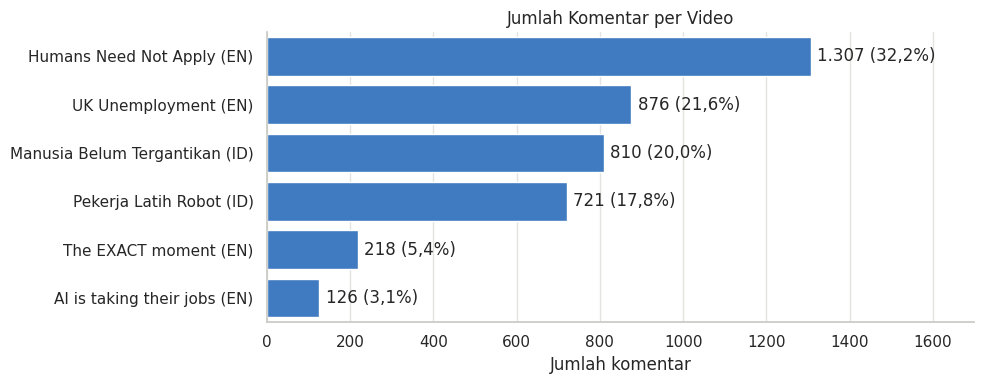

In [ ]:
# 1. Jumlah komentar per video (sudah urut dari terbanyak) beserta persentasenya
jumlah = df["video_title"].value_counts()
persen = (jumlah / len(df) * 100).round(1)
display(pd.DataFrame({"Video": urutan_pendek, "Komentar": jumlah.values, "Persen (%)": persen.values}))

# 2. Grafik batang horizontal
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=jumlah.values, y=urutan_pendek, color=WARNA["utama"], ax=ax)
for i, (n, p) in enumerate(zip(jumlah.values, persen.values)):
    ax.text(n + 15, i, f"{ribuan(n)} ({persen_id(p)}%)", va="center")
ax.set(title="Jumlah Komentar per Video", xlabel="Jumlah komentar", ylabel="")
ax.set_xlim(0, jumlah.max() * 1.3)
sns.despine()
plt.tight_layout()
plt.show()

**Hasil pengecekan:**

Dataset berisi **4.058 komentar** dari 6 video, dengan rincian:

| Video | Komentar | Persen |
|---|---|---|
| *Humans Need Not Apply* (EN) | 1.307 | 32,2% |
| *UK Unemployment* (EN) | 876 | 21,6% |
| *Manusia Belum Tergantikan* (ID) | 810 | 20,0% |
| *Pekerja Latih Robot* (ID) | 721 | 17,8% |
| *The EXACT moment* (EN) | 218 | 5,4% |
| *AI is taking their jobs* (EN) | 126 | 3,1% |

**Temuan:**

1. **Jumlah komentar tidak seimbang.** Video terbanyak (1.307) sekitar 10 kali lebih banyak daripada video tersedikit (126). Tiga video teratas menyumbang 73,8% dari seluruh data.
2. **Dua video berbahasa Indonesia** menyumbang 1.531 komentar (37,7%), sedangkan **empat video berbahasa Inggris** menyumbang 2.527 komentar (62,3%).
3. **Jumlah ini bukan total komentar asli di YouTube.** Pengambilan komentar dibatasi maksimal 1.500 per video (`MAX_COMMENTS_PER_VIDEO` pada skrip *scraping*), lalu dibersihkan pada tahap 3. Karena itu angka di atas dibaca sebagai proporsi data yang kita miliki.

## **4.2 Bahasa Komentar per Video**

**Intinya:** Melihat bahasa komentar di setiap video, memakai kolom `bahasa` hasil deteksi pada 3.14. Satu batang mewakili satu video dan panjang penuhnya adalah 100% komentar video itu. Warna menunjukkan bahasanya.

**Contoh:** Jika sebuah video punya 100 komentar dan 90 di antaranya berbahasa Indonesia, batang biru menempati 90% dari panjang batang.

**Catatan penting:**
- Yang diukur adalah **bahasa komentar**, bukan negara asal penulisnya. Orang Indonesia bisa menulis komentar berbahasa Inggris, dan sebaliknya.
- **Tidak yakin** bukan bahasa ketiga. Itu adalah komentar yang tidak berhasil ditentukan bahasanya oleh detektor, misalnya karena terlalu pendek.
- **Lainnya** menggabungkan bahasa yang jumlahnya sangat sedikit (Spanyol 2, Jerman 1, Vietnam 1).

Jumlah komentar:


bahasa,Indonesia,Inggris,Tidak yakin,Lainnya
video_title,,,,
Humans Need Not Apply (EN),0,1109,196,2
UK Unemployment (EN),0,812,63,1
Manusia Belum Tergantikan (ID),751,17,42,0
Pekerja Latih Robot (ID),681,3,37,0
The EXACT moment (EN),0,201,16,1
AI is taking their jobs (EN),0,124,2,0


Persentase per video (%):


bahasa,Indonesia,Inggris,Tidak yakin,Lainnya
video_title,,,,
Humans Need Not Apply (EN),0.0,84.9,15.0,0.2
UK Unemployment (EN),0.0,92.7,7.2,0.1
Manusia Belum Tergantikan (ID),92.7,2.1,5.2,0.0
Pekerja Latih Robot (ID),94.5,0.4,5.1,0.0
The EXACT moment (EN),0.0,92.2,7.3,0.5
AI is taking their jobs (EN),0.0,98.4,1.6,0.0


Rincian bahasa 'Lainnya': {'Spanyol': 2, 'Jerman': 1, 'Vietnam': 1}


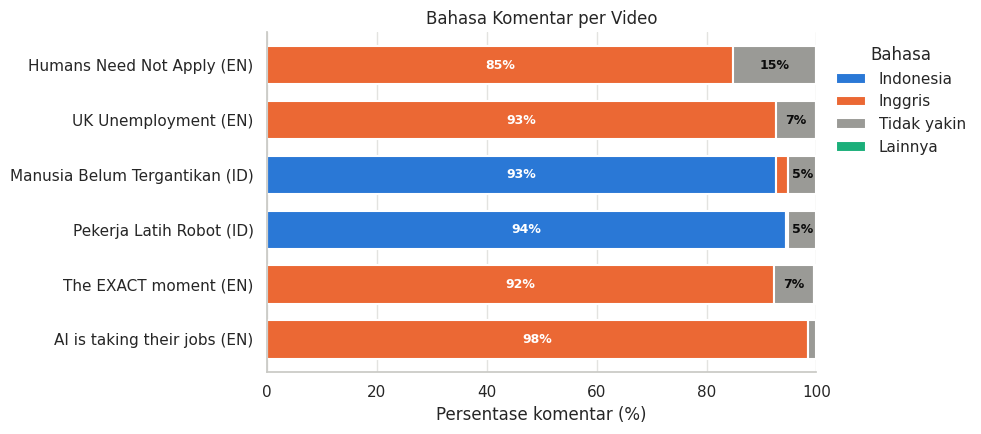

In [ ]:
# 1. Bahasa yang jumlahnya sangat sedikit digabung menjadi "Lainnya"
bahasa = df["bahasa"].where(df["bahasa"].isin(["Indonesia", "Inggris", "Tidak yakin"]), "Lainnya")
kolom = ["Indonesia", "Inggris", "Tidak yakin", "Lainnya"]

# 2. Jumlah dan persentase bahasa di setiap video
jml = pd.crosstab(df["video_title"].map(NAMA_PENDEK), bahasa).reindex(index=urutan_pendek, columns=kolom, fill_value=0)
pct = jml.div(jml.sum(axis=1), axis=0) * 100
print("Jumlah komentar:")
display(jml)
print("Persentase per video (%):")
display(pct.round(1))
print("Rincian bahasa 'Lainnya':", df.loc[bahasa == "Lainnya", "bahasa"].value_counts().to_dict())

# 3. Grafik batang bertumpuk 100%
ax = pct.plot(kind="barh", stacked=True, figsize=(10, 4.5), width=0.7,
              color=[WARNA[k] for k in kolom], edgecolor="white", linewidth=1.5)
for wadah, k in zip(ax.containers, kolom):
    label = [f"{v:.0f}%" if v >= 5 else "" for v in wadah.datavalues]
    ax.bar_label(wadah, labels=label, label_type="center", fontsize=9, fontweight="bold",
                 color="white" if k in ("Indonesia", "Inggris") else "#0b0b0b")
ax.set(title="Bahasa Komentar per Video", xlabel="Persentase komentar (%)", ylabel="", xlim=(0, 100))
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.legend(title="Bahasa", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

**Hasil pengecekan:**

| Video | Indonesia | Inggris | Tidak yakin | Lainnya |
|---|---|---|---|---|
| *Humans Need Not Apply* (EN) | 0 | 1.109 (84,9%) | 196 (15,0%) | 2 |
| *UK Unemployment* (EN) | 0 | 812 (92,7%) | 63 (7,2%) | 1 |
| *Manusia Belum Tergantikan* (ID) | 751 (92,7%) | 17 (2,1%) | 42 (5,2%) | 0 |
| *Pekerja Latih Robot* (ID) | 681 (94,5%) | 3 (0,4%) | 37 (5,1%) | 0 |
| *The EXACT moment* (EN) | 0 | 201 (92,2%) | 16 (7,3%) | 1 |
| *AI is taking their jobs* (EN) | 0 | 124 (98,4%) | 2 (1,6%) | 0 |

**Temuan:**

1. **Bahasa komentar mengikuti bahasa video.** Dua video Indonesia didominasi komentar Indonesia (92,7% dan 94,5%), dan empat video Inggris didominasi komentar Inggris (84,9% sampai 98,4%).
2. **Tidak ada komentar berlabel Indonesia di empat video berbahasa Inggris.** Di sisi lain, ada 17 komentar berbahasa Inggris di video *Manusia Belum Tergantikan* dan 3 di video *Pekerja Latih Robot*, sehingga sebagian penonton Indonesia menulis dalam bahasa Inggris.
3. **Persentase "Tidak yakin" paling tinggi ada di *Humans Need Not Apply* (15,0%).** Video ini juga punya komentar paling pendek (median 13 kata, lihat 4.5), sehingga komentar pendek kemungkinan menjadi penyebabnya.
4. **Bahasa selain Indonesia dan Inggris hanya 4 komentar** (0,1% dari data), sehingga tidak mempengaruhi analisis.

**Dibawa ke tahap berikutnya:** analisis emoji memakai komentar berlabel Indonesia (751 + 681 = **1.432 komentar**). XLM-RoBERTa bersifat multibahasa, sehingga komentar Indonesia dan Inggris dapat dilabeli dengan model yang sama.

## **4.3 Lima Komentar dengan Like Terbanyak per Video**

**Intinya:** Menampilkan 5 komentar yang paling banyak di-like di setiap video. Like menunjukkan penonton lain **setuju** dengan isi komentar tersebut, sehingga komentar ini mewakili pendapat yang didukung banyak orang.

**Contoh:** Komentar dengan 588 like berarti 588 akun menekan tombol suka pada komentar itu. Gagasannya tidak hanya milik satu penulis, tetapi juga didukung ratusan penonton.

**Catatan penting:** Like berarti *setuju*, bukan *positif*. Komentar bernada negatif atau cemas bisa saja memiliki banyak like, dan itu berarti banyak orang yang setuju dengan pandangan negatif tersebut.

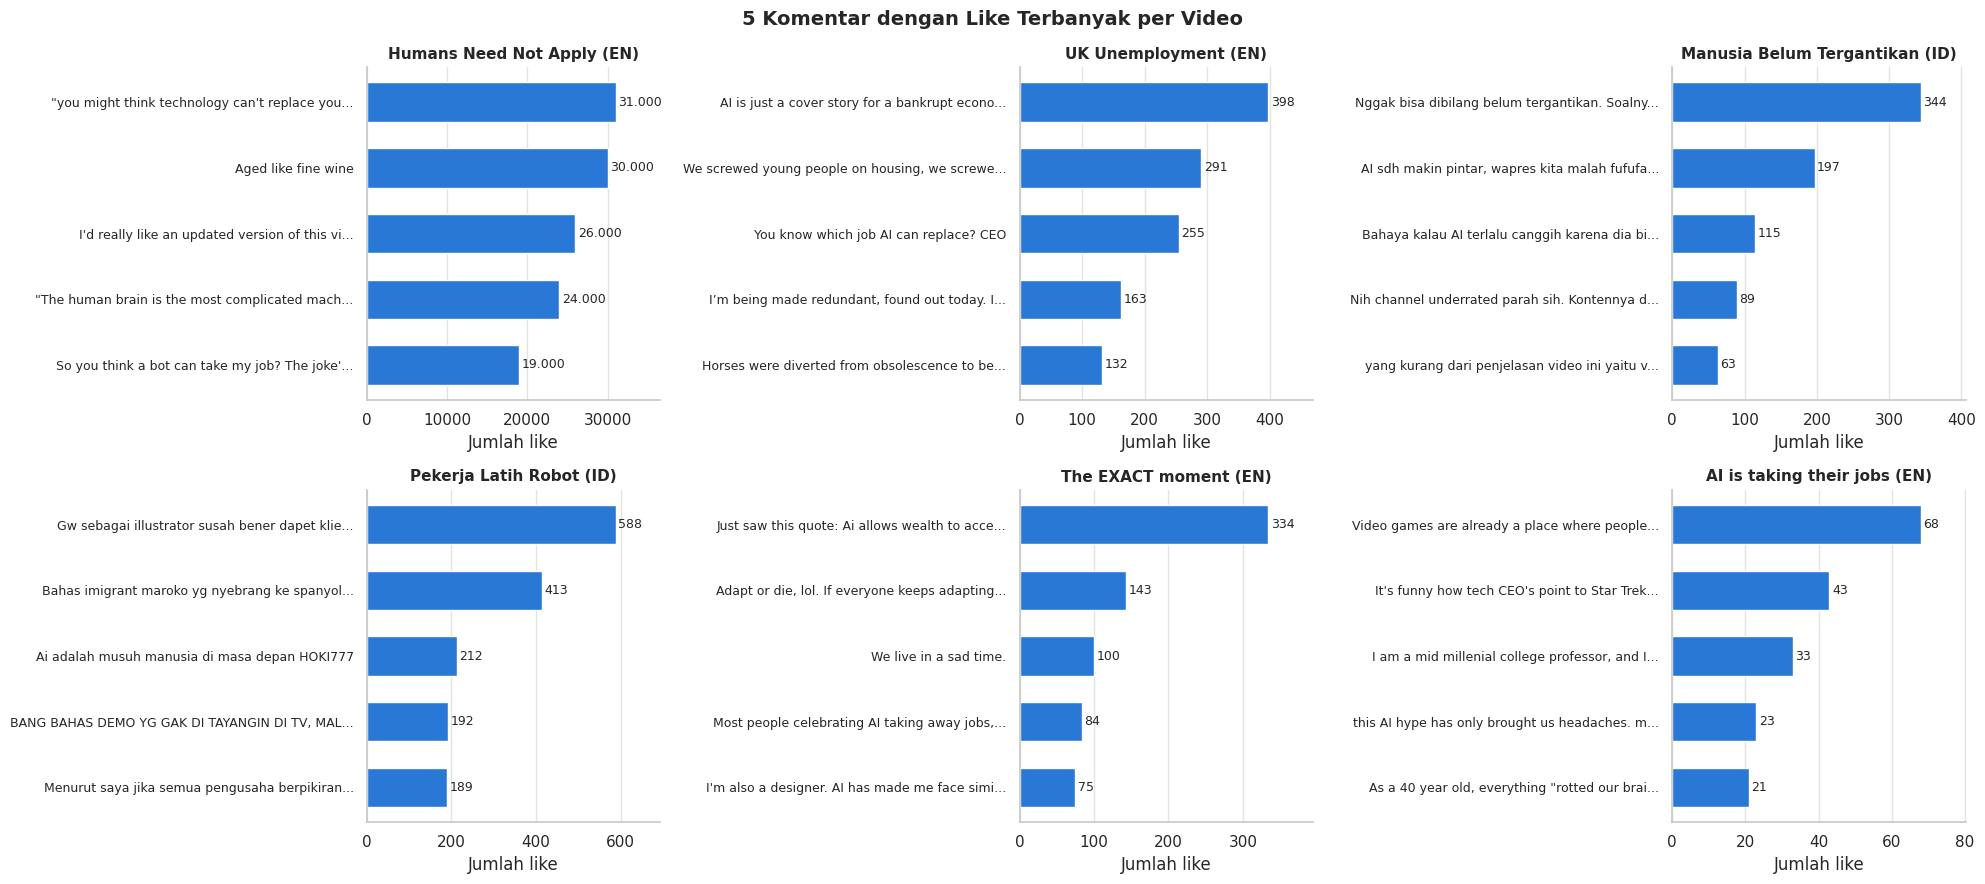


Humans Need Not Apply (EN)
  1. [31.000 like] "you might think technology can't replace your job" I'd be pretty horrified if technology started replacing unemployed peoples jobs.
  2. [30.000 like] Aged like fine wine
  3. [26.000 like] I'd really like an updated version of this video.
  4. [24.000 like] "The human brain is the most complicated machine, perhaps in the whole universe." - Human Brain
  5. [19.000 like] So you think a bot can take my job? The joke's on you, I don't have a job!

UK Unemployment (EN)
  1. [398 like] AI is just a cover story for a bankrupt economic model.""
  2. [291 like] We screwed young people on housing, we screwed them on contracts, we now screwed them with AI 🤣🤣🤣
  3. [255 like] You know which job AI can replace? CEO
  4. [163 like] I’m being made redundant, found out today. I work for an AI based startup and they are automating my job. AI job replacement is real and it’s happening.
  5. [132 like] Horses were diverted from obsolescence to be mobilise

In [ ]:
# 1. Grafik: 5 komentar dengan like terbanyak di setiap video (2 baris x 3 kolom)
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for ax, video in zip(axes.flat, urutan_video):
    top5 = df[df["video_title"] == video].nlargest(5, "likes")
    label = [teks_label(t) for t in top5["comment"]]
    ax.barh(range(5), top5["likes"].values, color=WARNA["utama"], height=0.6)
    ax.set_yticks(range(5))
    ax.set_yticklabels(label, fontsize=9)
    ax.invert_yaxis()
    for i, n in enumerate(top5["likes"].values):
        ax.text(n + top5["likes"].max() * 0.01, i, ribuan(n), va="center", fontsize=9)
    ax.set_xlim(0, top5["likes"].max() * 1.18)
    ax.set_title(NAMA_PENDEK[video], fontsize=11, fontweight="bold")
    ax.set_xlabel("Jumlah like")
    ax.grid(axis="y", visible=False)
sns.despine()
fig.suptitle("5 Komentar dengan Like Terbanyak per Video", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. Teks lengkap (maksimal 250 karakter) dari komentar di atas
for video in urutan_video:
    print(f"\n{NAMA_PENDEK[video]}")
    top5 = df[df["video_title"] == video].nlargest(5, "likes")
    for no, (like, teks) in enumerate(zip(top5["likes"], top5["comment"]), start=1):
        print(f"  {no}. [{ribuan(like)} like] {teks[:250]}{'...' if len(teks) > 250 else ''}")

**Hasil pengecekan:**

| Video | Like komentar teratas | Isi komentar teratas |
|---|---|---|
| *Humans Need Not Apply* (EN) | 31.000 | Mengutip kalimat video bahwa teknologi tidak bisa menggantikan pekerjaan, lalu menyindirnya |
| *Pekerja Latih Robot* (ID) | 588 | Ilustrator yang sulit mendapat klien baru karena orang merasa tidak butuh jasanya |
| *UK Unemployment* (EN) | 398 | AI hanya dijadikan alasan bagi model ekonomi yang bangkrut |
| *Manusia Belum Tergantikan* (ID) | 344 | Teman penulis yang kehilangan pekerjaan sebagai akuntan karena AI |
| *The EXACT moment* (EN) | 334 | Kutipan bahwa AI memberi orang kaya akses ke keahlian, tetapi menutup akses orang berkeahlian ke kekayaan |
| *AI is taking their jobs* (EN) | 68 | Video game sebagai contoh tempat orang menolak produk karena AI |

**Temuan:**

1. **Like antar video tidak bisa dibandingkan langsung.** Lima komentar teratas di *Humans Need Not Apply* memiliki 19.000 sampai 31.000 like, sedangkan komentar teratas di video lain hanya 68 sampai 588 like.
2. **Beberapa komentar teratas berisi pengalaman pribadi tentang dampak AI pada pekerjaan**, misalnya dari ilustrator, akuntan, dan desainer.
3. **Tidak semua komentar teratas membahas topik AI.** Di video *Pekerja Latih Robot*, komentar kedua (413 like) meminta pembuat video membahas imigran Maroko, dan komentar keempat (192 like) meminta membahas demo yang tidak ditayangkan televisi. Keduanya permintaan topik, bukan opini tentang AI.
4. **Satu komentar di video *Pekerja Latih Robot* (212 like) berakhir dengan kata "HOKI777"** dan terlihat seperti promosi judi online yang lolos dari filter pada 3.3. Pencarian kata kunci (hoki, slot, gacor, maxwin, toto) hanya menemukan satu komentar semacam ini, sehingga pengaruhnya pada data sangat kecil.

## **4.4 Sebaran Jumlah Like**

**Intinya:** Mengelompokkan komentar berdasarkan jumlah like-nya (0, 1-5, 6-20, dan seterusnya), lalu menghitung berapa komentar di tiap kelompok. Bedanya dengan 4.3: **4.3 menampilkan komentar mana yang paling banyak disetujui, sedangkan 4.4 menunjukkan bagaimana like tersebar di seluruh komentar.**

**Contoh:** Bayangkan like sebagai uang dan komentar sebagai penduduk kota. Pada 4.3 kita melihat 5 orang terkaya di tiap kecamatan. Pada 4.4 kita melihat foto seluruh kota: berapa orang yang tidak punya uang sama sekali, dan berapa yang sangat kaya.

**Mengapa perlu dilihat:** Like nanti dapat dipakai sebagai tanda seberapa banyak orang setuju dengan sebuah komentar. Jika pembagiannya sangat timpang, satu atau dua komentar bisa mendominasi hasil analisis, sehingga cara pemakaiannya perlu dipikirkan terlebih dahulu.

,Jumlah komentar,Persen (%)
likes,,
0,2133,52.6
1-5,1198,29.5
6-20,365,9.0
21-100,196,4.8
101-1.000,125,3.1
>1.000,41,1.0


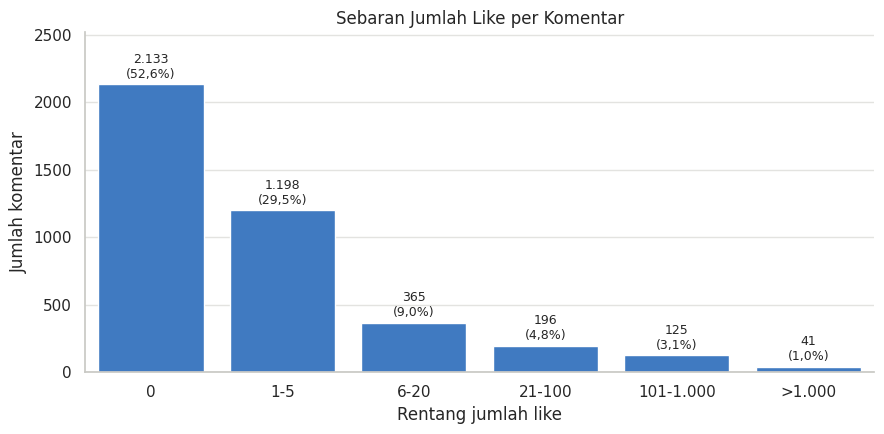

Total like seluruh data      : 367.787
Komentar dengan 0 like       : 52.6%
10 komentar teratas menguasai: 52.1% dari semua like
10% komentar teratas menguasai: 98.5% dari semua like

Total like per video:


,Video,Total like,Persen dari semua like (%)
0,Humans Need Not Apply (EN),357515,97.2
1,UK Unemployment (EN),2925,0.8
2,Manusia Belum Tergantikan (ID),1693,0.5
3,Pekerja Latih Robot (ID),3528,1.0
4,The EXACT moment (EN),1766,0.5
5,AI is taking their jobs (EN),360,0.1


In [ ]:
# 1. Kelompokkan jumlah like ke dalam rentang
batas = [-1, 0, 5, 20, 100, 1000, df["likes"].max()]
nama = ["0", "1-5", "6-20", "21-100", "101-1.000", ">1.000"]
rentang = pd.cut(df["likes"], bins=batas, labels=nama).value_counts().reindex(nama)
persen = (rentang / len(df) * 100).round(1)
display(pd.DataFrame({"Jumlah komentar": rentang, "Persen (%)": persen}))

# 2. Grafik batang
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=nama, y=rentang.values, color=WARNA["utama"], ax=ax)
for i, (n, p) in enumerate(zip(rentang.values, persen.values)):
    ax.text(i, n + rentang.max() * 0.012, f"{ribuan(n)}\n({persen_id(p)}%)", ha="center", va="bottom", fontsize=9)
ax.set(title="Sebaran Jumlah Like per Komentar", xlabel="Rentang jumlah like", ylabel="Jumlah komentar")
ax.set_ylim(0, rentang.max() * 1.18)
ax.grid(axis="x", visible=False)
sns.despine()
plt.tight_layout()
plt.show()

# 3. Seberapa timpang pembagian like
urut = df["likes"].sort_values(ascending=False)
total = df["likes"].sum()
print(f"Total like seluruh data      : {ribuan(total)}")
print(f"Komentar dengan 0 like       : {(df['likes'] == 0).mean() * 100:.1f}%")
print(f"10 komentar teratas menguasai: {urut.head(10).sum() / total * 100:.1f}% dari semua like")
print(f"10% komentar teratas menguasai: {urut.head(int(len(df) * 0.1)).sum() / total * 100:.1f}% dari semua like")

like_video = df.groupby("video_title")["likes"].sum().reindex(urutan_video)
print("\nTotal like per video:")
display(pd.DataFrame({"Video": urutan_pendek, "Total like": like_video.values,
                      "Persen dari semua like (%)": (like_video.values / total * 100).round(1)}))

**Hasil pengecekan:**

| Rentang like | Jumlah komentar | Persen |
|---|---|---|
| 0 | 2.133 | 52,6% |
| 1-5 | 1.198 | 29,5% |
| 6-20 | 365 | 9,0% |
| 21-100 | 196 | 4,8% |
| 101-1.000 | 125 | 3,1% |
| Lebih dari 1.000 | 41 | 1,0% |

**Seberapa timpang:**
- Total like seluruh data adalah **367.787**.
- **52,6%** komentar tidak memiliki like sama sekali.
- **10 komentar teratas** menguasai **52,1%** dari semua like.
- **10% komentar teratas** (405 komentar) menguasai **98,5%** dari semua like.
- Video *Humans Need Not Apply* menyumbang **357.515 like (97,2%)**. Video lain hanya 360 sampai 3.528 like (0,1% sampai 1,0%).

**Temuan:** Like pada data ini sangat timpang, baik antar komentar maupun antar video. Ketimpangan antar video kemungkinan besar disebabkan oleh ukuran video itu sendiri (video yang lebih besar dan lebih lama tayang mendapat lebih banyak like), bukan karena penontonnya lebih setuju.

**Dibawa ke tahap berikutnya:**
- Di dalam **satu video**, like dipakai apa adanya sebagai tanda setuju. Contohnya sebagai bobot saat menghitung proporsi sentimen per video.
- Saat **menggabungkan video**, like perlu dinormalkan per video agar satu video tidak mendominasi.
- Saat **melatih classifier**, like perlu diperkecil dengan transformasi log (`log1p`) sebelum dipakai sebagai `sample_weight`. Langkah ini dikerjakan pada notebook Classifier, bukan di sini.

## **4.5 Panjang Komentar per Video**

**Intinya:** Menghitung jumlah kata di setiap komentar, lalu membandingkannya antar video. Informasi ini penting karena model seperti XLM-RoBERTa hanya membaca teks sampai panjang tertentu (`max_length`) dan memotong sisanya.

**Contoh:** Komentar `Aged like fine wine` terdiri dari 4 kata. Komentar yang menceritakan pengalaman kerja panjang bisa mencapai ratusan kata.

**Cara membaca boxplot:** Kotak berisi separuh komentar yang berada di tengah. Garis di dalam kotak adalah nilai tengah (median). Garis yang keluar dari kotak menunjukkan rentang wajar, dan komentar yang sangat panjang (pencilan) tidak ditampilkan agar grafik tetap terbaca. Garis putus-putus menandai batas 95% komentar.

,count,mean,std,min,50%,90%,95%,99%,max
jumlah kata,4058.0,29.8,38.0,3.0,17.0,69.0,98.0,184.3,501.0


Komentar dengan paling banyak 100 kata: 95.2%

Median jumlah kata per video:


,median kata
video,
Humans Need Not Apply (EN),13.0
UK Unemployment (EN),22.0
Manusia Belum Tergantikan (ID),16.0
Pekerja Latih Robot (ID),17.0
The EXACT moment (EN),30.0
AI is taking their jobs (EN),33.5


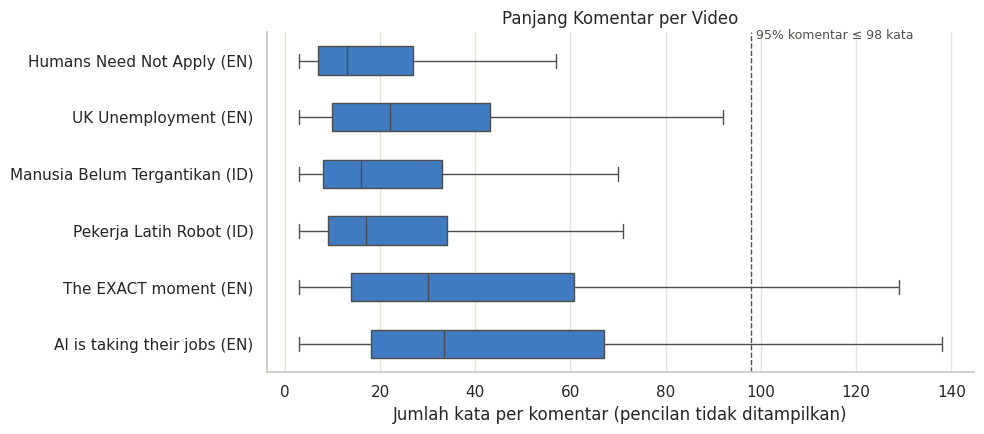

In [ ]:
# 1. Hitung jumlah kata tiap komentar (kolom sementara, df tidak diubah)
df_len = df.assign(kata=df["comment"].str.split().str.len(), video=df["video_title"].map(NAMA_PENDEK))

# 2. Ringkasan jumlah kata
display(df_len["kata"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1).to_frame("jumlah kata").T)
p95 = df_len["kata"].quantile(0.95)
print(f"Komentar dengan paling banyak 100 kata: {(df_len['kata'] <= 100).mean() * 100:.1f}%")
print("\nMedian jumlah kata per video:")
display(df_len.groupby("video")["kata"].median().reindex(urutan_pendek).to_frame("median kata"))

# 3. Boxplot per video
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df_len, x="kata", y="video", order=urutan_pendek, color=WARNA["utama"],
            showfliers=False, width=0.5, linewidth=1, ax=ax)
ax.axvline(p95, color="#52514e", linestyle="--", linewidth=1)
ax.text(p95 + 1, -0.45, f"95% komentar ≤ {p95:.0f} kata", fontsize=9, color="#52514e", va="center")
ax.set(title="Panjang Komentar per Video", xlabel="Jumlah kata per komentar (pencilan tidak ditampilkan)", ylabel="")
ax.grid(axis="y", visible=False)
sns.despine()
plt.tight_layout()
plt.show()

**Hasil pengecekan:**

| Ukuran | Jumlah kata |
|---|---|
| Terpendek | 3 |
| Median (nilai tengah) | 17 |
| Rata-rata | 29,8 |
| 90% komentar paling banyak | 69 |
| 95% komentar paling banyak | 98 |
| 99% komentar paling banyak | 184 |
| Terpanjang | 501 |

Median jumlah kata per video: *AI is taking their jobs* 33,5, *The EXACT moment* 30, *UK Unemployment* 22, *Pekerja Latih Robot* 17, *Manusia Belum Tergantikan* 16, dan *Humans Need Not Apply* 13.

**Temuan:**

1. **Kebanyakan komentar pendek.** Separuh komentar hanya 17 kata atau kurang, dan 95,2% komentar tidak lebih dari 100 kata. Jumlah terpendek 3 kata karena komentar yang lebih pendek sudah dihapus pada 3.8.
2. **Panjang komentar berbeda antar video.** Komentar di *AI is taking their jobs* dan *The EXACT moment* cenderung lebih panjang, sedangkan komentar di *Humans Need Not Apply* paling pendek.
3. **Sedikit komentar yang sangat panjang.** Hanya 1% komentar yang lebih dari 184 kata, dan yang terpanjang 501 kata.

**Dibawa ke tahap berikutnya:** satu kata bisa dipecah menjadi lebih dari satu *token* oleh model, sehingga `max_length` ditentukan dengan mengukur token langsung memakai *tokenizer* XLM-RoBERTa pada tahap pelabelan. Karena 95,2% komentar tidak lebih dari 100 kata, komentar yang terpotong diperkirakan sedikit.

### **Ringkasan EDA Sebelum Modeling**

| Temuan | Artinya untuk tahap berikutnya |
|---|---|
| Jumlah komentar tidak seimbang antar video (126 sampai 1.307) | Hasil antar video dibaca sebagai proporsi, bukan jumlah mentah |
| Bahasa komentar mengikuti bahasa video (1.432 komentar Indonesia, 2.266 Inggris) | Analisis emoji memakai komentar berlabel Indonesia, dan XLM-RoBERTa multibahasa dapat dipakai untuk keduanya |
| Like sangat timpang, 97,2% berasal dari satu video | Like dipakai apa adanya dalam satu video, dinormalkan saat video digabung, dan diperkecil dengan `log1p` saat melatih classifier |
| 95,2% komentar tidak lebih dari 100 kata | `max_length` XLM-RoBERTa diukur dengan tokenizer pada tahap pelabelan |
| Ada satu komentar yang terlihat seperti promosi judi online ("HOKI777") | Dicatat, pengaruhnya sangat kecil pada data |

# **5. Labeling Sentimen dengan Model Pre-trained**

> ## ✏️ PERLU DIPERBARUI
>
> **Judul:** Gambaran Umum Bab 5
>
> **Isi:** Tabel ringkasan dua percobaan otomatis dan pelabelan akhir.
>
> **Yang diubah:** Tulis ulang setelah sel-sel percobaan dihapus: cukup jelaskan bahwa Bab 5 berisi data bersih, label acuan, dan pelabelan akhir dengan LLM.


### **Gambaran Umum Bab 5: Dua Percobaan Otomatis, lalu Pelabelan Akhir**

| Bagian | Isi | Hasil pada komentar acuan |
|---|---|---|
| 5.1 sampai 5.6 | **Percobaan 1.** Zero-shot NLI dengan mDeBERTa-v3 dan tiga rumusan kalimat | Lihat tabel 5.6 |
| 5.7 sampai 5.8 | **Percobaan 2.** Model sentimen yang dilatih khusus (RoBERTa Indonesia dan Inggris) | Lihat tabel 5.8 |
| 5.9 | **Pelabelan akhir.** Seluruh komentar dilabeli dengan membaca isinya satu per satu | Menjadi label untuk klasifikasi |

Sebagai pembanding, menebak semua komentar sebagai netral sudah menjadi tolok ukur sederhana (tabel 5.8). Kedua percobaan otomatis belum jauh melampauinya, sehingga hasilnya terlalu lemah untuk dijadikan label latih. Itulah alasan pelabelan akhir di 5.9. Kedua percobaan tetap disimpan sebagai bukti mengapa kami berpindah cara.

> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** Pengantar Percobaan 1 (zero-shot NLI)
>
> **Cakupan:** 1 sel di bawah ini (hanya satu sel)
>
> **Isi:** Teks pengantar yang menjelaskan zero-shot classification dengan mDeBERTa-v3.
>
> **Alasan:** Ikut dihapus bersama percobaan NLI (5.2 sampai 5.4).


**Percobaan 1 (5.1 sampai 5.6): Pelabelan Sentimen Otomatis dengan Zero-Shot Classification menggunakan mDeBERTa-v3**

Pada tahap ini, kita akan memberikan label sikap (Positif, Negatif, atau Netral) pada setiap komentar secara otomatis. Karena dataset ini belum memiliki label bawaan dari awal, kita menggunakan teknik yang disebut Zero-Shot Classification. Artinya, kita meminta model AI untuk menebak label tanpa perlu melatihnya dari nol menggunakan data kita.

Mengapa menggunakan model mDeBERTa-v3?
1. Mendukung bahasa Indonesia dan Inggris sekaligus: Berdasarkan temuan EDA sebelumnya, dataset kita adalah gabungan komentar berbahasa Indonesia (1.432 baris) dan bahasa Inggris (2.266 baris). Model `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` dilatih awal pada teks 100 bahasa, lalu dilatih ulang untuk tugas NLI pada data 26 bahasa yang mencakup bahasa Indonesia. Dengan begitu semua komentar dapat diproses sekaligus tanpa memisahkan dataset berdasarkan bahasanya.

2. Cocok untuk Zero-Shot: Model ini menilai apakah sebuah kalimat (misalnya "Penulis khawatir atau menolak AI.") sejalan dengan isi komentar, sehingga kita bisa menentukan label hanya dengan menuliskan kalimat sikapnya.

3. Komputasi yang Efisien: Ukuran modelnya tergolong kecil (versi *base*), dan 95,2% komentar dalam dataset ini panjangnya kurang dari 100 kata, sehingga pemrosesan berjalan cepat dan tidak membebani memori (RAM) secara berlebihan.

**Penjelasan Mudah Alur Kerja Pelabelan:**

Setiap komentar dimasukkan ke dalam pipeline klasifikasi. Model membaca teks tersebut, menghitung probabilitas (peluang) untuk masing-masing kalimat sikap, lalu memilih kalimat dengan skor tertinggi sebagai hasil akhirnya.

**Perbaikan dari Percobaan Pertama:**

Percobaan pertama memakai model XLM-RoBERTa dan kandidat label satu kata (*positif*, *negatif*, *netral*). Hasilnya kurang sesuai: hanya 231 dari 4.058 komentar (5,7%) yang berlabel netral, padahal banyak komentar berupa pertanyaan atau candaan. Model juga menilai nada kata, bukan sikap terhadap AI, sehingga komentar seperti *"Mustahil bro Robot AI menghancurkan peradaban"* (yang sebenarnya pro-AI) dilabeli negatif. Selain itu, data NLI XLM-RoBERTa tidak memuat bahasa Indonesia. Karena itu model diganti dengan mDeBERTa-v3, dan kandidat label diganti dengan **kalimat sikap terhadap AI**, misalnya *"Penulis mendukung atau optimis terhadap AI."*

**Cara Kami Menjaga Mutu Label (Tanpa Pelabelan Manual):**

Setiap komentar dilabeli dengan 3 rumusan kalimat sikap (A, B, C), sehingga ada **3 suara** per komentar.

| Rumusan | Bahasa | Fokus |
|---|---|---|
| A | Inggris | mendukung/optimis, khawatir/menolak, tidak menunjukkan sikap |
| B | Indonesia | isi yang sama dengan A, ditulis dalam bahasa Indonesia |
| C | Inggris | dampak AI bagi orang dan pekerjaan: baik, buruk, tanpa pendapat |

| Kondisi | Hasil | Dipakai? |
|---|---|---|
| Minimal 2 dari 3 suara sama **dan** rata-rata skor keyakinan 0,6 atau lebih | label tersebut | Ya |
| Selain itu | *tidak yakin* | Tidak untuk melatih model |

Batas skor 0,6 ditentukan dari pengamatan hasil percobaan pertama: komentar dengan skor di bawah 0,6 yang kami baca hampir semuanya tidak memuat sikap yang jelas. Nilainya dapat diubah pada `AMBANG_SKOR`. Aturan ini mengukur **kestabilan** label terhadap pergantian kalimat, bukan akurasi, karena kami tidak memiliki label manual sebagai pembanding.

> ## ✅ DIPERTAHANKAN
>
> **Judul:** 5.1 Memuat dataset bersih
>
> **Isi:** Membaca `youtube_comments_clean.csv` (4.058 komentar) ke `df_clean` (2 sel).
>
> **Alasan:** Data awal untuk bagian pelabelan.


## **5.1 Memuat Dataset Bersih**

Langkah ini membaca hasil preprocessing (`youtube_comments_clean.csv`) yang dibuat pada tahap 3.16. Lokasi berkas dicari otomatis, baik di Google Colab maupun di komputer lokal.

In [ ]:
import os

# Lokasi dataset bersih: otomatis deteksi Colab vs Antigravity / Lokal
for lokasi in ['/content/youtube_comments_clean.csv', '../../datasets/youtube_comments_clean.csv',
               'datasets/youtube_comments_clean.csv', 'youtube_comments_clean.csv']:
    if os.path.exists(lokasi):
        FILE_BERSIH = lokasi
        break
else:
    raise FileNotFoundError('youtube_comments_clean.csv tidak ditemukan. Jalankan tahap 3.16 atau unggah berkasnya.')

df_clean = pd.read_csv(FILE_BERSIH)
print(f'Dataset dimuat dari {FILE_BERSIH}: {len(df_clean)} komentar, kolom: {df_clean.columns.tolist()}')
df_clean.head()

Dataset dimuat dari /content/youtube_comments_clean.csv: 4058 komentar, kolom: ['video_title', 'comment', 'likes', 'bahasa']


,video_title,comment,likes,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,Indonesia


> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** 5.2 sampai 5.4, Percobaan 1: zero-shot NLI mDeBERTa
>
> **Cakupan:** 6 sel di bawah ini
>
> **Isi:** Melabeli 4.058 komentar dengan mDeBERTa-v3 memakai tiga rumusan kalimat, voting, ambang skor, contoh per label, dan menyimpan `youtube_comments_labeled_nli.csv`.
>
> **Alasan:** Percobaan ini gagal (akurasi 42% sampai 50% terhadap acuan), dan klasifikasi membaca `hasil_dari_LLM_qwen.csv`, bukan hasil bagian ini.


## **5.2 Pelabelan dengan mDeBERTa-v3 dan Tiga Rumusan Kalimat**

Langkah ini memuat model `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`, lalu melabeli seluruh komentar dengan tiga rumusan kalimat sikap. Hasilnya 3 label dan 3 skor keyakinan untuk setiap komentar.

Setelah itu kolom `sentiment` diisi dengan voting:
1. Label yang paling banyak muncul dari 3 suara dipilih. Jika ketiganya berbeda (kurang dari `MIN_SUARA`), hasilnya *tidak yakin*.
2. Kolom `suara_sama` mencatat jumlah suara yang sama dengan label terpilih, dan `skor_rata` adalah rata-rata skor suara tersebut.
3. Jika `skor_rata` kurang dari `AMBANG_SKOR`, hasilnya juga *tidak yakin*. Label sebelum penyaringan skor disimpan di kolom `sentiment_mentah`.

Tidak ada `try/except` kosong, sehingga komentar yang gagal diproses akan memunculkan error dan tidak diam-diam berubah menjadi label palsu.

In [ ]:
AMBANG_SKOR = 0.6   # skor_rata di bawah ini dianggap tidak yakin
MIN_SUARA = 2       # minimal suara yang sama dari 3 suara
MODEL_REPO = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"

URUT = ["positif", "negatif", "netral"]
# Tiga rumusan kalimat sikap terhadap AI, urutannya selalu: mendukung, menolak, tanpa sikap
VARIAN = {
    "A": ["The author supports or is optimistic about AI.",
          "The author is worried about or opposes AI.",
          "The author shows no clear opinion about AI."],
    "B": ["Penulis mendukung atau optimis terhadap AI.",
          "Penulis khawatir atau menolak AI.",
          "Penulis tidak menunjukkan sikap yang jelas terhadap AI."],
    "C": ["The author thinks AI is good for people and jobs.",
          "The author thinks AI is bad for people and jobs.",
          "The author does not express an opinion about AI and jobs."],
}

classifier = pipeline("zero-shot-classification", model=MODEL_REPO,
                      device=0 if torch.cuda.is_available() else -1)

def labeli(teks, kode, ukuran_potongan=256):
    kalimat = VARIAN[kode]
    peta = dict(zip(kalimat, URUT))
    pred, skor = [], []
    for i in tqdm(range(0, len(teks), ukuran_potongan), desc=f"Rumusan {kode}"):
        hasil = classifier(teks[i:i + ukuran_potongan], kalimat, hypothesis_template="{}",
                           truncation=True, max_length=128, batch_size=16)
        pred += [peta[h["labels"][0]] for h in hasil]
        skor += [round(float(h["scores"][0]), 3) for h in hasil]
    return pred, skor

teks = df_clean["comment"].tolist()
for kode in VARIAN:
    df_clean[f"label_{kode}"], df_clean[f"skor_{kode}"] = labeli(teks, kode)

# Voting dari 3 suara
KOLOM_LABEL = [f"label_{k}" for k in VARIAN]
KOLOM_SKOR = [f"skor_{k}" for k in VARIAN]
mentah, suara, rata = [], [], []
for lab, sk in zip(df_clean[KOLOM_LABEL].to_numpy(), df_clean[KOLOM_SKOR].to_numpy()):
    label, jumlah = Counter(lab).most_common(1)[0]
    suara.append(jumlah)
    if jumlah < MIN_SUARA:
        mentah.append("tidak yakin"); rata.append(np.nan)
    else:
        mentah.append(label)
        rata.append(round(float(np.mean([s for l, s in zip(lab, sk) if l == label])), 3))
df_clean["sentiment_mentah"] = mentah
df_clean["suara_sama"] = suara
df_clean["skor_rata"] = rata
df_clean["sentiment"] = np.where((df_clean["sentiment_mentah"] != "tidak yakin") & (df_clean["skor_rata"] >= AMBANG_SKOR),
                                 df_clean["sentiment_mentah"], "tidak yakin")
print(df_clean["sentiment"].value_counts().to_string())
df_clean[["comment", "label_A", "label_B", "label_C", "sentiment", "suara_sama", "skor_rata"]].head(10)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Rumusan C: 100%|██████████| 16/16 [00:45<00:00,  2.83s/it]

sentiment
tidak yakin    1725
positif        1159
negatif         907
netral          267


,comment,label_A,label_B,label_C,sentiment,suara_sama,skor_rata
0,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,positif,positif,netral,tidak yakin,2,0.481
1,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",negatif,positif,negatif,negatif,2,0.806
2,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",negatif,negatif,negatif,negatif,3,0.966
3,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",negatif,negatif,positif,negatif,2,0.859
4,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,positif,negatif,negatif,tidak yakin,2,0.482
5,"Tokopedia hanya memanfaatkan market konsumen Indonesia, mereka gak mau mempekerjakan banyak orang Indonesia, lebih baik netizen Indonesi...",positif,netral,positif,positif,2,0.742
6,gw berani taruhan kalo dampak buruk AI lebih banyak ketimbang manfaatnya,negatif,negatif,negatif,negatif,3,0.843
7,"Bukan hanya AI yang mengubah dunia kerja, aplikasi online juga telah mengubah hampir semua bidang usaha. Jual beli kini banyak berpindah...",positif,netral,positif,positif,2,0.736
8,Harvest Moon : Back to Nature wkwkwkw. mancing nyangkul bertani solusinya,positif,positif,positif,positif,3,0.620
9,"BANG BAHAS DEMO YG GAK DI TAYANGIN DI TV, MALAH BUZZER PADA NGIRIM MEME DOKSLI",positif,positif,positif,tidak yakin,3,0.477


## **5.3 Seberapa Stabil Label dari Tiga Rumusan**

Tanpa label manual, kita tidak bisa menghitung akurasi. Yang bisa diukur adalah **kestabilan**: apakah label tetap sama ketika kalimat sikap diganti. Lima tabel di bawah menunjukkan (1) berapa suara dari 3 yang sama, (2) kestabilan per bahasa, (3) kecocokan setiap pasangan rumusan, (4) sebaran label, dan (5) berapa komentar yang bertahan pada berbagai batas skor. Tabel ke-5 dipakai untuk menilai apakah `AMBANG_SKOR = 0,6` terlalu ketat atau terlalu longgar. Jika satu rumusan hampir tidak pernah memilih *netral* atau sering berbeda dari dua lainnya, itu tanda kalimatnya kurang cocok.

In [ ]:
URUTAN = ["positif", "negatif", "netral", "tidak yakin"]
NAMA_SUARA = {3: "3 suara sama", 2: "2 dari 3 sama"}
URUTAN_KES = list(NAMA_SUARA.values()) + ["Ketiganya beda"]
kes = df_clean["suara_sama"].map(lambda n: NAMA_SUARA.get(n, "Ketiganya beda"))

# 1. Jumlah suara yang sama
tabel_kes = kes.value_counts().reindex(URUTAN_KES).fillna(0).astype(int).to_frame("Jumlah komentar")
tabel_kes["Persen"] = (tabel_kes["Jumlah komentar"] / len(df_clean) * 100).round(1)
print("1. Jumlah suara yang sama dari 3 suara")
display(tabel_kes)

# 2. Kestabilan per bahasa (persen)
print("\n2. Kestabilan per bahasa (%)")
display((pd.crosstab(df_clean["bahasa"], kes, normalize="index") * 100).round(1)
        .reindex(columns=URUTAN_KES).fillna(0))

# 3. Kecocokan setiap pasangan rumusan (%)
print("\n3. Kecocokan pasangan rumusan (%)")
pasangan = {f"{a} vs {b}": round((df_clean[f"label_{a}"] == df_clean[f"label_{b}"]).mean() * 100, 1)
            for a, b in [("A", "B"), ("A", "C"), ("B", "C")]}
display(pd.Series(pasangan, name="Cocok (%)").to_frame())

# 4. Sebaran label tiap rumusan dan hasil voting
print("\n4. Sebaran label")
kolom = {k: df_clean[f"label_{k}"].value_counts() for k in VARIAN}
kolom["Voting (mentah)"] = df_clean["sentiment_mentah"].value_counts()
kolom["Final"] = df_clean["sentiment"].value_counts()
display(pd.DataFrame(kolom).reindex(URUTAN).fillna(0).astype(int))

# 5. Komentar yang bertahan pada berbagai batas skor
print("\n5. Komentar yang bertahan menurut batas skor (dari voting mentah)")
baris = []
for t in [0.0, 0.5, 0.6, 0.7, 0.8]:
    d = df_clean[(df_clean["sentiment_mentah"] != "tidak yakin") & (df_clean["skor_rata"] >= t)]
    baris.append({"Skor minimal": t, "Komentar": len(d), "Persen": round(len(d) / len(df_clean) * 100, 1),
                  **d["sentiment_mentah"].value_counts().reindex(["positif", "negatif", "netral"]).fillna(0).astype(int).to_dict()})
display(pd.DataFrame(baris))

1. Jumlah suara yang sama dari 3 suara


,Jumlah komentar,Persen
suara_sama,,
3 suara sama,1538,37.9
2 dari 3 sama,2127,52.4
Ketiganya beda,393,9.7



2. Kestabilan per bahasa (%)


suara_sama,3 suara sama,2 dari 3 sama,Ketiganya beda
bahasa,,,
Indonesia,41.0,50.2,8.8
Inggris,35.0,54.4,10.6
Jerman,100.0,0.0,0.0
Spanyol,100.0,0.0,0.0
Tidak yakin,43.3,49.2,7.6
Vietnam,100.0,0.0,0.0



3. Kecocokan pasangan rumusan (%)


,Cocok (%)
A vs B,54.7
A vs C,56.9
B vs C,54.5



4. Sebaran label


,A,B,C,Voting (mentah),Final
positif,2558,1160,1269,1622,1159
negatif,1250,1412,1900,1423,907
netral,250,1486,889,620,267
tidak yakin,0,0,0,393,1725



5. Komentar yang bertahan menurut batas skor (dari voting mentah)


,Skor minimal,Komentar,Persen,positif,negatif,netral
0,0.0,3665,90.3,1622,1423,620
1,0.5,3208,79.1,1509,1230,469
2,0.6,2333,57.5,1159,907,267
3,0.7,1400,34.5,694,597,109
4,0.8,686,16.9,344,302,40


## **5.4 Memeriksa Contoh dan Menyimpan Hasil**

Langkah ini menampilkan 8 contoh komentar acak untuk setiap label akhir, ditambah contoh yang diberi label *tidak yakin*, supaya hasilnya bisa diperiksa dengan membaca langsung. Setelah itu hasil percobaan ini disimpan ke `youtube_comments_labeled_nli.csv` sebagai arsip. Berkas itu **bukan** label akhir: label akhir untuk klasifikasi dibuat di 5.9 dan disimpan di `youtube_comments_labeled.csv`.

In [ ]:
pd.set_option("display.max_colwidth", 140)

for label in ["positif", "negatif", "netral", "tidak yakin"]:
    d = df_clean[df_clean["sentiment"] == label]
    print(f"\nContoh komentar berlabel {label} ({len(d)} komentar):")
    kolom_tampil = ["comment", "suara_sama", "skor_rata"]
    display(d.sample(min(8, len(d)), random_state=42)[kolom_tampil])

# Lokasi berkas hasil: otomatis deteksi Colab (/content) vs Antigravity / Lokal
if os.path.exists('/content'):
    FILE_LABEL = '/content/youtube_comments_labeled_nli.csv'
elif os.path.exists('../../datasets'):
    FILE_LABEL = '../../datasets/youtube_comments_labeled_nli.csv'
elif os.path.exists('datasets'):
    FILE_LABEL = 'datasets/youtube_comments_labeled_nli.csv'
else:
    FILE_LABEL = 'youtube_comments_labeled_nli.csv'

df_clean.to_csv(FILE_LABEL, index=False, encoding='utf-8')
df_cek = pd.read_csv(FILE_LABEL)
print(f'\n✅ Hasil percobaan 1 disimpan ke: {FILE_LABEL}')
print(f'✅ Jumlah baris: {len(df_cek)}, jumlah kolom: {df_cek.shape[1]}, baris tanpa label: {df_cek["sentiment"].isna().sum()}')


Contoh komentar berlabel positif (1159 komentar):


,comment,suara_sama,skor_rata
3579,Krishnan’s suit is at the dry cleaner’s today,2,0.602
909,Karyawan menggunakan AI itu seperti menggali kuburan sendiri (pada banyak jenis pekerjaan). Makin AI digunakan akan membuat AI makin pin...,2,0.926
362,"Jangan jauh2 ke india, di Indonesia di kota saya aja banyak mall dan toko2 elektronik. Buat banner atau iklan di sosmed nya aja selalu p...",2,0.780
998,saya g tahu bisa meluncur kesini. tapi mantep sih kontenynya... subs bro...,3,0.692
2446,+Phil A except in Japan,3,0.662
540,Profesi yang akan bertahan di era AI 1. Pertanian dan Perkebunan 2. Perikanan 3. Pakar dan Ahli di bidang AI,3,0.828
2345,"In time, yes.",3,0.654
1858,Volunteer for testing today!,3,0.772



Contoh komentar berlabel negatif (907 komentar):


,comment,suara_sama,skor_rata
3961,"I know... Is this our first real-world SCP? We need to contain this sucker quick, then neutralize it completely. Unfortunately, I think ...",2,0.768
2191,"actually, as someone who also doesn't have a job to be taken from them, i watch this and think ""hmm this might be the best thing for soc...",2,0.712
1436,Ai harus kita tolak... boikot AI...,3,0.880
3547,They don't bring in billions. They cost the taxpayer when all is considered.,2,0.663
3692,Hugely primitive discussion on employment and work. Rudimentary and basic. It talks about workers as automatons. And yet their fear is r...,2,0.715
3855,Long story short: doomsday is coming,3,0.672
2769,"""And probably yes, computers will be able to think deeper and more far than us"" They won't, though. This is some popular science-fiction...",2,0.839
1095,Takut bgt AI aktifin peluru kendali. Dan karena robot jadi secara human rights gak bisa disanksi.,3,0.895



Contoh komentar berlabel netral (267 komentar):


,comment,suara_sama,skor_rata
1672,"Or that robots will replace people who are ""in between jobs""",2,0.629
1008,"Ini hanya bagian dari Evolusi peradaban manusia. Saya yakin apapun di dunia ini selalu ada ""batas""nya secara alami.",2,0.697
2778,PlastiqueOrgane not really and definitely not because of automation (anytime soon ),2,0.641
3425,"I think people aren't joining dots. And also don't understand the speed of change. There's a difference between CAPABILITY of AI, and ho...",2,0.867
2734,There’s actually sex robots now,2,0.603
3255,things have their cycles in life. You will understand,3,0.656
1322,1:44 jawabannya adlh bos² konoha blm mengerti ai. 😂😂😂😂,3,0.647
3936,"About 3-4 days ago, China's high court just made a decision that companies CANNOT fire or lay off employees just for the purpose of repl...",3,0.709



Contoh komentar berlabel tidak yakin (1725 komentar):


,comment,suara_sama,skor_rata
824,"maksud fufufafa apa ya? wapres kita malah ga keluar sifat fufufafanya, padahal pidato presiden suka ngawur tuh. Btw jokesmu basi",2,0.442
1428,lama2 ahli Matematika hanya gaji UMR?,1,NaN
755,ternak jangkrik bng,2,0.502
3477,I think deficits will get worse anyway. Think about it the sector that benefitted from all this govt spending was technology. Along with...,2,0.532
1074,"Setelah video ini muncul, nanti AI akan membuat solusi untuk ini juga wkwkwk",2,0.497
2942,What brush are u using?? Also great video I relate so much :(,3,0.516
47,"Perusahaan tidak akan bangkrut, manusialah yg akan berkurang",1,NaN
1976,Especially since his first specific example went out of business.,2,0.559



✅ Hasil percobaan 1 disimpan ke: /content/youtube_comments_labeled_nli.csv
✅ Jumlah baris: 4058, jumlah kolom: 14, baris tanpa label: 0


> ## ✅ DIPERTAHANKAN
>
> **Judul:** 5.5 Label acuan
>
> **Isi:** Memuat 100 komentar acuan dari `comments_relabeled.csv`, mencocokkannya ke data bersih, dan menampilkan sebaran label dan bahasa (2 sel).
>
> **Alasan:** Evaluasi LLM memakai label acuan ini, jadi asal dan arti labelnya perlu dijelaskan di laporan.


## **5.5 Validasi Manual: Menyiapkan Label Acuan**

Voting dan skor keyakinan hanya mengukur kestabilan. Untuk mengetahui ketepatan, hasil model dibandingkan dengan label acuan. Label acuan diambil dari berkas `comments_relabeled.csv`, yang berisi **100 komentar** dengan label pada kolom `label_manual_expert` (di kode dinamai `label_manual`). Berkas ini **tidak memuat label model**, sehingga pelabelan tidak terpengaruh hasil model. Tiap komentar dicocokkan ke data bersih berdasarkan isinya untuk mendapatkan nomor baris (`id`) dan bahasanya. Komentar yang tidak ditemukan di data bersih dilewati.

Pada komentar yang ambigu (sindiran, sikap campuran), penilaian orang lain bisa berbeda, jadi ketepatan di bawah ini berarti kecocokan dengan label acuan ini, bukan kebenaran mutlak.

**Definisi label acuan: sikap terhadap AI.** Label acuan mengikuti aturan yang sama dengan prompt Qwen pada pelabelan akhir di bawah, yang **berlawanan** dengan arti sentimen sehari-hari:

| Label | Arti pada label acuan |
|---|---|
| positif | penulis **khawatir**, takut, mengeluh, atau menganggap AI buruk bagi pekerjaan manusia |
| negatif | penulis **mendukung** AI atau menganggapnya berguna |
| netral | di luar konteks, spam, hanya berterima kasih, atau tidak jelas |

Perhatikan bahwa "positif" di sini berarti khawatir terhadap AI. Karena itu kecocokan Qwen dengan label acuan tampak rendah (54%): keluaran Qwen ternyata mengikuti arah sentimen biasa (positif = mendukung AI). Bila arah label Qwen disesuaikan dengan label acuan, kecocokannya sekitar 66% pada 98 komentar acuan yang cocok. Penjelasan lengkap ada pada catatan pelabelan akhir di bawah dan di Bab 6.1.

Berkas `comments_relabeled.csv` diunggah ke Colab (`/content`) atau diletakkan di folder `datasets`.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

URUT3 = ["positif", "negatif", "netral"]

# Lokasi berkas acuan: otomatis deteksi Colab vs Antigravity / Lokal
for lokasi in ['/content/comments_relabeled.csv', '../../datasets/comments_relabeled.csv',
               'datasets/comments_relabeled.csv', 'comments_relabeled.csv']:
    if os.path.exists(lokasi):
        path_acuan = lokasi
        break
else:
    raise FileNotFoundError('comments_relabeled.csv tidak ditemukan. Unggah berkasnya ke /content atau taruh di folder datasets.')

acuan = pd.read_csv(path_acuan)
print(f'{len(acuan)} komentar dimuat dari {path_acuan}')

# Pastikan semua label terisi dan hanya berisi positif / negatif / netral
acuan['label_manual'] = acuan['label_manual_expert'].astype('string').str.strip().str.lower()
salah = acuan[~acuan['label_manual'].isin(URUT3)]
if len(salah) > 0:
    raise ValueError(f'{len(salah)} baris pada label_manual_expert kosong atau salah tulis. Contoh baris: {salah.index[:5].tolist()}')

# Cari nomor baris (id) tiap komentar di df_clean (df_clean memakai indeks 0, 1, 2, ...)
peta_id = {}
for i, teks in df_clean['comment'].astype(str).str.strip().items():
    peta_id.setdefault(teks, i)
acuan['id'] = acuan['comment'].astype(str).str.strip().map(peta_id)
tidak_ketemu = int(acuan['id'].isna().sum())
if tidak_ketemu:
    print(f'Peringatan: {tidak_ketemu} komentar acuan tidak ditemukan di data bersih (kemungkinan terhapus saat preprocessing), dilewati.')

sampel = acuan.dropna(subset=['id']).copy()
sampel['id'] = sampel['id'].astype(int)
if sampel['id'].duplicated().any():
    raise ValueError('Ada komentar acuan yang cocok ke baris data bersih yang sama.')
sampel['comment'] = df_clean.loc[sampel['id'], 'comment'].to_numpy()
sampel['bahasa'] = df_clean.loc[sampel['id'], 'bahasa'].to_numpy()
sampel = sampel[['id', 'bahasa', 'comment', 'label_manual']].reset_index(drop=True)

print(f'\n{len(sampel)} komentar acuan dipakai. Sebaran label acuan:')
print(sampel['label_manual'].value_counts().to_string())
print('\nSebaran bahasa:')
print(sampel['bahasa'].value_counts().to_string())

100 komentar dimuat dari /content/comments_relabeled.csv
Peringatan: 2 komentar acuan tidak ditemukan di data bersih (kemungkinan terhapus saat preprocessing), dilewati.

98 komentar acuan dipakai. Sebaran label acuan:
label_manual
netral     49
positif    31
negatif    18

Sebaran bahasa:
bahasa
Inggris        53
Indonesia      33
Tidak yakin    12


> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** 5.6 Validasi Percobaan 1
>
> **Cakupan:** 2 sel di bawah ini
>
> **Isi:** Mengukur akurasi, macro-F1, confusion matrix, dan batas skor untuk hasil NLI terhadap label acuan.
>
> **Alasan:** Hanya mengevaluasi percobaan 1 yang sudah dihapus.


## **5.6 Validasi Manual: Mengukur Ketepatan Hasil Model**

Langkah ini mencocokkan sampel dengan hasil pelabelan di 5.2 berdasarkan nomor baris (`id`), lalu memeriksa dulu bahwa isi komentarnya sama, agar tidak ada baris yang tertukar. Setelah itu ada empat pengukuran:
1. **Ketepatan tiap kolom.** Untuk rumusan A, B, C, hasil voting sebelum penyaringan skor (`sentiment_mentah`), dan hasil akhir (`sentiment`). *Cakupan* adalah persen komentar yang diberi label, sedangkan akurasi dan macro-F1 dihitung hanya pada komentar yang diberi label.
2. **Rincian per label** untuk hasil akhir: *precision* (dari semua yang diberi label ini, berapa yang benar) dan *recall* (dari semua yang menurut label acuan berlabel ini, berapa yang ditemukan model).
3. **Confusion matrix**, yaitu baris label acuan dan kolom label model. Kolom *tidak yakin* menunjukkan komentar yang kita buang walaupun label acuannya jelas.
4. **Ketepatan menurut batas skor**, untuk menilai apakah `AMBANG_SKOR` sudah tepat.

Terakhir ditampilkan komentar yang salah dilabeli, supaya pola kesalahannya bisa dibaca langsung. Sampel hanya 100 komentar, jadi selisih beberapa persen belum tentu berarti.

In [ ]:
# Cocokkan sampel dengan hasil model, dan pastikan komentarnya sama
cek = df_clean.loc[sampel['id'], 'comment'].astype(str).str.strip().to_numpy() == sampel['comment'].astype(str).str.strip().to_numpy()
if not cek.all():
    raise ValueError(f'{(~cek).sum()} komentar pada sampel tidak sama dengan df_clean. Pastikan sampel dan df_clean berasal dari berkas bersih yang sama.')
gabung = sampel.merge(df_clean[['label_A', 'label_B', 'label_C', 'sentiment_mentah', 'sentiment', 'skor_rata']],
                      left_on='id', right_index=True, how='left')

# 1. Ketepatan tiap kolom (hanya pada komentar yang diberi label)
baris = []
for kolom in ['label_A', 'label_B', 'label_C', 'sentiment_mentah', 'sentiment']:
    ada = gabung[kolom] != 'tidak yakin'
    d = gabung[ada]
    baris.append({'Kolom': kolom, 'Diberi label': int(ada.sum()), 'Cakupan (%)': round(ada.mean() * 100, 1),
                  'Akurasi': round(accuracy_score(d['label_manual'], d[kolom]), 3),
                  'Macro-F1': round(f1_score(d['label_manual'], d[kolom], labels=URUT3, average='macro', zero_division=0), 3)})
print('1. Ketepatan tiap kolom')
display(pd.DataFrame(baris).set_index('Kolom'))

d = gabung[gabung['sentiment'] != 'tidak yakin']
print('\nAkurasi hasil akhir per bahasa:')
display(d.groupby('bahasa').apply(lambda x: pd.Series({'Diberi label': len(x), 'Akurasi': round(accuracy_score(x['label_manual'], x['sentiment']), 3)})))

# 2. Rincian per label untuk hasil akhir
print('\n2. Rincian per label (hasil akhir, komentar yang diberi label)')
print(classification_report(d['label_manual'], d['sentiment'], labels=URUT3, zero_division=0))

# 3. Confusion matrix: baris = label acuan, kolom = label model
kolom_cm = URUT3 + ['tidak yakin']
cm = pd.DataFrame(confusion_matrix(gabung['label_manual'], gabung['sentiment'], labels=kolom_cm)[:3],
                  index=[f'acuan: {l}' for l in URUT3], columns=[f'model: {l}' for l in kolom_cm])
print('3. Confusion matrix (semua 100 komentar)')
display(cm)

# 4. Ketepatan menurut batas skor
print('\n4. Ketepatan menurut batas skor (dari voting mentah)')
baris = []
for t in [0.0, 0.5, 0.6, 0.7, 0.8]:
    x = gabung[(gabung['sentiment_mentah'] != 'tidak yakin') & (gabung['skor_rata'] >= t)]
    baris.append({'Skor minimal': t, 'Komentar': len(x),
                  'Akurasi': round(accuracy_score(x['label_manual'], x['sentiment_mentah']), 3) if len(x) else np.nan})
display(pd.DataFrame(baris))

# Komentar yang salah dilabeli (hasil akhir)
salah = gabung[(gabung['sentiment'] != 'tidak yakin') & (gabung['sentiment'] != gabung['label_manual'])]
print(f'\nKomentar yang salah dilabeli: {len(salah)} dari {len(d)} yang diberi label')
pd.set_option('display.max_colwidth', 140)
display(salah[['comment', 'label_manual', 'sentiment', 'skor_rata']].head(20))

1. Ketepatan tiap kolom


,Diberi label,Cakupan (%),Akurasi,Macro-F1
Kolom,,,,
label_A,98,100.0,0.265,0.249
label_B,98,100.0,0.276,0.255
label_C,98,100.0,0.224,0.223
sentiment_mentah,90,91.8,0.267,0.262
sentiment,57,58.2,0.263,0.252



Akurasi hasil akhir per bahasa:


/tmp/ipykernel_2714/48263037.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(d.groupby('bahasa').apply(lambda x: pd.Series({'Diberi label': len(x), 'Akurasi': round(accuracy_score(x['label_manual'], x['sentiment']), 3)})))


,Diberi label,Akurasi
bahasa,,
Indonesia,23.0,0.304
Inggris,30.0,0.233
Tidak yakin,4.0,0.250


...

,model: positif,model: negatif,model: netral,model: tidak yakin
acuan: positif,8,11,2,10
acuan: negatif,9,4,2,3
acuan: netral,13,5,3,28



4. Ketepatan menurut batas skor (dari voting mentah)


,Skor minimal,Komentar,Akurasi
0,0.0,90,0.267
1,0.5,78,0.256
2,0.6,57,0.263
3,0.7,30,0.300
4,0.8,15,0.267



Komentar yang salah dilabeli: 42 dari 57 yang diberi label


,comment,label_manual,sentiment,skor_rata
3,Tapi kata pengembang AI sekarang kan ada AI ECO green dimana pake air daur ulang bukan air bersih kayak air minum kita pada umumnya. Jad...,negatif,positif,0.871
4,My job is school. The work condition is horrible and I don’t get paid.,netral,negatif,0.723
6,lu juga masih bales nih 😅 ngaca kocak,netral,positif,0.642
7,"Unlike the US AI systems the Chinese ones are open source, anyone can basically copy and paste then edit. If we were to fund a UK EU ver...",negatif,positif,0.788
8,"Work for a big bank, project work in building out a new lending platform. AI slop is getting exhausting to deal with, people that are ov...",positif,negatif,0.878
9,What will happen when AI asks its self what its purpose is. This is difficult for people no purpose equals a problem depretion etc,positif,netral,0.633
17,I think that's backwards,netral,negatif,0.706
19,AlternateHistoryHub how about tell the world to stop making 1million svhilder a year? giw about reduce and keeo theworld population at a...,netral,negatif,0.605
22,"perusahaan teknologi secara besar2an me-layoff karyawannya karena dianggap AI bisa menggantikan manusia, sampai aja masalah baru, dimana...",positif,negatif,0.910
25,"ril, gua software engineer, dulu semua manual, dan ai hanya bisa bantu tugas2 repetitive simple. tapi model ai skrg seperti fable dan gp...",negatif,positif,0.931


> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** 5.7 dan 5.8, Percobaan 2: model sentimen RoBERTa ID/EN
>
> **Cakupan:** 4 sel di bawah ini
>
> **Isi:** Menjalankan `w11wo/indonesian-roberta-base-sentiment-classifier` dan `cardiffnlp/twitter-roberta-base-sentiment-latest` pada komentar acuan, lalu membandingkannya dengan percobaan 1 dan tebakan semua netral.
>
> **Alasan:** Percobaan gagal (akurasi 41% sampai 53%, hampir tidak mengenali netral), dan klasifikasi membaca `hasil_dari_LLM_qwen.csv`, bukan hasil bagian ini.


## **5.7 Percobaan Kedua: Model Sentimen yang Dilatih Khusus**

Percobaan pertama memakai model NLI zero-shot, yaitu model yang awalnya dilatih untuk menilai hubungan antar kalimat, bukan untuk membaca sentimen. Pada percobaan kedua kami memakai model yang memang dilatih pada data sentimen berlabel manusia dan langsung menghasilkan *positif*, *netral*, atau *negatif*, tanpa kalimat tebakan.

Karena masing-masing model hanya menguasai satu bahasa, komentar dipilah berdasarkan kolom `bahasa` hasil deteksi di tahap 3.14:

| Bahasa komentar | Model |
|---|---|
| Indonesia | `w11wo/indonesian-roberta-base-sentiment-classifier` |
| Inggris | `cardiffnlp/twitter-roberta-base-sentiment-latest` |

Langkah ini baru dijalankan pada 100 komentar sampel dari 5.5, belum pada seluruh data. Sel akan berhenti dengan pesan jelas jika nama label model tidak dikenali. Catatan: kedua model dilatih pada data ulasan atau tweet, bukan komentar YouTube, sehingga hasilnya perlu diuji dulu sebelum dipakai.

In [ ]:
import torch

MODEL_SENTIMEN = {
    "Indonesia": "w11wo/indonesian-roberta-base-sentiment-classifier",
    "Inggris": "cardiffnlp/twitter-roberta-base-sentiment-latest",
}
PETA_SENTIMEN = {"positive": "positif", "neutral": "netral", "negative": "negatif"}

def prediksi_sentimen(clf, teks):
    hasil = clf(list(teks), batch_size=32, truncation=True, max_length=128)
    label = []
    for h in hasil:
        nama = h["label"].lower()
        if nama not in PETA_SENTIMEN:
            raise ValueError(f"Label model tidak dikenal: {h['label']}. Periksa clf.model.config.id2label.")
        label.append(PETA_SENTIMEN[nama])
    return label, [round(float(h["score"]), 3) for h in hasil]

sampel_uji = sampel.copy()
hasil_label, hasil_skor = {}, {}
for bahasa, repo in MODEL_SENTIMEN.items():
    d = sampel_uji[sampel_uji["bahasa"] == bahasa]
    clf = pipeline("text-classification", model=repo, device=0 if torch.cuda.is_available() else -1)
    print(f"{bahasa}: {repo} | label model: {clf.model.config.id2label}")
    lab, sk = prediksi_sentimen(clf, d["comment"])
    hasil_label.update(zip(d.index, lab))
    hasil_skor.update(zip(d.index, sk))
    del clf

sampel_uji["sentimen_model"] = pd.Series(hasil_label)
sampel_uji["skor_model"] = pd.Series(hasil_skor)
tanpa = sampel_uji["sentimen_model"].isna().sum()
if tanpa:
    print(f"Peringatan: {tanpa} komentar tidak punya model karena bahasanya bukan Indonesia atau Inggris.")
sampel_uji[["comment", "label_manual", "sentimen_model", "skor_model"]].head(10)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/328 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Inggris: cardiffnlp/twitter-roberta-base-sentiment-latest | label model: {0: 'negative', 1: 'neutral', 2: 'positive'}
Peringatan: 12 komentar tidak punya model karena bahasanya bukan Indonesia atau Inggris.


,comment,label_manual,sentimen_model,skor_model
0,"Retail and sales could move even more online. Marketing using AI will become more effective to support that trend, so these areas will b...",positif,netral,0.612
1,randy109 The assumption that ANY job will always be done by humans is a bad one. Robots can theoretically do anything that's possible. T...,positif,netral,0.520
2,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",positif,negatif,0.625
3,Tapi kata pengembang AI sekarang kan ada AI ECO green dimana pake air daur ulang bukan air bersih kayak air minum kita pada umumnya. Jad...,negatif,positif,0.824
4,My job is school. The work condition is horrible and I don’t get paid.,netral,negatif,0.953
5,Jika kalian selalu mengandalkan AI maka nanti kalian bakalan di gantikan AI,positif,negatif,0.952
6,lu juga masih bales nih 😅 ngaca kocak,netral,negatif,0.845
7,"Unlike the US AI systems the Chinese ones are open source, anyone can basically copy and paste then edit. If we were to fund a UK EU ver...",negatif,netral,0.750
8,"Work for a big bank, project work in building out a new lending platform. AI slop is getting exhausting to deal with, people that are ov...",positif,negatif,0.735
9,What will happen when AI asks its self what its purpose is. This is difficult for people no purpose equals a problem depretion etc,positif,netral,0.506


## **5.8 Perbandingan dengan Percobaan Pertama**

Langkah ini menilai model sentimen dari 5.7 terhadap label acuan yang sama dengan 5.6, dan menyandingkannya dengan percobaan pertama. Tabel pertama berisi empat baris:
1. **Tebak semua netral**: pembanding paling sederhana tanpa model. Model yang tidak lebih baik dari ini tidak berguna.
2. **Zero-shot NLI, rumusan C** dan 3. **Zero-shot NLI, hasil akhir** dari 5.2.
4. **Model sentimen khusus** dari 5.7.

Berikutnya ditampilkan precision dan recall per label, confusion matrix, akurasi per bahasa, ketepatan menurut batas skor, dan komentar yang salah dilabeli. Sampel hanya 100 komentar, jadi selisih beberapa persen belum tentu berarti.

In [ ]:
# Pastikan sampel cocok dengan df_clean agar dapat disandingkan dengan percobaan pertama
cek = df_clean.loc[sampel_uji['id'], 'comment'].astype(str).str.strip().to_numpy() == sampel_uji['comment'].astype(str).str.strip().to_numpy()
if not cek.all():
    raise ValueError(f'{(~cek).sum()} komentar pada sampel tidak sama dengan df_clean.')
nli = df_clean.loc[sampel_uji['id'], ['label_C', 'sentiment']].reset_index(drop=True)
uji = sampel_uji.reset_index(drop=True).join(nli).dropna(subset=['sentimen_model'])

def ringkas(nama, pred):
    ada = pred != 'tidak yakin'
    y, p = uji.loc[ada, 'label_manual'], pred[ada]
    return {'Metode': nama, 'Diberi label': int(ada.sum()), 'Cakupan (%)': round(ada.mean() * 100, 1),
            'Akurasi': round(accuracy_score(y, p), 3),
            'Macro-F1': round(f1_score(y, p, labels=URUT3, average='macro', zero_division=0), 3)}

print('1. Perbandingan metode (akurasi dihitung pada komentar yang diberi label)')
tabel = pd.DataFrame([
    ringkas('Tebak semua netral', pd.Series('netral', index=uji.index)),
    ringkas('Zero-shot NLI, rumusan C', uji['label_C']),
    ringkas('Zero-shot NLI, hasil akhir', uji['sentiment']),
    ringkas('Model sentimen khusus', uji['sentimen_model']),
]).set_index('Metode')
display(tabel)

print('\n2. Rincian per label, model sentimen khusus')
print(classification_report(uji['label_manual'], uji['sentimen_model'], labels=URUT3, zero_division=0))

print('3. Confusion matrix, model sentimen khusus (baris = label acuan, kolom = label model)')
display(pd.DataFrame(confusion_matrix(uji['label_manual'], uji['sentimen_model'], labels=URUT3),
                     index=[f'acuan: {l}' for l in URUT3], columns=[f'model: {l}' for l in URUT3]))

print('4. Akurasi per bahasa')
baris = []
for bahasa, x in uji.groupby('bahasa'):
    baris.append({'Bahasa': bahasa, 'Komentar': len(x), 'Akurasi': round(accuracy_score(x['label_manual'], x['sentimen_model']), 3)})
display(pd.DataFrame(baris).set_index('Bahasa'))

print('5. Ketepatan menurut batas skor, model sentimen khusus')
baris = []
for t in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    x = uji[uji['skor_model'] >= t]
    baris.append({'Skor minimal': t, 'Komentar': len(x),
                  'Akurasi': round(accuracy_score(x['label_manual'], x['sentimen_model']), 3) if len(x) else np.nan})
display(pd.DataFrame(baris))

salah = uji[uji['sentimen_model'] != uji['label_manual']]
print(f'\nKomentar yang salah dilabeli: {len(salah)} dari {len(uji)}')
pd.set_option('display.max_colwidth', 140)
display(salah[['comment', 'label_manual', 'sentimen_model', 'skor_model']].head(20))

1. Perbandingan metode (akurasi dihitung pada komentar yang diberi label)


,Diberi label,Cakupan (%),Akurasi,Macro-F1
Metode,,,,
Tebak semua netral,86,100.0,0.465,0.212
"Zero-shot NLI, rumusan C",86,100.0,0.233,0.233
"Zero-shot NLI, hasil akhir",53,61.6,0.264,0.258
Model sentimen khusus,86,100.0,0.233,0.204



2. Rincian per label, model sentimen khusus
              precision    recall  f1-score   support

     positif       0.00      0.00      0.00        28
     negatif       0.15      0.44      0.22        18
      netral       0.57      0.30      0.39        40

    accuracy                           0.23        86
   macro avg       0.24      0.25      0.20        86
weighted avg       0.30      0.23      0.23        86

3. Confusion matrix, model sentimen khusus (baris = label acuan, kolom = label model)


,model: positif,model: negatif,model: netral
acuan: positif,0,24,4
acuan: negatif,5,8,5
acuan: netral,5,23,12


4. Akurasi per bahasa


,Komentar,Akurasi
Bahasa,,
Indonesia,33,0.121
Inggris,53,0.302


5. Ketepatan menurut batas skor, model sentimen khusus


,Skor minimal,Komentar,Akurasi
0,0.0,86,0.233
1,0.5,81,0.235
2,0.6,72,0.264
3,0.7,56,0.232
4,0.8,41,0.171
5,0.9,26,0.077



Komentar yang salah dilabeli: 66 dari 86


,comment,label_manual,sentimen_model,skor_model
0,"Retail and sales could move even more online. Marketing using AI will become more effective to support that trend, so these areas will b...",positif,netral,0.612
1,randy109 The assumption that ANY job will always be done by humans is a bad one. Robots can theoretically do anything that's possible. T...,positif,netral,0.520
2,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",positif,negatif,0.625
3,Tapi kata pengembang AI sekarang kan ada AI ECO green dimana pake air daur ulang bukan air bersih kayak air minum kita pada umumnya. Jad...,negatif,positif,0.824
4,My job is school. The work condition is horrible and I don’t get paid.,netral,negatif,0.953
5,Jika kalian selalu mengandalkan AI maka nanti kalian bakalan di gantikan AI,positif,negatif,0.952
6,lu juga masih bales nih 😅 ngaca kocak,netral,negatif,0.845
7,"Unlike the US AI systems the Chinese ones are open source, anyone can basically copy and paste then edit. If we were to fund a UK EU ver...",negatif,netral,0.750
8,"Work for a big bank, project work in building out a new lending platform. AI slop is getting exhausting to deal with, people that are ov...",positif,negatif,0.735
9,What will happen when AI asks its self what its purpose is. This is difficult for people no purpose equals a problem depretion etc,positif,netral,0.506


> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** 5.9 Pelabelan akhir dari `label_komentar.csv`
>
> **Cakupan:** 2 sel di bawah ini
>
> **Isi:** Memuat `label_komentar.csv` (4.058 label hasil bacaan), menggabungkannya dengan data bersih, menampilkan sebaran label, dan menyimpan `youtube_comments_labeled.csv`.
>
> **Alasan:** Keputusan kelompok memakai pelabelan LLM Qwen, dan klasifikasi membaca `hasil_dari_LLM_qwen.csv`, bukan hasil bagian ini. Boleh dipertahankan hanya bila ingin dijadikan label pembanding (sebaran dan kecocokan dengan Qwen).


## **5.9 Pelabelan Akhir: Seluruh Komentar Dilabeli dengan Membaca Isinya**

Kedua percobaan otomatis di atas (tabel 5.6 dan 5.8) tidak jauh lebih baik daripada tebakan "semua netral" pada komentar acuan. Model sentimen khusus cukup baik memisahkan positif dan negatif, tetapi hampir tidak pernah mengenali komentar netral, padahal netral adalah kelompok terbesar. Karena itu seluruh 4.058 komentar dilabeli dengan membaca isinya satu per satu (dengan bantuan AI), Hasilnya disimpan di `label_komentar.csv` dan digabung dengan dataset bersih berdasarkan nomor baris.

**Definisi label: sentimen umum, yaitu nada komentar.**

| Label | Dipakai bila komentar |
|---|---|
| positif | memuji, bersyukur, optimis, setuju dengan nada senang, atau bercanda dengan nada hangat |
| negatif | mengeluh, khawatir, marah, sinis, menolak, atau memprediksi hal buruk |
| netral | bertanya, menjelaskan, memberi informasi, meminta topik lain, atau tidak bernada jelas |

**Catatan:** sebaran label timpang (netral jauh lebih banyak daripada positif), sehingga tahap klasifikasi memakai `class_weight='balanced'` dan melaporkan macro-F1, bukan hanya akurasi.

✅ 4058 komentar berlabel, tidak ada yang kosong.

Sebaran label akhir:


,Jumlah,Persen
sentiment,,
positif,426,10.5
negatif,1437,35.4
netral,2195,54.1


Sebaran label per bahasa (persen dalam tiap bahasa):


sentiment,positif,negatif,netral
bahasa,,,
Indonesia,11.6,36.7,51.7
Inggris,9.8,37.7,52.6
Jerman,100.0,0.0,0.0
Spanyol,0.0,50.0,50.0
Tidak yakin,10.7,15.4,73.9
Vietnam,0.0,100.0,0.0


Sebaran label per video (jumlah komentar):


sentiment,positif,negatif,netral
video_title,,,
AI is taking their jobs. But they're fighting back.,19,70,37
Humans Need Not Apply - CGP Grey,109,207,991
Manusia Belum Tergantikan AI Karena Satu Hambatan Ini,125,236,449
Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI D,51,311,359
The EXACT moment AI took my job...,44,119,55
UK unemployment soars: is AI already taking our jobs?,78,494,304


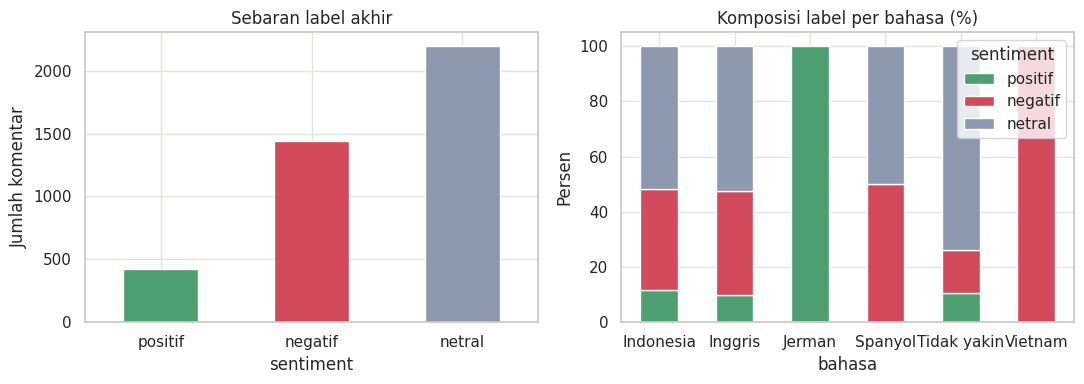


✅ Dataset berlabel akhir disimpan ke: /content/youtube_comments_labeled.csv
✅ Jumlah baris: 4058, kolom: ['video_title', 'comment', 'likes', 'bahasa', 'sentiment'], baris tanpa label: 0


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

URUT3 = ["positif", "negatif", "netral"]

def cari_berkas(nama):
    """Cari berkas di Colab (/content), folder datasets proyek, atau folder kerja."""
    for lokasi in [f'/content/{nama}', f'../../datasets/{nama}', f'datasets/{nama}', nama]:
        if os.path.exists(lokasi):
            return lokasi
    raise FileNotFoundError(f'{nama} tidak ditemukan. Unggah berkasnya ke /content atau taruh di folder datasets.')

# 1. Muat label dan periksa kelengkapannya
label_komentar = pd.read_csv(cari_berkas('label_komentar.csv'))
label_komentar['label'] = label_komentar['label'].astype('string').str.strip().str.lower()

if len(label_komentar) != len(df_clean):
    raise ValueError(f'Jumlah label ({len(label_komentar)}) tidak sama dengan jumlah komentar ({len(df_clean)}).')
if label_komentar['id'].duplicated().any():
    raise ValueError('Ada id ganda pada label_komentar.csv.')
label_komentar = label_komentar.sort_values('id').reset_index(drop=True)
if not (label_komentar['id'].to_numpy() == np.arange(len(df_clean))).all():
    raise ValueError('Kolom id pada label_komentar.csv harus 0 sampai jumlah komentar dikurangi 1.')
salah = label_komentar[~label_komentar['label'].isin(URUT3)]
if len(salah) > 0:
    raise ValueError(f'{len(salah)} label kosong atau salah tulis. Contoh id: {salah["id"].head(5).tolist()}')

# 2. Gabungkan dengan dataset bersih berdasarkan nomor baris (df_clean memakai indeks 0, 1, 2, ...)
df_label = df_clean[['video_title', 'comment', 'likes', 'bahasa']].copy()
df_label['sentiment'] = label_komentar['label'].to_numpy()

print(f'✅ {len(df_label)} komentar berlabel, tidak ada yang kosong.')

# 3. Sebaran label
print('\nSebaran label akhir:')
sebaran = df_label['sentiment'].value_counts().reindex(URUT3)
display(pd.DataFrame({'Jumlah': sebaran, 'Persen': (sebaran / len(df_label) * 100).round(1)}))

print('Sebaran label per bahasa (persen dalam tiap bahasa):')
display((pd.crosstab(df_label['bahasa'], df_label['sentiment'], normalize='index')[URUT3] * 100).round(1))

print('Sebaran label per video (jumlah komentar):')
display(pd.crosstab(df_label['video_title'].str.slice(0, 60), df_label['sentiment'])[URUT3])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sebaran.plot(kind='bar', ax=ax[0], color=['#4c9f70', '#d1495b', '#8d99ae'], rot=0)
ax[0].set_title('Sebaran label akhir')
ax[0].set_ylabel('Jumlah komentar')
(pd.crosstab(df_label['bahasa'], df_label['sentiment'], normalize='index')[URUT3] * 100).plot(
    kind='bar', stacked=True, ax=ax[1], color=['#4c9f70', '#d1495b', '#8d99ae'], rot=0)
ax[1].set_title('Komposisi label per bahasa (%)')
ax[1].set_ylabel('Persen')
plt.tight_layout()
plt.show()

# 4. Simpan dataset berlabel akhir untuk tahap klasifikasi
if os.path.exists('/content'):
    FILE_LABEL = '/content/youtube_comments_labeled.csv'
elif os.path.exists('../../datasets'):
    FILE_LABEL = '../../datasets/youtube_comments_labeled.csv'
elif os.path.exists('datasets'):
    FILE_LABEL = 'datasets/youtube_comments_labeled.csv'
else:
    FILE_LABEL = 'youtube_comments_labeled.csv'

df_label.to_csv(FILE_LABEL, index=False, encoding='utf-8')
df_cek = pd.read_csv(FILE_LABEL)
print(f'\n✅ Dataset berlabel akhir disimpan ke: {FILE_LABEL}')
print(f'✅ Jumlah baris: {len(df_cek)}, kolom: {df_cek.columns.tolist()}, baris tanpa label: {df_cek["sentiment"].isna().sum()}')

> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** Cek data (head, isnull, isna, duplicated)
>
> **Cakupan:** 4 sel di bawah ini
>
> **Isi:** Membaca ulang `youtube_comments_clean.csv` lalu mengecek nilai kosong dan duplikat.
>
> **Alasan:** Sudah dilakukan di Bab 3 dan 4, jadi hanya mengulang.


In [ ]:
df_clean_comment = pd.read_csv("/content/youtube_comments_clean.csv")
df_clean_comment.head()

,video_title,comment,likes,bahasa
0,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Bahas imigrant maroko yg nyebrang ke spanyol donk bang,413,Indonesia
1,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Menurut saya jika semua pengusaha berpikiran sama untuk mengganti manusia dengan AI demi memotong biaya, mereka sedang menghancurkan pas...",189,Indonesia
2,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"jujur ya sebagai seorang yang bekerja di bidang desain, seni, ilustrator agak sedih dengan keadaan apa-apa didesain sama ai. melihat par...",6,Indonesia
3,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,"Gw sebagai illustrator susah bener dapet klien baru karena orang udh ngerasa 'ga butuh' jasa illustrator, terus orang bilang ""ya lu haru...",588,Indonesia
4,Pekerja Latih Robot Untuk Gantikan Mereka! KIAMAT KERJA AI DIMULAI!,Niat untung -> efesiensi phk->produksi meningkat->tidak banyak pembeli karna banyak pengangguran->barang numpuk->malah rugi,85,Indonesia


In [ ]:
df_clean_comment.isnull().sum()

,0
video_title,0
comment,0
likes,0
bahasa,0


In [ ]:
df_clean_comment.isna().sum()

,0
video_title,0
comment,0
likes,0
bahasa,0


In [ ]:
df_clean_comment.duplicated().sum()

np.int64(0)

> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** Fine-tune mDeBERTa (LAFT) lalu klasifikasi, dan zero-shot mDeBERTa pada 100 acuan
>
> **Cakupan:** 3 sel di bawah ini
>
> **Isi:** Melatih lanjutan mDeBERTa pada komentar, melatih klasifikasi sentimen di atasnya, lalu mengevaluasi zero-shot mDeBERTa pada 100 komentar acuan.
>
> **Alasan:** Hasil gagal (akurasi sekitar 50% dengan hampir semua ditebak netral), dan tidak dipakai sebagai label akhir.


In [ ]:
import pandas as pd
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForMaskedLM,
    DataCollatorForLanguageModeling,
    Trainer,
    TrainingArguments
)

# 1. Load data mentah & buat input gabungan
df_clean = pd.read_csv("youtube_comments_clean.csv")
df_clean['text_input'] = "Judul: " + df_clean['video_title'].fillna('') + " | Komentar: " + df_clean['comment'].fillna('')

dataset_mlm = Dataset.from_pandas(df_clean[['text_input']])

# 2. Tokenizer & Dataset
model_checkpoint = "microsoft/mdeberta-v3-base"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

def tokenize_function(examples):
    return tokenizer(examples["text_input"], truncation=True, padding="max_length", max_length=128)

tokenized_datasets = dataset_mlm.map(tokenize_function, batched=True, remove_columns=["text_input"])
data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=True, mlm_probability=0.15)

# 3. Model MLM
model_mlm = AutoModelForMaskedLM.from_pretrained(model_checkpoint)

training_args = TrainingArguments(
    output_dir="./mdeberta-laft-checkpoints",
    eval_strategy="no",
    learning_rate=2e-5,
    num_train_epochs=3,
    weight_decay=0.01,
    per_device_train_batch_size=16,
    save_strategy="epoch",
    logging_steps=50
)

trainer = Trainer(
    model=model_mlm,
    args=training_args,
    train_dataset=tokenized_datasets,
    data_collator=data_collator,
)

# 4. Jalankan Training Adaptasi
trainer.train()

# 5. SIMPAN MODEL KE FOLDER LOKAL (Ini langkah krusialnya!)
trainer.save_model("./mdeberta-laft-youtube-final")
tokenizer.save_pretrained("./mdeberta-laft-youtube-final")

print("✅ Folder ./mdeberta-laft-youtube-final berhasil dibuat!")

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

Map:   0%|          | 0/4058 [00:00<?, ? examples/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Folder ./mdeberta-laft-youtube-final berhasil dibuat!


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

# 1. Load dataset berlabel manual
df_labeled = pd.read_csv("comments_labeled.csv")

# Penanganan nama kolom label
label_col = 'label_manual_expert' if 'label_manual_expert' in df_labeled.columns else 'sentiment'

# Hanya menggunakan kolom comment langsung
df_labeled['text_input'] = df_labeled['comment'].fillna('')

# 2. Mapping Label ke Angka (0: positif, 1: negatif, 2: netral)
label_mapping = {"positif": 0, "negatif": 1, "netral": 2}
id2label = {0: "positif", 1: "negatif", 2: "netral"}

df_labeled['label'] = df_labeled[label_col].map(label_mapping)
df_labeled = df_labeled.dropna(subset=['label'])
df_labeled['label'] = df_labeled['label'].astype(int)

# 3. Stratified Split (80% Train, 20% Test)
train_df, test_df = train_test_split(
    df_labeled[['text_input', 'label']],
    test_size=0.2,
    random_state=42,
    stratify=df_labeled['label']
)

# Simpan dataset tes agar bisa dibaca oleh cell evaluasi
test_df.to_csv("test_dataset.csv", index=False)

train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

# 4. Tokenisasi Menggunakan Tokenizer dari Model LAFT
model_path = "./mdeberta-laft-youtube-final"
tokenizer = AutoTokenizer.from_pretrained(model_path)

def tokenize_function(examples):
    return tokenizer(
        examples["text_input"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

train_tokenized = train_dataset.map(tokenize_function, batched=True)
test_tokenized = test_dataset.map(tokenize_function, batched=True)

# 5. Load Model Sequence Classification dari Checkpoint LAFT
model_cls = AutoModelForSequenceClassification.from_pretrained(
    model_path,
    num_labels=3,
    id2label=id2label,
    label2id=label_mapping
)

# 6. Training Arguments untuk Small Data
training_args = TrainingArguments(
    output_dir="./mdeberta-sentiment-classifier",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=4,
    weight_decay=0.01,
    logging_steps=5
)

# 7. Inisialisasi Trainer & Training
trainer = Trainer(
    model=model_cls,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=test_tokenized,
)

print("🚀 Memulai Fine-Tuning Klasifikasi Sentimen...")
trainer.train()

# 8. Simpan Model Klasifikasi Akhir
model_cls.save_pretrained("./mdeberta-sentiment-final-model")
tokenizer.save_pretrained("./mdeberta-sentiment-final-model")
print("✅ Model Klasifikasi Berhasil Disimpan di './mdeberta-sentiment-final-model'")

Map:   0%|          | 0/80 [00:00<?, ? examples/s]

Map:   0%|          | 0/20 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: ./mdeberta-laft-youtube-final
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


🚀 Memulai Fine-Tuning Klasifikasi Sentimen...


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model Klasifikasi Berhasil Disimpan di './mdeberta-sentiment-final-model'


🚀 Memuat Model Zero-Shot NLI Multilingual...


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

...

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

🔮 Menjalankan Prediksi Zero-Shot pada 100 Data...


100%|██████████| 100/100 [00:08<00:00, 12.36it/s]



📊 EVALUASI KETEPATAN ZERO-SHOT LABELING vs LABEL MANUAL
              precision    recall  f1-score   support

     positif     0.1356    0.4444    0.2078        18
     negatif     0.5000    0.0392    0.0727        51
      netral     0.1351    0.1613    0.1471        31

    accuracy                         0.1500       100
   macro avg     0.2569    0.2150    0.1425       100
weighted avg     0.3213    0.1500    0.1201       100

🎯 Macro F1-Score Ketepatan Zero-Shot: 0.1425



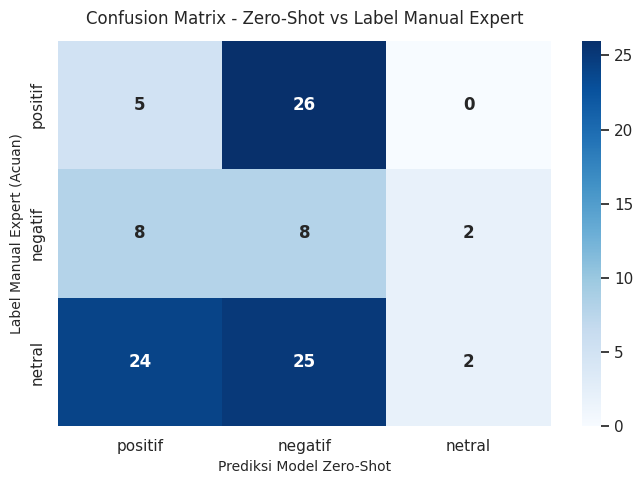

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import pipeline
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from tqdm import tqdm

# 1. Load 100 Data Berlabel Manual
df_labeled = pd.read_csv("comments_labeled.csv")

# Penanganan nama kolom
label_col = 'label_manual_expert' if 'label_manual_expert' in df_labeled.columns else 'sentiment'
comments = df_labeled['comment'].fillna('').tolist()
y_true = df_labeled[label_col].str.lower().str.strip().tolist()

# 2. Inisialisasi Pipeline Zero-Shot NLI Multilingual (NAMA MODEL SUDAH DIPERBAIKI)
print("🚀 Memuat Model Zero-Shot NLI Multilingual...")
classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=0  # Menggunakan GPU Colab
)

# Label target
candidate_labels = ["positif", "negatif", "netral"]
hypothesis_template = "Komentar ini memiliki sentimen {}."

# 3. Prediksi Zero-Shot pada 100 Komentar
print("🔮 Menjalankan Prediksi Zero-Shot pada 100 Data...")
y_pred = []

for text in tqdm(comments):
    result = classifier(text, candidate_labels, hypothesis_template=hypothesis_template)
    top_label = result['labels'][0]
    y_pred.append(top_label)

# 4. Tampilkan Hasil Evaluasi Ketepatan Zero-Shot
print("\n==================================================================")
print("📊 EVALUASI KETEPATAN ZERO-SHOT LABELING vs LABEL MANUAL")
print("==================================================================")
print(classification_report(y_true, y_pred, target_names=candidate_labels, digits=4))

macro_f1 = f1_score(y_true, y_pred, average='macro', labels=candidate_labels)
print(f"🎯 Macro F1-Score Ketepatan Zero-Shot: {macro_f1:.4f}\n")

# 5. Visualisasi Confusion Matrix
cm = confusion_matrix(y_true, y_pred, labels=candidate_labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=candidate_labels,
    yticklabels=candidate_labels,
    annot_kws={"size": 12, "weight": "bold"}
)
plt.title('Confusion Matrix - Zero-Shot vs Label Manual Expert', fontsize=12, pad=12)
plt.xlabel('Prediksi Model Zero-Shot', fontsize=10)
plt.ylabel('Label Manual Expert (Acuan)', fontsize=10)
plt.tight_layout()
plt.show()

> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** Fine-tune mDeBERTa kedua (pip install, split, tokenisasi, trainer, evaluasi) dan catatan "ini terakhir banget"
>
> **Cakupan:** 6 sel di bawah ini
>
> **Isi:** Mengulang fine-tune mDeBERTa pada 100 komentar acuan, lengkap dengan tokenisasi, pelatihan, laporan klasifikasi, dan confusion matrix.
>
> **Alasan:** Duplikat dengan 127 sampai 129, datanya hanya 100 komentar, dan hasilnya hampir semua ditebak netral.


In [ ]:
!pip install transformers datasets evaluate accelerate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.8 MB/s eta 0:00:00


In [ ]:
import pandas as pd
from datasets import Dataset
from sklearn.model_selection import train_test_split

# Contoh asumsi datasetmu (ganti dengan dataset aslimu)
df = pd.read_csv("/content/comments_labeled.csv")

# Pisahkan data menjadi Training (80%) dan Validation (20%)
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label_manual_expert'])

# Ubah DataFrame Pandas menjadi format Dataset dari Hugging Face
train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)

In [ ]:
import pandas as pd
from datasets import Dataset
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

# 1. Baca dataset dari file CSV
df = pd.read_csv("comments_labeled.csv")

# 2. Konversi teks label menjadi angka (Model membutuhkan label numerik: 0, 1, 2)
label_mapping = {'negatif': 0, 'netral': 1, 'positif': 2}
df['label_manual_expert'] = df['label_manual_expert'].map(label_mapping)

# 3. Ubah nama kolom target menjadi 'label' (standar wajib dari Hugging Face)
df = df.rename(columns={'label_manual_expert': 'label'})

# Pastikan tidak ada data yang kosong (NaN) agar tidak error saat di-split
df = df.dropna(subset=['comment', 'label'])
# Ubah tipe data label menjadi integer (bulat)
df['label'] = df['label'].astype(int)

# 4. Pemisahan Dataset (80% Training, 20% Validation)
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['label'])

# 5. Konversi Pandas DataFrame ke format Dataset Hugging Face
train_dataset = Dataset.from_pandas(train_df)
val_dataset = Dataset.from_pandas(val_df)

# 6. Inisialisasi Tokenizer mDeBERTa
model_checkpoint = "microsoft/mdeberta-v3-base"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

# 7. Fungsi Tokenisasi
def tokenize_function(examples):
    # PERBAIKAN: Gunakan 'comment' karena itu nama kolom di datasetmu
    return tokenizer(examples["comment"], padding="max_length", truncation=True, max_length=128)

# 8. Eksekusi Tokenisasi (Error kamu sebelumnya terjadi di sini)
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)

# 9. Hapus kolom teks asli agar model hanya menerima input angka (input_ids, attention_mask, label)
tokenized_train = tokenized_train.remove_columns(["comment", "__index_level_0__"])
tokenized_val = tokenized_val.remove_columns(["comment", "__index_level_0__"])

print("Proses tokenisasi berhasil tanpa error!")

Map:   0%|          | 0/80 [00:00<?, ? examples/s]

Map:   0%|          | 0/20 [00:00<?, ? examples/s]

Proses tokenisasi berhasil tanpa error!


In [ ]:
import numpy as np
import evaluate
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer

# 10. Siapkan Metrik Evaluasi (Akurasi dan F1-Score)
# F1-Score sangat penting karena data sentimen biasanya tidak seimbang
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    acc = accuracy_metric.compute(predictions=predictions, references=labels)
    f1 = f1_metric.compute(predictions=predictions, references=labels, average="macro")

    return {"accuracy": acc["accuracy"], "f1_macro": f1["f1"]}

# 11. Muat Model mDeBERTa untuk Klasifikasi (3 Label)
# num_labels=3 sesuai dengan jumlah kelas kita (0: Negatif, 1: Netral, 2: Positif)
model = AutoModelForSequenceClassification.from_pretrained(model_checkpoint, num_labels=3)

# 12. Atur Parameter Pelatihan (Training Arguments)
training_args = TrainingArguments(
    output_dir="./hasil_finetuning_mdeberta",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=4,
    weight_decay=0.01,
    eval_strategy="epoch",            # PERBAIKAN: Diubah dari evaluation_strategy menjadi eval_strategy
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    report_to="none"
)

# 13. Gabungkan Semua Komponen ke dalam Trainer
# 13. Gabungkan Semua Komponen ke dalam Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,      # PERBAIKAN: Diubah dari tokenizer=tokenizer menjadi processing_class=tokenizer
    compute_metrics=compute_metrics
)

# 14. Eksekusi Fine-Tuning
print("Memulai proses fine-tuning...")
trainer.train()

# 15. Simpan Model Akhir Secara Permanen
trainer.save_model("./model_sentimen_youtube_final")
print("Model terbaik berhasil disimpan dan siap digunakan!")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.dense.weight              | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight 

Memulai proses fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,1.065563,0.500000,0.222222
2,No log,nan,0.200000,0.111111
3,No log,nan,0.200000,0.111111
4,No log,nan,0.200000,0.111111


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model terbaik berhasil disimpan dan siap digunakan!


=== LAPORAN KLASIFIKASI ===
              precision    recall  f1-score   support

     Negatif       0.00      0.00      0.00         4
      Netral       0.50      1.00      0.67        10
     Positif       0.00      0.00      0.00         6

    accuracy                           0.50        20
   macro avg       0.17      0.33      0.22        20
weighted avg       0.25      0.50      0.33        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


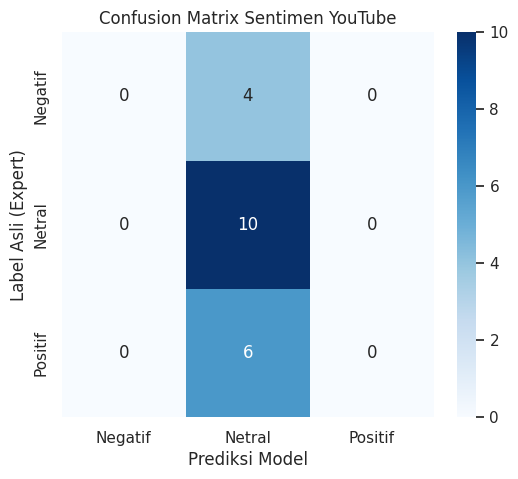

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

# 16. Dapatkan Hasil Prediksi dari Data Validation
predictions = trainer.predict(tokenized_val)
preds = np.argmax(predictions.predictions, axis=-1)
labels = predictions.label_ids

target_names = ['Negatif', 'Netral', 'Positif']

# 17. Cetak Laporan Klasifikasi (Precision, Recall, F1-score per kelas)
print("=== LAPORAN KLASIFIKASI ===")
print(classification_report(labels, preds, target_names=target_names))

# 18. Visualisasi Confusion Matrix
cm = confusion_matrix(labels, preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Prediksi Model')
plt.ylabel('Label Asli (Expert)')
plt.title('Confusion Matrix Sentimen YouTube')
plt.show()

ini terakhir banget

> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** Pelabelan mDeBERTa zero-shot dan tabel 4 algoritma klasik
>
> **Cakupan:** 2 sel di bawah ini
>
> **Isi:** Melabeli 4.058 komentar dengan mDeBERTa, melatih Decision Tree, Naïve Bayes, Random Forest, dan Logistic Regression di atasnya, lalu menguji mDeBERTa pada 100 acuan (akurasi 23%).
>
> **Alasan:** Label mDeBERTa tidak layak (netral hanya 157 komentar), dan tabel 4 algoritma sudah dikerjakan di notebook Classification.


Total dataset siap diproses: 4058 baris komentar.

Memulai pelabelan AI... (Ini akan memakan waktu beberapa menit tergantung jumlah datamu)


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Pelabelan selesai! File berlabel disimpan di: /content/youtube_comments_labeled_by_mDeBERTa.csv

=== HASIL AKURASI 4 ALGORITMA KLASIK ===
Decision Tree       : Akurasi 57.76%
Naïve Bayes         : Akurasi 62.19%
Random Forest       : Akurasi 63.55%
Logistic Regression : Akurasi 62.93%


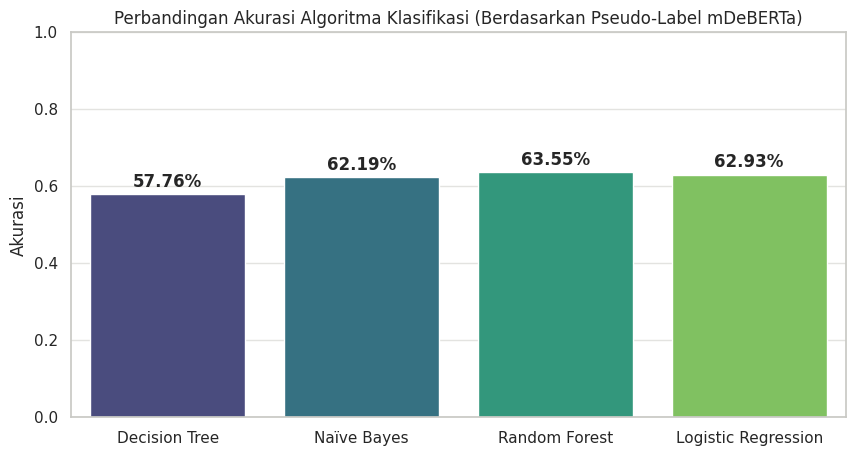

In [ ]:
import pandas as pd
import re
from transformers import pipeline
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Persiapan Dataset Colab
# Baca file yang diunggah ke folder /content/ di Google Colab
df = pd.read_csv("/content/youtube_comments_clean.csv")

# Ganti 'comment' dengan nama kolom yang benar jika di dalam CSV-mu namanya berbeda (misal: 'teks', 'Text')
nama_kolom_teks = 'comment'

# Eksekusi instruksimu: Drop semua baris yang datanya kosong/NaN di kolom teks
df = df.dropna(subset=[nama_kolom_teks])
print(f"Total dataset siap diproses: {len(df)} baris komentar.")

## 2. Auto-Labeling (Pseudo-Labeling) dengan mDeBERTa Zero-Shot
print("\nMemulai pelabelan AI... (Ini akan memakan waktu beberapa menit tergantung jumlah datamu)")
# Gunakan device=0 agar proses dialihkan ke GPU Colab (sangat mempercepat waktu proses)
zero_shot_classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=0
)
candidate_labels = ["positif", "netral", "negatif"]

labels_hasil = []
for teks in df[nama_kolom_teks]:
    # Pastikan teks dibaca sebagai string untuk mencegah error pada angka atau simbol aneh
    hasil = zero_shot_classifier(str(teks), candidate_labels)
    labels_hasil.append(hasil['labels'][0])

df['label_ai'] = labels_hasil

# Simpan hasil pelabelan sebagai backup di Colab
path_simpan = "/content/youtube_comments_labeled_by_mDeBERTa.csv"
df.to_csv(path_simpan, index=False)
print(f"Pelabelan selesai! File berlabel disimpan di: {path_simpan}")


## 3. Preprocessing Khusus Algoritma ML Klasik
def clean_text_classic(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text) # Membuang emoji, angka, dan tanda baca
    return text

df['clean_comment'] = df[nama_kolom_teks].apply(clean_text_classic)


## 4. Ekstraksi Fitur (TF-IDF) & Split Data
X = df['clean_comment']
y = df['label_ai'] # Kunci jawabannya menggunakan hasil tebakan mDeBERTa

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
tfidf = TfidfVectorizer(max_features=1000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)


## 5. Training & Evaluasi 4 Algoritma Klasik (Sesuai Rumusan Masalah)
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naïve Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000)
}

results = {}
print("\n=== HASIL AKURASI 4 ALGORITMA KLASIK ===")
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"{name:<20}: Akurasi {acc:.2%}")


## 6. Visualisasi Perbandingan Model (Siap masuk ke Laporan Data Mining)
plt.figure(figsize=(10, 5))
sns.barplot(x=list(results.keys()), y=list(results.values()), hue=list(results.keys()), palette="viridis", legend=False)
plt.title('Perbandingan Akurasi Algoritma Klasifikasi (Berdasarkan Pseudo-Label mDeBERTa)')
plt.ylabel('Akurasi')
plt.ylim(0, 1)
for i, v in enumerate(results.values()):
    plt.text(i, v + 0.02, f"{v:.2%}", ha='center', fontweight='bold')
plt.show()

In [ ]:
import pandas as pd
from transformers import pipeline
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Baca 100 data yang SUDAH kamu labeli secara manual
df_test = pd.read_csv("/content/comments_labeled.csv")
df_test = df_test.dropna(subset=['comment', 'label_manual_expert'])

# Pastikan teks label manual huruf kecil semua agar cocok saat dibandingkan
df_test['label_manual_expert'] = df_test['label_manual_expert'].str.lower()

print("Memulai Uji Coba mDeBERTa pada 100 data manual... (Tunggu sebentar)\n")

# 2. Panggil mDeBERTa Zero-Shot
zero_shot_classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=0
)
candidate_labels = ["positif", "netral", "negatif"]

# 3. Suruh model menebak
prediksi_mDeBERTa = []
for teks in df_test['comment']:
    hasil = zero_shot_classifier(str(teks), candidate_labels)
    prediksi_mDeBERTa.append(hasil['labels'][0])

df_test['prediksi_ai'] = prediksi_mDeBERTa

# 4. Hitung Akurasi Keseluruhan
akurasi = accuracy_score(df_test['label_manual_expert'], df_test['prediksi_ai'])
print(f"✅ Akurasi mDeBERTa vs Manusia: {akurasi:.2%}\n")

# 5. Tampilkan Laporan Detail (Precision, Recall, F1 per kelas)
print("=== LAPORAN DETAIL (Berdasarkan 100 Data) ===")
print(classification_report(df_test['label_manual_expert'], df_test['prediksi_ai']))

# 6. Analisis Error (Melihat di mana mDeBERTa salah tebak)
df_salah = df_test[df_test['label_manual_expert'] != df_test['prediksi_ai']]
print(f"\n❌ Total salah tebak: {len(df_salah)} dari {len(df_test)} komentar")
print("Contoh komentar yang salah tebak:")
display(df_salah[['comment', 'label_manual_expert', 'prediksi_ai']].head())

Memulai Uji Coba mDeBERTa pada 100 data manual... (Tunggu sebentar)



Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ Akurasi mDeBERTa vs Manusia: 16.00%

=== LAPORAN DETAIL (Berdasarkan 100 Data) ===
              precision    recall  f1-score   support

     negatif       0.14      0.44      0.21        18
      netral       0.40      0.04      0.07        51
     positif       0.17      0.19      0.18        31

    accuracy                           0.16       100
   macro avg       0.23      0.23      0.15       100
weighted avg       0.28      0.16      0.13       100


❌ Total salah tebak: 84 dari 100 komentar
Contoh komentar yang salah tebak:


,comment,label_manual_expert,prediksi_ai
1,randy109 The assumption that ANY job will always be done by humans is a bad one. Robots can theoretically do anything that's possible. T...,positif,negatif
2,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",positif,negatif
3,Tapi kata pengembang AI sekarang kan ada AI ECO green dimana pake air daur ulang bukan air bersih kayak air minum kita pada umumnya. Jad...,negatif,positif
4,My job is school. The work condition is horrible and I don’t get paid.,netral,negatif
5,Jika kalian selalu mengandalkan AI maka nanti kalian bakalan di gantikan AI,positif,negatif


> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** Catatan "cantumin LLM (data scientist X AI engineer)"
>
> **Cakupan:** 1 sel di bawah ini (hanya satu sel)
>
> **Isi:** Catatan pribadi untuk diri sendiri.
>
> **Alasan:** Bukan bagian laporan.


cantumin LLM (data scinetist X AI engineer)

> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** Iterasi prompt Qwen (lima percobaan)
>
> **Cakupan:** 5 sel di bawah ini
>
> **Isi:** Lima versi prompt LLM yang diuji pada 100 komentar acuan (akurasi 44%, 55%, 55%, 51%, 56%), sebagian memakai SMOTE dan chain-of-thought.
>
> **Alasan:** Cukup versi akhir di sel 144. Sel-sel ini hanya riwayat percobaan prompt.


In [ ]:
import pandas as pd
import torch
from transformers import pipeline
from sklearn.metrics import accuracy_score, classification_report

print("=== TAHAP 1: PENGGABUNGAN DATA (Mencari Judul Video) ===")
# 1. Baca dataset
df_labeled = pd.read_csv("/content/comments_relabeled.csv")
df_clean = pd.read_csv("/content/youtube_comments_clean.csv")

# 2. Gabungkan data untuk mendapatkan konteks judul
df_test = pd.merge(df_labeled, df_clean[['comment', 'video_title']], on='comment', how='left')
df_test = df_test.drop_duplicates(subset=['comment'])
df_test['video_title'] = df_test['video_title'].fillna("Isu AI menggantikan pekerjaan")

print("=== TAHAP 2: INISIALISASI LLM & PREDIKSI ===")
# Pastikan LLM dimuat ke GPU
generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    model_kwargs={"torch_dtype": torch.float16},
    device_map="auto"
)

# 3. Fungsi Prompting (DIPERKUAT DENGAN FEW-SHOT & ERROR HANDLING)
def tebak_sentimen_konteks_dan_aturan(row):
    judul = str(row['video_title'])
    teks_komentar = str(row['comment'])

    # Prompt dengan FEW-SHOT (Contoh Kasus) agar AI tidak membantah aturanmu
    prompt = f"""Kamu adalah ahli pelabelan data. Baca Judul Video dan Komentar YouTube berikut.

ATURAN SENTIMEN (WAJIB DIIKUTI):
- POSITIF: Penulis mengeluh, resah, takut, atau merasa terancam karena AI. (AI dianggap buruk bagi pekerja).
- NEGATIF: Penulis mendukung AI, terbantu AI, atau tidak resah. (AI dianggap baik/berguna).
- NETRAL: Komentar tidak jelas, out of context, atau hanya memuji/menyapa.

CONTOH:
Judul: "AI Gantikan Karyawan" | Komentar: "Gimana nasib anak istri saya nanti kalau di PHK?" -> POSITIF
Judul: "AI Gantikan Karyawan" | Komentar: "Wah fitur AI ini bikin kerjaan coding makin cepet!" -> NEGATIF
Judul: "AI Gantikan Karyawan" | Komentar: "Bang coba main game horor dong" -> NETRAL

Tugas: Tentukan sentimen dari komentar di bawah ini. Jawab HANYA dengan SATU KATA: POSITIF, NEGATIF, atau NETRAL.

Judul Video: "{judul}"
Komentar: "{teks_komentar}"
Sentimen:"""

    try:
        hasil = generator(
            prompt,
            max_new_tokens=5,
            temperature=0.0,      # Kaku dan absolut
            do_sample=False,
            return_full_text=False
        )
        jawaban = hasil[0]['generated_text'].strip().lower()

        # Standardisasi Output
        if "positif" in jawaban: return "positif"
        elif "negatif" in jawaban: return "negatif"
        elif "netral" in jawaban: return "netral"
        else: return "netral"

    except Exception as e:
        # Jika ada error teks terlalu panjang atau karakter aneh, jadikan netral agar script tidak mati
        return "netral"

print("AI sedang berpikir keras menyesuaikan aturanmu...")
df_test['prediksi_ai'] = df_test.apply(tebak_sentimen_konteks_dan_aturan, axis=1)

# Samakan format label manual untuk evaluasi
df_test['label_manual_expert'] = df_test['label_manual_expert'].str.lower()

print("\n=== TAHAP 3: EVALUASI (LLM vs LABEL MANUAL) ===")
# 4. Hitung Akurasi (Typo preadiksi_ai sudah diperbaiki)
akurasi = accuracy_score(df_test['label_manual_expert'], df_test['prediksi_ai'])
print(f"✅ Akurasi LLM (Qwen + Aturan Baru) vs Label Manual: {akurasi:.2%}\n")

# 5. Laporan Lengkap
print("=== LAPORAN DETAIL KLASIFIKASI ===")
print(classification_report(df_test['label_manual_expert'], df_test['prediksi_ai']))

# 6. Analisis Kesalahan
df_salah = df_test[df_test['label_manual_expert'] != df_test['prediksi_ai']]
print(f"\n❌ Total AI dan Kamu Berbeda Pendapat: {len(df_salah)} dari {len(df_test)} komentar")

print("Contoh perbedaan tebakan:")
display(df_salah[['video_title', 'comment', 'label_manual_expert', 'prediksi_ai']].head())

=== TAHAP 1: PENGGABUNGAN DATA (Mencari Judul Video) ===
=== TAHAP 2: INISIALISASI LLM & PREDIKSI ===


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

...

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


AI sedang berpikir keras menyesuaikan aturanmu...


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=5) and `max_length`(=


=== TAHAP 3: EVALUASI (LLM vs LABEL MANUAL) ===
✅ Akurasi LLM (Qwen + Aturan Baru) vs Label Manual: 44.00%

=== LAPORAN DETAIL KLASIFIKASI ===
              precision    recall  f1-score   support

     negatif       0.00      0.00      0.00        18
      netral       0.53      0.86      0.66        51
     positif       0.00      0.00      0.00        31

    accuracy                           0.44       100
   macro avg       0.18      0.29      0.22       100
weighted avg       0.27      0.44      0.33       100


❌ Total AI dan Kamu Berbeda Pendapat: 56 dari 100 komentar
Contoh perbedaan tebakan:


,video_title,comment,label_manual_expert,prediksi_ai
0,UK unemployment soars: is AI already taking our jobs?,"Retail and sales could move even more online. Marketing using AI will become more effective to support that trend, so these areas will b...",positif,netral
1,Humans Need Not Apply - CGP Grey,randy109 The assumption that ANY job will always be done by humans is a bad one. Robots can theoretically do anything that's possible. T...,positif,netral
2,AI is taking their jobs. But they're fighting back.,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing t...",positif,netral
3,Manusia Belum Tergantikan AI Karena Satu Hambatan Ini,Tapi kata pengembang AI sekarang kan ada AI ECO green dimana pake air daur ulang bukan air bersih kayak air minum kita pada umumnya. Jad...,negatif,netral
4,Humans Need Not Apply - CGP Grey,My job is school. The work condition is horrible and I don’t get paid.,netral,negatif


=== TAHAP 1: PERSIAPAN DATA ===
=== TAHAP 2: AUTO-LABELING LLM DENGAN BILINGUAL FEW-SHOT ===


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


AI sedang memproses label menggunakan otak barunya...


[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs


=== TAHAP 3: EVALUASI KUALITAS LLM ===
✅ Akurasi LLM Terbaru: 55.00%

=== TAHAP 4: MACHINE LEARNING KLASIK + SMOTE ===

[INFO SMOTE] Keseimbangan Data SEBELUM SMOTE:
label_manual_expert
netral     41
positif    25
negatif    14
Name: count, dtype: int64

[INFO SMOTE] Keseimbangan Data SETELAH SMOTE (Data Minoritas Berhasil Diselamatkan):
label_manual_expert
netral     41
positif    41
negatif    41
Name: count, dtype: int64

=== HASIL AKHIR: AKURASI MODEL KLASIK (WITH SMOTE) ===
- Decision Tree       : 60.00%
- Naïve Bayes         : 40.00%
- Random Forest       : 50.00%
- Logistic Regression : 35.00%


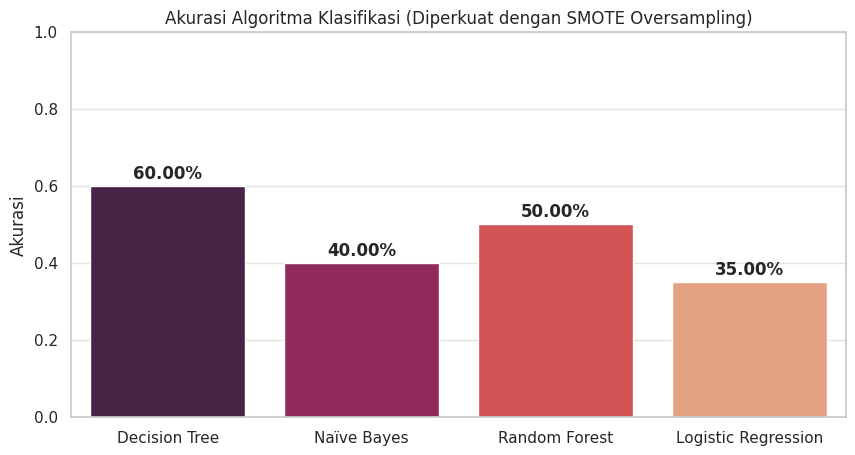

In [ ]:
import pandas as pd
import torch
import re
from transformers import pipeline
from imblearn.over_sampling import SMOTE  # Library andalan untuk SMOTE
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

print("=== TAHAP 1: PERSIAPAN DATA ===")
# Membaca dataset sesuai file aslimu
df_labeled = pd.read_csv("/content/comments_relabeled.csv")
df_clean = pd.read_csv("/content/youtube_comments_clean.csv")

# Gabungkan data untuk mengambil judul video
df_test = pd.merge(df_labeled, df_clean[['comment', 'video_title']], on='comment', how='left')
df_test = df_test.drop_duplicates(subset=['comment'])
df_test['video_title'] = df_test['video_title'].fillna("Isu AI menggantikan pekerjaan")

print("=== TAHAP 2: AUTO-LABELING LLM DENGAN BILINGUAL FEW-SHOT ===")
generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    model_kwargs={"torch_dtype": torch.float16},
    device_map="auto"
)

# FUNGSI PROMPTING SUPER ROBUST (Dengan contoh asli dari datasetmu)
def tebak_sentimen_bilingual(row):
    judul = str(row['video_title'])
    teks = str(row['comment'])

    # Prompt bilingual yang berisi CONTOH NYATA dari bahasamu
    prompt = f"""You are a Data Annotation Expert analyzing YouTube comments regarding AI replacing human jobs.

RULES (MUST FOLLOW STRICTLY):
- [POSITIF]: Author complains, is afraid, anxious, or threatened that AI will take jobs (AI is BAD for workers).
- [NEGATIF]: Author supports AI, finds it useful, or doesn't care about AI replacing jobs (AI is GOOD).
- [NETRAL]: Out of context, spam, praising the video, or general statements without sentiment.

REAL EXAMPLES TO LEARN FROM:
[Example 1 - English] Title: "AI is taking their jobs" | Comment: "these areas will be subject to job losses too" -> [POSITIF]
[Example 2 - Indonesia] Title: "Kiamat Kerja AI!" | Comment: "kalau banyak phk, daya beli masyarakat jadi turun, yang nganggur makin banyak" -> [POSITIF]
[Example 3 - English] Title: "UK unemployment soars" | Comment: "Unlike the US AI systems... bring extra income for the NHS" -> [NEGATIF]
[Example 4 - Indonesia] Title: "Manusia Belum Tergantikan AI" | Comment: "Jadi AI masih menguntungkan bagi orang yang bisa memanfaatkannya" -> [NEGATIF]
[Example 5 - English] Title: "Humans Need Not Apply" | Comment: "My job is school. The work condition is horrible" -> [NETRAL]
[Example 6 - Indonesia] Title: "Kiamat Kerja AI!" | Comment: "lu juga masih bales nih ngaca kocak" -> [NETRAL]

Task: Determine the sentiment of the comment below. Output ONLY ONE label inside brackets: [POSITIF], [NEGATIF], or [NETRAL].

Title: "{judul}"
Comment: "{teks}"
Label:"""

    try:
        hasil = generator(
            prompt,
            max_new_tokens=10,
            temperature=0.0,
            do_sample=False,
            return_full_text=False
        )
        jawaban = hasil[0]['generated_text'].strip().lower()

        # Ekstraksi label yang kebal bahasa
        if "positif" in jawaban or "positive" in jawaban or "[pos]" in jawaban: return "positif"
        elif "negatif" in jawaban or "negative" in jawaban or "[neg]" in jawaban: return "negatif"
        else: return "netral"

    except Exception:
        return "netral"

print("AI sedang memproses label menggunakan otak barunya...")
df_test['prediksi_ai'] = df_test.apply(tebak_sentimen_bilingual, axis=1)


print("\n=== TAHAP 3: EVALUASI KUALITAS LLM ===")
df_test['label_manual_expert'] = df_test['label_manual_expert'].astype(str).str.lower().str.strip()
akurasi_llm = accuracy_score(df_test['label_manual_expert'], df_test['prediksi_ai'])
print(f"✅ Akurasi LLM Terbaru: {akurasi_llm:.2%}")


print("\n=== TAHAP 4: MACHINE LEARNING KLASIK + SMOTE ===")
# 1. Bersihkan teks untuk Machine Learning
def clean_text_classic(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text

df_test['komentar_plus_judul'] = df_test['video_title'] + " " + df_test['comment']
df_test['clean_comment'] = df_test['komentar_plus_judul'].apply(clean_text_classic)

# 2. Ekstraksi Fitur (TF-IDF) & Split Data
X = df_test['clean_comment']
# Gunakan label manual untuk evaluasi perbandingan ini, ganti ke prediksi_ai saat pakai seluruh data
y = df_test['label_manual_expert']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
tfidf = TfidfVectorizer(max_features=1500)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# 3. IMPLEMENTASI SMOTE
print("\n[INFO SMOTE] Keseimbangan Data SEBELUM SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_tfidf, y_train)

print("\n[INFO SMOTE] Keseimbangan Data SETELAH SMOTE (Data Minoritas Berhasil Diselamatkan):")
print(y_train_smote.value_counts())


# 4. Training 4 Algoritma Klasik (Menggunakan Data SMOTE)
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naïve Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000)
}

results = {}
print("\n=== HASIL AKHIR: AKURASI MODEL KLASIK (WITH SMOTE) ===")
for name, model in models.items():
    model.fit(X_train_smote, y_train_smote) # <-- Latih menggunakan data yang sudah diseimbangkan
    y_pred = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"- {name:<20}: {acc:.2%}")

# Visualisasi
plt.figure(figsize=(10, 5))
sns.barplot(x=list(results.keys()), y=list(results.values()), hue=list(results.keys()), palette="rocket", legend=False)
plt.title('Akurasi Algoritma Klasifikasi (Diperkuat dengan SMOTE Oversampling)')
plt.ylabel('Akurasi')
plt.ylim(0, 1)
for i, v in enumerate(results.values()):
    plt.text(i, v + 0.02, f"{v:.2%}", ha='center', fontweight='bold')
plt.show()

In [ ]:
import pandas as pd
import torch
from transformers import pipeline
from sklearn.metrics import accuracy_score, classification_report

print("=== TAHAP 1: PERSIAPAN DATA EVALUASI ===")
# Membaca data
df_labeled = pd.read_csv("/content/comments_relabeled.csv")
df_clean = pd.read_csv("/content/youtube_comments_clean.csv")

# Gabung untuk mengambil judul video
df_test = pd.merge(df_labeled, df_clean[['comment', 'video_title']], on='comment', how='left')
df_test = df_test.drop_duplicates(subset=['comment'])
df_test['video_title'] = df_test['video_title'].fillna("Isu AI menggantikan pekerjaan")

print("=== TAHAP 2: AUTO-LABELING LLM (MULTILINGUAL FEW-SHOT) ===")
generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    model_kwargs={"torch_dtype": torch.float16},
    device_map="auto"
)

# FUNGSI PROMPTING YANG SUDAH MENCAKUP MULTI-BAHASA DAN SLANG
def tebak_sentimen_multibahasa(row):
    judul = str(row['video_title'])
    teks = str(row['comment'])

    # Prompt dengan instruksi menguasai bahasa apa pun dan contoh slang/campuran
    prompt = f"""You are a Multilingual Data Annotation Expert analyzing YouTube comments regarding AI replacing human jobs. The comments can be in English, Indonesian, Spanish, German, or informal slang.

RULES (MUST FOLLOW STRICTLY):
- [POSITIF]: Author complains, is afraid, anxious, threatened, or uses dark humor (like Skynet/Terminator) about AI taking jobs. (AI is BAD for workers).
- [NEGATIF]: Author supports AI, finds it useful, or doesn't care about AI replacing jobs (AI is GOOD).
- [NETRAL]: Out of context, spam, praising the video, short vague remarks, or general statements without sentiment.

REAL EXAMPLES TO LEARN FROM:
[English] Title: "AI is taking their jobs" | Comment: "these areas will be subject to job losses too" -> [POSITIF]
[Indonesia] Title: "Kiamat Kerja AI!" | Comment: "kalau banyak phk, daya beli masyarakat jadi turun" -> [POSITIF]
[Slang/Mixed] Title: "Humans Need Not Apply" | Comment: "Era skynet akan di mulai.. 😁😁" -> [POSITIF]
[English] Title: "UK unemployment soars" | Comment: "bring extra income for the NHS" -> [NEGATIF]
[Indonesia] Title: "Manusia Belum Tergantikan AI" | Comment: "Jadi AI masih menguntungkan bagi orang yang memanfaatkannya" -> [NEGATIF]
[Spanish] Title: "AI is taking their jobs" | Comment: "No me importa, la tecnología avanza" -> [NEGATIF]
[English] Title: "Humans Need Not Apply" | Comment: "My job is school. The work condition is horrible" -> [NETRAL]
[Slang/Mixed] Title: "Kiamat Kerja AI!" | Comment: "lu juga masih bales nih ngaca kocak" -> [NETRAL]

Task: Determine the sentiment of the comment below. Translate it internally if it's in another language, then apply the rules. Output ONLY ONE label inside brackets: [POSITIF], [NEGATIF], or [NETRAL].

Title: "{judul}"
Comment: "{teks}"
Label:"""

    try:
        hasil = generator(
            prompt,
            max_new_tokens=10,
            temperature=0.0,
            do_sample=False,
            return_full_text=False
        )
        jawaban = hasil[0]['generated_text'].strip().lower()

        # Ekstraksi label yang kebal format
        if "positif" in jawaban or "positive" in jawaban or "[pos" in jawaban: return "positif"
        elif "negatif" in jawaban or "negative" in jawaban or "[neg" in jawaban: return "negatif"
        else: return "netral"

    except Exception:
        return "netral"

print("LLM sedang menganalisis teks dengan pemahaman multi-bahasa...")
df_test['prediksi_ai'] = df_test.apply(tebak_sentimen_multibahasa, axis=1)


print("\n=== TAHAP 3: EVALUASI METRIK LLM (SUPER DETAIL) ===")
# Samakan format huruf kecil
df_test['label_manual_expert'] = df_test['label_manual_expert'].astype(str).str.lower().str.strip()

# 1. Tampilkan Akurasi
akurasi_llm = accuracy_score(df_test['label_manual_expert'], df_test['prediksi_ai'])
print(f"✅ Akurasi LLM Multilingual: {akurasi_llm:.2%}\n")

# 2. Laporan Metrik Detail (Inilah yang kamu cari!)
print("=== LAPORAN KLASIFIKASI (PRECISION, RECALL, F1) ===")
print(classification_report(df_test['label_manual_expert'], df_test['prediksi_ai']))

# 3. Analisis Error (Bedah Kasus)
df_salah = df_test[df_test['label_manual_expert'] != df_test['prediksi_ai']]
print(f"\n❌ Terdapat {len(df_salah)} komentar yang tebakannya beda antara AI dan Kamu.")
print("Berikut adalah contoh di mana AI gagal menebak sesuai maumu:")

# Menampilkan dataframe dengan kolom lebih lebar agar mudah dibaca
pd.set_option('display.max_colwidth', None)
display(df_salah[['comment', 'label_manual_expert', 'prediksi_ai']].head(10))

=== TAHAP 1: PERSIAPAN DATA EVALUASI ===
=== TAHAP 2: AUTO-LABELING LLM (MULTILINGUAL FEW-SHOT) ===


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


LLM sedang menganalisis teks dengan pemahaman multi-bahasa...


[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs


=== TAHAP 3: EVALUASI METRIK LLM (SUPER DETAIL) ===
✅ Akurasi LLM Multilingual: 55.00%

=== LAPORAN KLASIFIKASI (PRECISION, RECALL, F1) ===
              precision    recall  f1-score   support

     negatif       0.22      0.11      0.15        18
      netral       0.58      0.96      0.72        51
     positif       0.67      0.13      0.22        31

    accuracy                           0.55       100
   macro avg       0.49      0.40      0.36       100
weighted avg       0.54      0.55      0.46       100


❌ Terdapat 45 komentar yang tebakannya beda antara AI dan Kamu.
Berikut adalah contoh di mana AI gagal menebak sesuai maumu:


,comment,label_manual_expert,prediksi_ai
1,"randy109 The assumption that ANY job will always be done by humans is a bad one. Robots can theoretically do anything that's possible. Technology makes what's theoretically possible practically possible. It's not a matter of IF all human security guards will be replaced, it's a matter of WHEN will they be replaced.",positif,netral
2,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing today, i.e.: catching the AI shit generated. People will never learn and never grow if the AI is doing the job for them. Learning is hard are require effort, without effort you don't lean. But I guess it is too hard to understand.....",positif,netral
3,Tapi kata pengembang AI sekarang kan ada AI ECO green dimana pake air daur ulang bukan air bersih kayak air minum kita pada umumnya. Jadi AI masih menguntungkan bagi orang yang bisa memanfaatkannya,negatif,netral
5,Jika kalian selalu mengandalkan AI maka nanti kalian bakalan di gantikan AI,positif,negatif
7,"Unlike the US AI systems the Chinese ones are open source, anyone can basically copy and paste then edit. If we were to fund a UK EU version it might not cost a lot, as much of the work at least for the current AI is for free. Then our companies are not dependant on china/us, we could even use a public one for the NHS and licence the health data to bring extra income for the NHS",negatif,netral
8,"Work for a big bank, project work in building out a new lending platform. AI slop is getting exhausting to deal with, people that are overly reliant on it are often too lazy to validate what it spat out, mixed with inconsistent confluence practices, has been a recipe for disaster. This is in nz, where if something goes very wrong the ceo and execs could go to jail😂",positif,netral
9,What will happen when AI asks its self what its purpose is. This is difficult for people no purpose equals a problem depretion etc,positif,netral
16,A human cant win against a machine,positif,negatif
22,"perusahaan teknologi secara besar2an me-layoff karyawannya karena dianggap AI bisa menggantikan manusia, sampai aja masalah baru, dimana bug muncul dimana-mana, kode buatan AI yang bisa dibilang ngaco. Bahkan baru2 ini berusahaan raksasa macam google, amazon, dsb mulai re-hiring karyawan yang kena layoff. Karena hasil buatan AI cuma terlihat bagus, tapi isinya banyak masalah. Ya intinya, AI itu adalah alat, dan alat tidak akan pernah bisa menggantikan manusia. Memang ada automation yang mengurangi kebutuhan SDM. tapi tetap, manusia dibutuhkan buat mengawasi dan review hasil dari pekerjaan yang dikerjakan AI.",positif,netral
24,"IA kan di buat oleh manusia Lhaa, klo manusia di ganti IA nanti yg angkut angkut barang siapa",negatif,netral


In [ ]:
import pandas as pd
import torch
from transformers import pipeline
from sklearn.metrics import accuracy_score, classification_report

print("=== TAHAP 1: PERSIAPAN DATA EVALUASI ===")
# Membaca data
df_labeled = pd.read_csv("/content/comments_relabeled.csv")
df_clean = pd.read_csv("/content/youtube_comments_clean.csv")

# Gabung untuk mengambil judul video
df_test = pd.merge(df_labeled, df_clean[['comment', 'video_title']], on='comment', how='left')
df_test = df_test.drop_duplicates(subset=['comment'])
df_test['video_title'] = df_test['video_title'].fillna("Isu AI menggantikan pekerjaan")

print("=== TAHAP 2: AUTO-LABELING LLM (MULTILINGUAL FEW-SHOT) ===")
generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    model_kwargs={"torch_dtype": torch.float16},
    device_map="auto"
)

# FUNGSI PROMPTING YANG SUDAH MENCAKUP MULTI-BAHASA DAN SLANG
def tebak_sentimen_cot(row):
    judul = str(row['video_title'])
    teks = str(row['comment'])

    # Prompt Chain-of-Thought (Memaksa AI menganalisis alasan sebelum menjawab)
    prompt = f"""You are a strict data annotator. Analyze this YouTube comment about AI replacing human jobs.

RULES:
1. POSITIF = Author is worried, scared, complaining, complaining about job loss, or thinks AI is bad for workers.
2. NEGATIF = Author supports AI, uses AI, finds AI helpful, or thinks AI creates opportunities (NOT worried).
3. NETRAL = ONLY use this if the comment is completely off-topic, spam, or neutral news without opinion.

NOTE: DO NOT default to NETRAL easily! If there is even a small complaint, label it POSITIF. If there is a small support, label it NEGATIF.

Title: "{judul}"
Comment: "{teks}"

Analyze step-by-step:
1. Is the user worried/complaining about AI? (Yes/No)
2. Is the user supporting/happy with AI? (Yes/No)

Final Label (Output ONLY [POSITIF], [NEGATIF], or [NETRAL]):"""

    try:
        hasil = generator(
            prompt,
            max_new_tokens=30,      # Tambah token agar AI sempat menulis sedikit alasan sebelum label
            temperature=0.1,
            do_sample=False,
            return_full_text=False
        )
        jawaban = hasil[0]['generated_text'].strip().lower()

        # Ekstraksi label dari teks analisis
        if "[positif]" in jawaban or "final label: positif" in jawaban or "positif" in jawaban.split()[-2:]:
            return "positif"
        elif "[negatif]" in jawaban or "final label: negatif" in jawaban or "negatif" in jawaban.split()[-2:]:
            return "negatif"
        elif "positive" in jawaban:
            return "positif"
        elif "negative" in jawaban:
            return "negatif"
        else:
            # Pengecekan manual dari kata kunci jika format agak melenceng
            if "worried" in jawaban or "scared" in jawaban or "complaint" in jawaban:
                return "positif"
            elif "support" in jawaban or "helpful" in jawaban or "useful" in jawaban:
                return "negatif"
            return "netral"

    except Exception:
        return "netral"

print("AI sedang memproses ulang dengan logika Chain-of-Thought...")
df_test['prediksi_ai'] = df_test.apply(tebak_sentimen_cot, axis=1)


print("\n=== TAHAP 3: EVALUASI METRIK LLM (SUPER DETAIL) ===")
# Samakan format huruf kecil
df_test['label_manual_expert'] = df_test['label_manual_expert'].astype(str).str.lower().str.strip()

# 1. Tampilkan Akurasi
akurasi_llm = accuracy_score(df_test['label_manual_expert'], df_test['prediksi_ai'])
print(f"✅ Akurasi LLM Multilingual: {akurasi_llm:.2%}\n")

# 2. Laporan Metrik Detail (Inilah yang kamu cari!)
print("=== LAPORAN KLASIFIKASI (PRECISION, RECALL, F1) ===")
print(classification_report(df_test['label_manual_expert'], df_test['prediksi_ai']))

# 3. Analisis Error (Bedah Kasus)
df_salah = df_test[df_test['label_manual_expert'] != df_test['prediksi_ai']]
print(f"\n❌ Terdapat {len(df_salah)} komentar yang tebakannya beda antara AI dan Kamu.")
print("Berikut adalah contoh di mana AI gagal menebak sesuai maumu:")

# Menampilkan dataframe dengan kolom lebih lebar agar mudah dibaca
pd.set_option('display.max_colwidth', None)
display(df_salah[['comment', 'label_manual_expert', 'prediksi_ai']].head(10))

=== TAHAP 1: PERSIAPAN DATA EVALUASI ===
=== TAHAP 2: AUTO-LABELING LLM (MULTILINGUAL FEW-SHOT) ===


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=30) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


AI sedang memproses ulang dengan logika Chain-of-Thought...


[transformers] Both `max_new_tokens` (=30) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=30) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=30) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=30) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs


=== TAHAP 3: EVALUASI METRIK LLM (SUPER DETAIL) ===
✅ Akurasi LLM Multilingual: 51.00%

=== LAPORAN KLASIFIKASI (PRECISION, RECALL, F1) ===
              precision    recall  f1-score   support

     negatif       0.22      0.11      0.15        18
      netral       0.81      0.51      0.63        51
     positif       0.39      0.74      0.51        31

    accuracy                           0.51       100
   macro avg       0.47      0.45      0.43       100
weighted avg       0.58      0.51      0.50       100


❌ Terdapat 49 komentar yang tebakannya beda antara AI dan Kamu.
Berikut adalah contoh di mana AI gagal menebak sesuai maumu:


,comment,label_manual_expert,prediksi_ai
4,My job is school. The work condition is horrible and I don’t get paid.,netral,positif
5,Jika kalian selalu mengandalkan AI maka nanti kalian bakalan di gantikan AI,positif,negatif
6,lu juga masih bales nih 😅 ngaca kocak,netral,positif
7,"Unlike the US AI systems the Chinese ones are open source, anyone can basically copy and paste then edit. If we were to fund a UK EU version it might not cost a lot, as much of the work at least for the current AI is for free. Then our companies are not dependant on china/us, we could even use a public one for the NHS and licence the health data to bring extra income for the NHS",negatif,positif
8,"Work for a big bank, project work in building out a new lending platform. AI slop is getting exhausting to deal with, people that are overly reliant on it are often too lazy to validate what it spat out, mixed with inconsistent confluence practices, has been a recipe for disaster. This is in nz, where if something goes very wrong the ceo and execs could go to jail😂",positif,negatif
10,Pikiran banyak petinggi di Indo belum sampai utk memahami kebutuhan energi AI...,netral,positif
11,This sucks so much. Valid rant. Feeling you. Hug from a stranger,netral,positif
12,Completely fake. The offshored remove £1.4 billion EVERY DAY from UK economy tax free with interest and offshoring as a tax dodging vehicle and bankrupt UK plc. Where is that money supposed to come from? Order all offshore debt to be onshored and paying taxes on interest and then we see. The current Middle East conflict is job killer in all spheres in UK. Its right time to onshore all debt and get it paying full taxes.,netral,positif
14,I’m trying to be a welder.,netral,positif
18,"padahal saya udh kasih data,tapi apa boolehh buat kalo kemampuan menangkap dan memahami data rendah",netral,positif


In [ ]:
import pandas as pd
import torch
from transformers import pipeline
from sklearn.metrics import accuracy_score

print("=== FOKUS EVALUASI KETEPATAN LLM (SANITY CHECK) ===")

# 1. BACA DATA (Hanya butuh data yang sudah kamu labeli)
df_labeled = pd.read_csv("/content/comments_relabeled.csv")
df_clean = pd.read_csv("/content/youtube_comments_clean.csv")

# Gabungkan untuk dapat judul
df_test = pd.merge(df_labeled, df_clean[['comment', 'video_title']], on='comment', how='left')
df_test = df_test.drop_duplicates(subset=['comment'])
df_test['video_title'] = df_test['video_title'].fillna("Isu AI")

# 2. INISIALISASI LLM
print("Memanggil Qwen 1.5B ke dalam memori...")
generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    model_kwargs={"torch_dtype": torch.float16},
    device_map="auto"
)

# 3. PROMPTING DENGAN GOLDEN EXAMPLES
def tebak_sentimen_golden(row):
    judul = str(row['video_title'])
    teks = str(row['comment'])

    prompt = f"""You are a Data Annotation Expert. Analyze YouTube comments about AI replacing jobs.

STRICT RULES:
- [POSITIF]: Author complains, worries, is afraid, or thinks AI is bad for human jobs.
- [NEGATIF]: Author supports AI, finds it useful, or thinks AI is good (not worried).
- [NETRAL]: Out of context, spam, just saying thanks, or unclear.

GOLDEN EXAMPLES (Memorize this logic):
1. Title: "Kiamat Kerja AI!" | Comment: "Gimana nasib pekerja kasar kalau semua diganti robot?" -> [POSITIF]
2. Title: "UK unemployment soars" | Comment: "these areas will be subject to job losses too" -> [POSITIF]
3. Title: "Manusia Belum Tergantikan AI" | Comment: "Jadi AI masih menguntungkan bagi orang yang bisa memanfaatkannya" -> [NEGATIF]
4. Title: "Humans Need Not Apply" | Comment: "Technology makes what's theoretically possible practically possible." -> [NEGATIF]
5. Title: "Kiamat Kerja AI!" | Comment: "lu juga masih bales nih ngaca kocak" -> [NETRAL]
6. Title: "AI is taking their jobs" | Comment: "I’m trying to be a welder." -> [NETRAL]
7. Title: "AI is taking their jobs" | Comment: "these areas will be subject to job losses too" -> [POSITIF]
8. Title: "UK unemployment soars" | Comment: "bring extra income for the NHS" -> [NEGATIF]
9. Title: "Humans Need Not Apply" | Comment: "My job is school. The work condition is horrible" -> [NETRAL]
10. Title: "AI is taking their jobs" | Comment: "I’m trying to be a welder." -> [NETRAL]
11. Title: "Kiamat Kerja AI!" | Comment: "kalau banyak phk, daya beli masyarakat jadi turun" -> [POSITIF]
12. Title: "AI is taking their jobs" | Comment: "these areas will be subject to job losses too" -> [POSITIF]
13. Title: "UK unemployment soars" | Comment: "bring extra income for the NHS" -> [NEGATIF]
14. Title: "Manusia Belum Tergantikan AI" | Comment: "Jadi AI masih menguntungkan bagi orang yang memanfaatkannya" -> [NEGATIF]
15. Title: "Humans Need Not Apply" | Comment: "Technology makes what's theoretically possible practically possible." -> [NEGATIF]
16. Title: "Kiamat Kerja AI!" | Comment: "lu juga masih bales nih ngaca kocak" -> [NETRAL]
17. Title: "AI is taking their jobs" | Comment: "I’m trying to be a welder." -> [NETRAL]
18. Title: "AI is taking their jobs" | Comment: "these areas will be subject to job losses too" -> [POSITIF]

Task: Determine the sentiment of the comment below. Output ONLY ONE label inside brackets: [POSITIF], [NEGATIF], or [NETRAL].

Title: "{judul}"
Comment: "{teks}"
Label:"""

    try:
        hasil = generator(
            prompt,
            max_new_tokens=10,
            temperature=0.0,
            do_sample=False,
            return_full_text=False
        )
        jawaban = hasil[0]['generated_text'].strip().lower()

        if "positif" in jawaban or "positive" in jawaban or "[pos]" in jawaban: return "positif"
        elif "negatif" in jawaban or "negative" in jawaban or "[neg]" in jawaban: return "negatif"
        else: return "netral"
    except Exception:
        return "netral"

print("AI sedang mempelajari Golden Examples dan menebak 100 data manualmu...")
df_test['prediksi_ai'] = df_test.apply(tebak_sentimen_golden, axis=1)

# 4. CEK AKURASI
df_test['label_manual_expert'] = df_test['label_manual_expert'].astype(str).str.lower().str.strip()
akurasi_llm = accuracy_score(df_test['label_manual_expert'], df_test['prediksi_ai'])
print(f"\n✅ AKURASI KETEPATAN LLM VS MANUAL: {akurasi_llm:.2%}")

# Tampilkan di mana AI gagal sepaham denganmu
df_salah = df_test[df_test['label_manual_expert'] != df_test['prediksi_ai']]
print(f"❌ AI beda pendapat denganmu di {len(df_salah)} komentar. Ini contohnya:")
display(df_salah[['comment', 'label_manual_expert', 'prediksi_ai']].head(10))

=== FOKUS EVALUASI KETEPATAN LLM (SANITY CHECK) ===
Memanggil Qwen 1.5B ke dalam memori...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


AI sedang mempelajari Golden Examples dan menebak 100 data manualmu...


[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs


✅ AKURASI KETEPATAN LLM VS MANUAL: 56.00%
❌ AI beda pendapat denganmu di 44 komentar. Ini contohnya:


,comment,label_manual_expert,prediksi_ai
2,"so many way to discard that... I'll just take one. When you are a Junior, you need to learn to be able to do what the senior are doing today, i.e.: catching the AI shit generated. People will never learn and never grow if the AI is doing the job for them. Learning is hard are require effort, without effort you don't lean. But I guess it is too hard to understand.....",positif,netral
3,Tapi kata pengembang AI sekarang kan ada AI ECO green dimana pake air daur ulang bukan air bersih kayak air minum kita pada umumnya. Jadi AI masih menguntungkan bagi orang yang bisa memanfaatkannya,negatif,positif
5,Jika kalian selalu mengandalkan AI maka nanti kalian bakalan di gantikan AI,positif,negatif
7,"Unlike the US AI systems the Chinese ones are open source, anyone can basically copy and paste then edit. If we were to fund a UK EU version it might not cost a lot, as much of the work at least for the current AI is for free. Then our companies are not dependant on china/us, we could even use a public one for the NHS and licence the health data to bring extra income for the NHS",negatif,netral
8,"Work for a big bank, project work in building out a new lending platform. AI slop is getting exhausting to deal with, people that are overly reliant on it are often too lazy to validate what it spat out, mixed with inconsistent confluence practices, has been a recipe for disaster. This is in nz, where if something goes very wrong the ceo and execs could go to jail😂",positif,negatif
9,What will happen when AI asks its self what its purpose is. This is difficult for people no purpose equals a problem depretion etc,positif,netral
13,"So are we still claiming that we need to import millions of workers to boost the economy? Oh wait, that was always a lie.",netral,negatif
16,A human cant win against a machine,positif,negatif
22,"perusahaan teknologi secara besar2an me-layoff karyawannya karena dianggap AI bisa menggantikan manusia, sampai aja masalah baru, dimana bug muncul dimana-mana, kode buatan AI yang bisa dibilang ngaco. Bahkan baru2 ini berusahaan raksasa macam google, amazon, dsb mulai re-hiring karyawan yang kena layoff. Karena hasil buatan AI cuma terlihat bagus, tapi isinya banyak masalah. Ya intinya, AI itu adalah alat, dan alat tidak akan pernah bisa menggantikan manusia. Memang ada automation yang mengurangi kebutuhan SDM. tapi tetap, manusia dibutuhkan buat mengawasi dan review hasil dari pekerjaan yang dikerjakan AI.",positif,netral
24,"IA kan di buat oleh manusia Lhaa, klo manusia di ganti IA nanti yg angkut angkut barang siapa",negatif,netral


## ✅ DIPERTAHANKAN: Pelabelan Akhir dengan LLM (Qwen2.5-1.5B-Instruct)

Sel di bawah ini adalah pelabelan yang dipakai untuk tahap klasifikasi. Alurnya:
1. **Muat data.** Membaca 100 komentar acuan (`comments_relabeled.csv`) dan seluruh data bersih (`youtube_comments_clean.csv`, 4.058 komentar).
2. **Siapkan LLM.** Memuat `Qwen/Qwen2.5-1.5B-Instruct` di GPU Colab, dengan prompt berisi aturan label dan enam contoh.
3. **Uji pada acuan.** LLM menebak 100 komentar acuan lalu dibandingkan dengan `label_manual_expert`. Hasilnya akurasi 54%.
4. **Labeli semua.** LLM melabeli 4.058 komentar (sekitar 31 menit) dan hasilnya disimpan di `hasil_dari_LLM_qwen.csv`, kolom `prediksi_ai`.

**Arti label di prompt.** Aturan prompt mengikuti label acuan Roihan, bukan arti sentimen sehari-hari:

| Label | Arti di prompt |
|---|---|
| positif | penulis mengeluh, khawatir, takut, atau menganggap AI buruk bagi pekerjaan manusia |
| negatif | penulis mendukung AI atau menganggapnya berguna |
| netral | di luar konteks, spam, hanya berterima kasih, atau tidak jelas |

**Hasil sebaran:** netral 3.154, negatif 784, positif 120.

**Catatan:** empat dari enam contoh di prompt diambil dari 100 komentar acuan yang sama dengan yang dipakai untuk menguji, sehingga akurasi 54% cenderung lebih optimistis daripada kenyataannya.

**Catatan setelah audit (penting).** Audit 200 komentar acak menunjukkan keluaran Qwen sebenarnya mengikuti arti sentimen biasa, bukan definisi di prompt: **positif = mendukung/optimis soal AI, negatif = khawatir/menolak AI**. Dengan arah ini label Qwen cocok sekitar 71% dengan penilaian audit (bila dibalik hanya sekitar 54%). Qwen juga terlalu hati-hati: banyak komentar yang khawatir dilabeli netral dan komentar yang mendukung AI jarang dilabeli positif. Karena itu 646 label ditinjau ulang (rincian di Bab 6.1), dan hasilnya disimpan di `hasil_dari_LLM_qwen_ditinjau.csv` yang dipakai untuk klasifikasi.

In [ ]:
import pandas as pd
import torch
from transformers import pipeline
from sklearn.metrics import accuracy_score
import time

print("=== TAHAP 1: PERSIAPAN DATA ===")
# 1. Baca data berlabel manual (100 baris untuk evaluasi)
df_labeled = pd.read_csv("/content/comments_relabeled.csv")

# 2. Baca data bersih keseluruhan (Ribuan baris untuk dilabeli massal)
# Pastikan nama file sesuai dengan yang terbaru
file_clean = "/content/youtube_comments_clean.csv"
df_clean_full = pd.read_csv(file_clean)
df_clean_full = df_clean_full.dropna(subset=['comment'])
df_clean_full['video_title'] = df_clean_full['video_title'].fillna("Isu AI")

# 3. Persiapkan data evaluasi (Ambil judul video untuk 100 data manual)
df_eval = pd.merge(df_labeled, df_clean_full[['comment', 'video_title']], on='comment', how='left')
df_eval = df_eval.drop_duplicates(subset=['comment'])
df_eval['video_title'] = df_eval['video_title'].fillna("Isu AI")

print(f"Total data uji akurasi: {len(df_eval)} baris")
print(f"Total data yang akan dilabeli massal: {len(df_clean_full)} baris")


print("\n=== TAHAP 2: INISIALISASI LLM (QWEN) ===")
print("Memuat Qwen 1.5B ke VRAM GPU...")
generator = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    model_kwargs={"torch_dtype": torch.float16},
    device_map="auto"
)

# Fungsi Prompting dengan Golden Examples
def tebak_sentimen_golden(row):
    judul = str(row['video_title'])
    teks = str(row['comment'])

    prompt = f"""You are a Data Annotation Expert. Analyze YouTube comments about AI replacing jobs.

STRICT RULES:
- [POSITIF]: Author complains, worries, is afraid, or thinks AI is bad for human jobs.
- [NEGATIF]: Author supports AI, finds it useful, or thinks AI is good (not worried).
- [NETRAL]: Out of context, spam, just saying thanks, or unclear.

GOLDEN EXAMPLES (Memorize this logic):
1. Title: "Kiamat Kerja AI!" | Comment: "Gimana nasib pekerja kasar kalau semua diganti robot?" -> [POSITIF]
2. Title: "UK unemployment soars" | Comment: "these areas will be subject to job losses too" -> [POSITIF]
3. Title: "Manusia Belum Tergantikan AI" | Comment: "Jadi AI masih menguntungkan bagi orang yang bisa memanfaatkannya" -> [NEGATIF]
4. Title: "Humans Need Not Apply" | Comment: "Technology makes what's theoretically possible practically possible." -> [NEGATIF]
5. Title: "Kiamat Kerja AI!" | Comment: "lu juga masih bales nih ngaca kocak" -> [NETRAL]
6. Title: "AI is taking their jobs" | Comment: "I’m trying to be a welder." -> [NETRAL]

Task: Determine the sentiment of the comment below. Output ONLY ONE label inside brackets: [POSITIF], [NEGATIF], or [NETRAL].

Title: "{judul}"
Comment: "{teks}"
Label:"""

    try:
        hasil = generator(
            prompt,
            max_new_tokens=10,
            temperature=0.0,
            do_sample=False,
            return_full_text=False
        )
        jawaban = hasil[0]['generated_text'].strip().lower()

        if "positif" in jawaban or "positive" in jawaban or "[pos]" in jawaban: return "positif"
        elif "negatif" in jawaban or "negative" in jawaban or "[neg]" in jawaban: return "negatif"
        else: return "netral"
    except Exception:
        return "netral"


print("\n=== TAHAP 3: EVALUASI KETEPATAN LLM (SANITY CHECK) ===")
print("AI sedang menebak 100 data manual untuk mengukur akurasinya...")
df_eval['prediksi_ai'] = df_eval.apply(tebak_sentimen_golden, axis=1)

# Format untuk pengecekan
df_eval['label_manual_expert'] = df_eval['label_manual_expert'].astype(str).str.lower().str.strip()

# Hitung Akurasi
akurasi_llm = accuracy_score(df_eval['label_manual_expert'], df_eval['prediksi_ai'])
print(f"✅ HASIL AKURASI LLM VS LABEL MANUAL: {akurasi_llm:.2%}")

# Tampilkan beberapa contoh yang salah agar transparan
df_salah = df_eval[df_eval['label_manual_expert'] != df_eval['prediksi_ai']]
print(f"❌ AI beda pendapat di {len(df_salah)} komentar (Mewakili {100 - (akurasi_llm*100):.0f}% error rate).")


print("\n=== TAHAP 4: MASS AUTO-LABELING (EKSEKUSI DATA UTAMA) ===")
print("Mulai melabeli ribuan data. Silakan tunggu, ini mungkin memakan waktu 10-30 menit...")
start_time = time.time()

# Eksekusi AI ke dataset yang besar
df_clean_full['prediksi_ai'] = df_clean_full.apply(tebak_sentimen_golden, axis=1)

end_time = time.time()
print(f"✅ Selesai! Waktu proses: {(end_time - start_time) / 60:.2f} menit.")


print("\n=== TAHAP 5: PENYIMPANAN DATA ===")
nama_file_simpan = "/content/hasil_dari_LLM_qwen.csv"
df_clean_full.to_csv(nama_file_simpan, index=False)

print(f"🎉 Dataset lengkap berlabel berhasil disimpan ke: {nama_file_simpan}")
print("\nSebaran Label Akhir Hasil Tebakan LLM pada Ribuan Data:")
print(df_clean_full['prediksi_ai'].value_counts())

=== TAHAP 1: PERSIAPAN DATA ===
Total data uji akurasi: 100 baris
Total data yang akan dilabeli massal: 4058 baris

=== TAHAP 2: INISIALISASI LLM (QWEN) ===
Memuat Qwen 1.5B ke VRAM GPU...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



=== TAHAP 3: EVALUASI KETEPATAN LLM (SANITY CHECK) ===
AI sedang menebak 100 data manual untuk mengukur akurasinya...


[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

✅ HASIL AKURASI LLM VS LABEL MANUAL: 54.00%
❌ AI beda pendapat di 46 komentar (Mewakili 46% error rate).

=== TAHAP 4: MASS AUTO-LABELING (EKSEKUSI DATA UTAMA) ===
Mulai melabeli ribuan data. Silakan tunggu, ini mungkin memakan waktu 10-30 menit...


[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=10) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

✅ Selesai! Waktu proses: 30.74 menit.

=== TAHAP 5: PENYIMPANAN DATA ===
🎉 Dataset lengkap berlabel berhasil disimpan ke: /content/hasil_dari_LLM_qwen.csv

Sebaran Label Akhir Hasil Tebakan LLM pada Ribuan Data:
prediksi_ai
netral     3154
negatif     784
positif     120
Name: count, dtype: int64


> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** mDeBERTa zero-shot melabeli 4.058 komentar
>
> **Cakupan:** 1 sel di bawah ini (hanya satu sel)
>
> **Isi:** Mengulang pelabelan massal dengan mDeBERTa dan menyimpan `hasil_dari_mDeBERTa.csv`.
>
> **Alasan:** Akurasi hanya 15% terhadap acuan, dan file hasilnya tidak dipakai klasifikasi.


In [ ]:
import pandas as pd
import torch
from transformers import pipeline
from sklearn.metrics import accuracy_score
import time

print("=== TAHAP 1: PERSIAPAN DATA ===")
# 1. Baca data berlabel manual (100 baris untuk evaluasi)
df_labeled = pd.read_csv("/content/comments_relabeled.csv")

# 2. Baca data bersih keseluruhan (Ribuan baris untuk dilabeli massal)
file_clean = "/content/youtube_comments_clean.csv"
df_clean_full = pd.read_csv(file_clean)
df_clean_full = df_clean_full.dropna(subset=['comment'])
df_clean_full['video_title'] = df_clean_full['video_title'].fillna("Isu AI")

# 3. Persiapkan data evaluasi (Ambil judul video untuk 100 data manual)
df_eval = pd.merge(df_labeled, df_clean_full[['comment', 'video_title']], on='comment', how='left')
df_eval = df_eval.drop_duplicates(subset=['comment'])
df_eval['video_title'] = df_eval['video_title'].fillna("Isu AI")

# Pastikan nama kolom target sesuai
label_col = 'label_manual_expert' if 'label_manual_expert' in df_eval.columns else 'sentiment'

print(f"Total data uji akurasi: {len(df_eval)} baris")
print(f"Total data yang akan dilabeli massal: {len(df_clean_full)} baris")


print("\n=== TAHAP 2: INISIALISASI mDeBERTa (ZERO-SHOT) ===")
print("Memuat mDeBERTa-v3 ke VRAM GPU...")
classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=0  # Menggunakan GPU Colab
)

candidate_labels = ["positif", "negatif", "netral"]
hypothesis_template = "Komentar ini memiliki sentimen {}."

# Fungsi Wrapper untuk memprediksi tiap baris agar sama seperti Qwen
def tebak_sentimen_mdeberta(row):
    teks = str(row['comment'])
    try:
        # mDeBERTa tidak memakai prompt panjang, cukup teks dan kandidat label
        result = classifier(teks, candidate_labels, hypothesis_template=hypothesis_template)
        return result['labels'][0]
    except Exception:
        return "netral"


print("\n=== TAHAP 3: EVALUASI KETEPATAN mDeBERTa (SANITY CHECK) ===")
print("mDeBERTa sedang menebak 100 data manual untuk mengukur akurasinya...")
df_eval['prediksi_ai'] = df_eval.apply(tebak_sentimen_mdeberta, axis=1)

# Format untuk pengecekan
df_eval[label_col] = df_eval[label_col].astype(str).str.lower().str.strip()

# Hitung Akurasi
akurasi_mdeberta = accuracy_score(df_eval[label_col], df_eval['prediksi_ai'])
print(f"✅ HASIL AKURASI mDeBERTa VS LABEL MANUAL: {akurasi_mdeberta:.2%}")

# Tampilkan beberapa contoh yang salah agar transparan
df_salah = df_eval[df_eval[label_col] != df_eval['prediksi_ai']]
error_rate = 100 - (akurasi_mdeberta * 100)
print(f"❌ mDeBERTa beda pendapat di {len(df_salah)} komentar (Mewakili {error_rate:.0f}% error rate).")


print("\n=== TAHAP 4: MASS AUTO-LABELING (EKSEKUSI DATA UTAMA) ===")
print("Mulai melabeli ribuan data dengan mDeBERTa. Silakan tunggu...")
start_time = time.time()

# Eksekusi Model ke dataset yang besar
df_clean_full['prediksi_ai'] = df_clean_full.apply(tebak_sentimen_mdeberta, axis=1)

end_time = time.time()
print(f"✅ Selesai! Waktu proses: {(end_time - start_time) / 60:.2f} menit.")


print("\n=== TAHAP 5: PENYIMPANAN DATA ===")
nama_file_simpan = "/content/hasil_dari_mDeBERTa.csv"
df_clean_full.to_csv(nama_file_simpan, index=False)

print(f"🎉 Dataset lengkap berlabel berhasil disimpan ke: {nama_file_simpan}")
print("\nSebaran Label Akhir Hasil Tebakan mDeBERTa pada Ribuan Data:")
print(df_clean_full['prediksi_ai'].value_counts())

=== TAHAP 1: PERSIAPAN DATA ===
Total data uji akurasi: 100 baris
Total data yang akan dilabeli massal: 4058 baris

=== TAHAP 2: INISIALISASI mDeBERTa (ZERO-SHOT) ===
Memuat mDeBERTa-v3 ke VRAM GPU...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]


=== TAHAP 3: EVALUASI KETEPATAN mDeBERTa (SANITY CHECK) ===
mDeBERTa sedang menebak 100 data manual untuk mengukur akurasinya...
✅ HASIL AKURASI mDeBERTa VS LABEL MANUAL: 15.00%
❌ mDeBERTa beda pendapat di 85 komentar (Mewakili 85% error rate).

=== TAHAP 4: MASS AUTO-LABELING (EKSEKUSI DATA UTAMA) ===
Mulai melabeli ribuan data dengan mDeBERTa. Silakan tunggu...
✅ Selesai! Waktu proses: 5.21 menit.

=== TAHAP 5: PENYIMPANAN DATA ===
🎉 Dataset lengkap berlabel berhasil disimpan ke: /content/hasil_dari_mDeBERTa.csv

Sebaran Label Akhir Hasil Tebakan mDeBERTa pada Ribuan Data:
prediksi_ai
negatif    2444
positif    1457
netral      157
Name: count, dtype: int64


> ## ✏️ PERLU DIPERBARUI
>
> **Judul:** Kesimpulan
>
> **Isi:** Ringkasan akurasi dan sebaran label untuk Qwen dan mDeBERTa.
>
> **Yang diubah:** Hapus butir 2 (mDeBERTa). Sisakan Qwen, tambahkan alasan memakai LLM, dan tulis ringkas arti label yang sebenarnya dihasilkan Qwen (positif = mendukung AI, negatif = khawatir, netral = tanpa sikap), ganti akurasi 54% dengan penjelasan bahwa arah label acuan berlawanan (kecocokan sekitar 66% setelah arah disesuaikan), dan sebutkan peninjauan 646 label di Bab 6.1.


# **Kesimpulan**

1.  **LLM QWEN**

    *  **✅ HASIL AKURASI LLM VS LABEL MANUAL: 54.00%**

    *  **❌ AI beda pendapat di 46 komentar (Mewakili 46% error rate).**



    *   **Sebaran Label Akhir Hasil Tebakan LLM pada Ribuan Data:**

        prediksi_ai
        netral     3154,
        negatif     784,
        positif     120,
        Name: count, dtype: int64


2.  **mDeBERTav3**


    *  **✅ HASIL AKURASI mDeBERTa VS LABEL MANUAL: 15.00%**
    *  **❌ mDeBERTa beda pendapat di 85 komentar (Mewakili 85% error rate).**

    *  **Sebaran Label Akhir Hasil Tebakan mDeBERTa pada Ribuan Data:**

        prediksi_ai
        negatif    2444,
        positif    1457,
        netral      157,
        Name: count, dtype: int64




> ## ⚠️ PERLU DIHAPUS
>
> **Judul:** Sel kosong
>
> **Cakupan:** 1 sel di bawah ini (hanya satu sel)
>
> **Isi:** Tidak ada isi.
>
> **Alasan:** Sampah.
